In [1]:
import pandas as pd

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.set_option("max_colwidth", 200)

import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt
import os.path
import fuzzywuzzy as fz
import googletrans as gtr
import translate as tr
import langdetect as ld
import scipy as sp

os.getcwd()

'.'

In [2]:
from hyperopt import hp

import optuna

from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn.metrics import mean_squared_error, r2_score, median_absolute_error

from sklearn.dummy import DummyRegressor

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.metrics import mean_squared_error
from sklearn.datasets import make_friedman1
from sklearn.ensemble import GradientBoostingRegressor

import xgboost

from numpy import asarray

from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from sklearn import datasets

import timeit

from sklearn import metrics

import shap
import lime.lime_tabular

In [3]:
df_NRJ_2015 = pd.read_csv('2015-building-energy-benchmarking.csv')
df_NRJ_2016 = pd.read_csv('2016-building-energy-benchmarking.csv')

In [6]:
#df_NRJ_2016 = pd.read_csv('2016-building-energy-benchmarking.csv')

### Data documentation:

https://data.seattle.gov/dataset/2015-Building-Energy-Benchmarking/h7rm-fz6m

https://data.seattle.gov/dataset/2016-Building-Energy-Benchmarking/2bpz-gwpy


In [7]:
df_NRJ_2015

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),DefaultData,Comment,ComplianceStatus,Outlier,2010 Census Tracts,Seattle Police Department Micro Community Policing Plan Areas,City Council Districts,SPD Beats,Zip Codes
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,"{'latitude': '47.61219025', 'longitude': '-122.33799744', 'human_address': '{""address"": ""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1927,1,12.0,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,65.0,78.9,80.3,173.5,175.1,6981428.0,7097539.0,2023032.0,1080307.0,3686160.0,12724.0,1272388.0,0.0,249.43,2.64,No,NaN,Compliant,NaN,NaN,14.0,NaN,31.0,18081
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,"{'latitude': '47.61310583', 'longitude': '-122.33335756', 'human_address': '{""address"": ""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1996,1,11.0,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,51.0,94.4,99.0,191.3,195.2,8354235.0,8765788.0,0.0,1144563.0,3905411.0,44490.0,4448985.0,0.0,263.51,2.38,No,NaN,Compliant,NaN,NaN,14.0,NaN,31.0,18081
2,3,2015,NonResidential,Hotel,WESTIN HOTEL,659000475,"{'latitude': '47.61334897', 'longitude': '-122.33769944', 'human_address': '{""address"": ""1900 5TH AVE"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1969,1,41.0,961990,0,961990,"Hotel, Parking, Swimming Pool",Hotel,757243.0,Parking,100000.0,Swimming Pool,0.0,NaN,18.0,96.6,99.7,242.7,246.5,73130656.0,75506272.0,19660404.0,14583930.0,49762435.0,37099.0,3709900.0,0.0,2061.48,1.92,Yes,NaN,Compliant,NaN,NaN,56.0,NaN,31.0,18081
3,5,2015,NonResidential,Hotel,HOTEL MAX,659000640,"{'latitude': '47.61421585', 'longitude': '-122.33660889', 'human_address': '{""address"": ""620 STEWART ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1926,1,10.0,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,1.0,460.4,462.5,636.3,643.2,28229320.0,28363444.0,23458518.0,811521.0,2769023.0,20019.0,2001894.0,0.0,1936.34,31.38,No,NaN,Compliant,High Outlier,NaN,56.0,NaN,31.0,18081
4,8,2015,NonResidential,Hotel,WARWICK SEATTLE HOTEL,659000970,"{'latitude': '47.6137544', 'longitude': '-122.3409238', 'human_address': '{""address"": ""401 LENORA ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98121""}'}",7,DOWNTOWN,1980,1,18.0,119890,12460,107430,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,67.0,120.1,122.1,228.8,227.1,14829099.0,15078243.0,0.0,1777841.0,6066245.0,87631.0,8763105.0,0.0,507.70,4.02,No,NaN,Compliant,NaN,NaN,56.0,NaN,31.0,19576
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3335,50049,2015,Multifamily LR (1-4),Low-Rise Multifamily,PACIFIC CENTER CONDOMINIUM,6599950000,"{'latitude': '47.59950256', 'longitude': '-122.32034302', 'human_address': '{""address"": ""321 10TH AVE S"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98104""}'}",2,DOWNTOWN,2000,1,4.0,44650,0,44650,Multifamily Housing,Multifamily Housing,44650.0,NaN,NaN,NaN,NaN,NaN,71.0,25.6,27.8,80.4,8

In [8]:
df_NRJ_2016

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7.226362e+06,7.456910e+06,2003882.00,1.156514e+06,3.946027e+06,12764.529300,1.276453e+06,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8.387933e+06,8.664479e+06,0.00,9.504252e+05,3.242851e+06,51450.816410,5.145082e+06,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,7.258702e+07,7.393711e+07,21566554.00,1.451544e+07,4.952666e+07,14938.000000,1.493800e+06,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6.794584e+06,6.946800e+06,2214446.25,8.115253e+05,2.768924e+06,18112.130860,1.811213e+06,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,1.417261e+07,1.465650e+07,0.00,1.573449e+06,5.368607e+06,88039.984380,8.803998e+06,False,NaN,Compliant,NaN,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,Horticulture building,1600 S Dakota St,Seattle,WA,NaN,1624049080,2,GREATER DUWAMISH,47.56722,-122.31154,1990,1.0,1,12294,0,12294,Office,Office,12294.0,NaN,NaN,NaN,NaN,NaN,46.0,69.099998,76.699997,161.699997,176.100006,8.497457e+05,9.430032e+05,0.00,1.536550e+05,5.242709e+05,3254.750244,3.254750e+05,True,NaN,Error - Correct Default Data,NaN,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,International district/Chinatown CC,719 8th Ave S,Seattle,WA,NaN,3558300000,2,DOWNTOWN,47.59625,-122.32283,2004,1.0,1,16000,0,16000,Other - Recreation,Other - Recreation,16000.0,NaN,NaN,NaN,NaN,NaN,NaN,59.400002,65.900002,114.199997,118.900001,9.502762e+05,1.053706e+06,0.00,1.162210e+05,3.965461e+05,5537.299805,5.537300e+05,False,NaN,Compliant,NaN,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,Queen Anne Pool,1920 1st Ave W,Seattle,WA,NaN,1794501150,7,MAGNOLIA / QUEEN ANNE,47.63644,-122.35784,1974,1.0,1,13157,0,13157,"Fitness Center/Health Club/Gym, Other - Recreation, Swimming Pool",Other - Recreation,7583.0,Fitness Center/Health Club/Gy

In [9]:
df_NRJ_2015.shape

(3340, 47)

In [10]:
df_NRJ_2016.shape

(3376, 46)

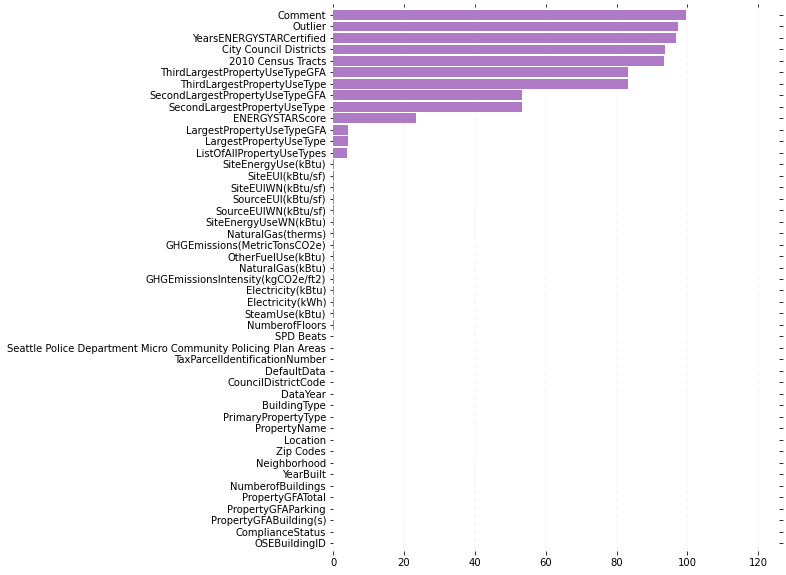

In [11]:
nan_values2015 = df_NRJ_2015.isna().sum()

nan_values2015 = nan_values2015.sort_values(ascending=True)*100/df_NRJ_2015.shape[0]

ax = nan_values2015.plot(kind='barh', 
                     figsize=(8, 10), 
                     color='#AF7AC5',
                     zorder=2,
                     width=0.85)

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis="both", 
               which="both", 
               bottom="off", 
               top="off", 
               labelbottom="on", 
               left="off", 
               right="off", 
               labelleft="on")

vals = ax.get_xticks()

for tick in vals:
  ax.axvline(x=tick, linestyle='dashed', alpha=0.4, color='#eeeeee', zorder=1)

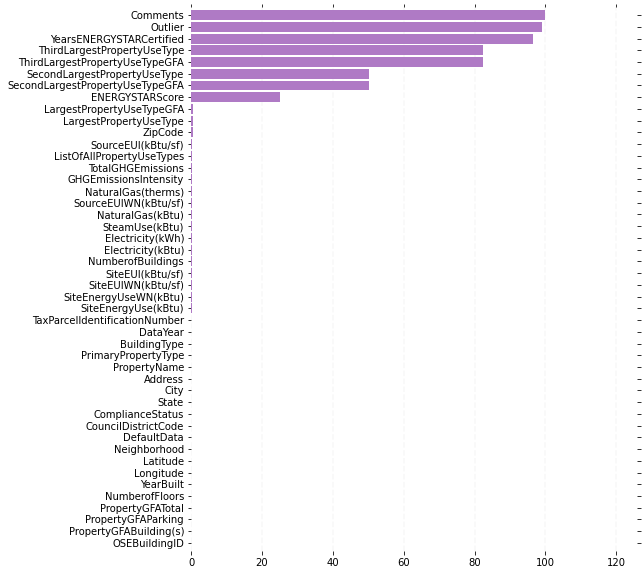

In [12]:
nan_values2016 = df_NRJ_2016.isna().sum()

nan_values2016 = nan_values2016.sort_values(ascending=True)*100/df_NRJ_2016.shape[0]

ax = nan_values2016.plot(kind='barh', 
                     figsize=(8, 10), 
                     color='#AF7AC5',
                     zorder=2,
                     width=0.85)

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis="both", 
               which="both", 
               bottom="off", 
               top="off", 
               labelbottom="on", 
               left="off", 
               right="off", 
               labelleft="on")

vals = ax.get_xticks()

for tick in vals:
  ax.axvline(x=tick, linestyle='dashed', alpha=0.4, color='#eeeeee', zorder=1)

In [13]:
nan_values2015

OSEBuildingID                                                     0.000000
ComplianceStatus                                                  0.000000
PropertyGFABuilding(s)                                            0.000000
PropertyGFAParking                                                0.000000
PropertyGFATotal                                                  0.000000
NumberofBuildings                                                 0.000000
YearBuilt                                                         0.000000
Neighborhood                                                      0.000000
Zip Codes                                                         0.000000
Location                                                          0.000000
PropertyName                                                      0.000000
PrimaryPropertyType                                               0.000000
BuildingType                                                      0.000000
DataYear                 

In [14]:
nan_values2016

OSEBuildingID                        0.000000
PropertyGFABuilding(s)               0.000000
PropertyGFAParking                   0.000000
PropertyGFATotal                     0.000000
NumberofFloors                       0.000000
YearBuilt                            0.000000
Longitude                            0.000000
Latitude                             0.000000
Neighborhood                         0.000000
DefaultData                          0.000000
CouncilDistrictCode                  0.000000
ComplianceStatus                     0.000000
State                                0.000000
City                                 0.000000
Address                              0.000000
PropertyName                         0.000000
PrimaryPropertyType                  0.000000
BuildingType                         0.000000
DataYear                             0.000000
TaxParcelIdentificationNumber        0.000000
SiteEnergyUse(kBtu)                  0.148104
SiteEnergyUseWN(kBtu)             

In [15]:
df_NRJ_2015['ThirdLargestPropertyUseTypeGFA']=df_NRJ_2015['ThirdLargestPropertyUseTypeGFA'].replace({np.nan:0})

In [16]:
df_NRJ_2016['ThirdLargestPropertyUseTypeGFA']=df_NRJ_2016['ThirdLargestPropertyUseTypeGFA'].replace({np.nan:0})

In [17]:
df_NRJ_2015['SecondLargestPropertyUseTypeGFA']=df_NRJ_2015['SecondLargestPropertyUseTypeGFA'].replace({np.nan:0})

In [18]:
df_NRJ_2016['SecondLargestPropertyUseTypeGFA']=df_NRJ_2016['SecondLargestPropertyUseTypeGFA'].replace({np.nan:0})

In [19]:
df_NRJ_2015.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),DefaultData,Comment,ComplianceStatus,Outlier,2010 Census Tracts,Seattle Police Department Micro Community Policing Plan Areas,City Council Districts,SPD Beats,Zip Codes
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,"{'latitude': '47.61219025', 'longitude': '-122.33799744', 'human_address': '{""address"": ""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1927,1,12.0,88434,0,88434,Hotel,Hotel,88434.0,NaN,0.0,NaN,0.0,NaN,65.0,78.9,80.3,173.5,175.1,6981428.0,7097539.0,2023032.0,1080307.0,3686160.0,12724.0,1272388.0,0.0,249.43,2.64,No,NaN,Compliant,NaN,NaN,14.0,NaN,31.0,18081
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,"{'latitude': '47.61310583', 'longitude': '-122.33335756', 'human_address': '{""address"": ""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1996,1,11.0,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,51.0,94.4,99.0,191.3,195.2,8354235.0,8765788.0,0.0,1144563.0,3905411.0,44490.0,4448985.0,0.0,263.51,2.38,No,NaN,Compliant,NaN,NaN,14.0,NaN,31.0,18081
2,3,2015,NonResidential,Hotel,WESTIN HOTEL,659000475,"{'latitude': '47.61334897', 'longitude': '-122.33769944', 'human_address': '{""address"": ""1900 5TH AVE"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1969,1,41.0,961990,0,961990,"Hotel, Parking, Swimming Pool",Hotel,757243.0,Parking,100000.0,Swimming Pool,0.0,NaN,18.0,96.6,99.7,242.7,246.5,73130656.0,75506272.0,19660404.0,14583930.0,49762435.0,37099.0,3709900.0,0.0,2061.48,1.92,Yes,NaN,Compliant,NaN,NaN,56.0,NaN,31.0,18081
3,5,2015,NonResidential,Hotel,HOTEL MAX,659000640,"{'latitude': '47.61421585', 'longitude': '-122.33660889', 'human_address': '{""address"": ""620 STEWART ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1926,1,10.0,61320,0,61320,Hotel,Hotel,61320.0,NaN,0.0,NaN,0.0,NaN,1.0,460.4,462.5,636.3,643.2,28229320.0,28363444.0,23458518.0,811521.0,2769023.0,20019.0,2001894.0,0.0,1936.34,31.38,No,NaN,Compliant,High Outlier,NaN,56.0,NaN,31.0,18081
4,8,2015,NonResidential,Hotel,WARWICK SEATTLE HOTEL,659000970,"{'latitude': '47.6137544', 'longitude': '-122.3409238', 'human_address': '{""address"": ""401 LENORA ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98121""}'}",7,DOWNTOWN,1980,1,18.0,119890,12460,107430,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,67.0,120.1,122.1,228.8,227.1,14829099.0,15078243.0,0.0,1777841.0,6066245.0,87631.0,8763105.0,0.0,507.70,4.02,No,NaN,Compliant,NaN,NaN,56.0,NaN,31.0,19576


In [20]:
# We set a 20% threshold
# so we remove:
# for 2015: '2010 Census Tracts','City Council Districts','YearsENERGYSTARCertified','Outlier','Comment',ThirdLargestPropertyUseType','ThirdLargestPropertyUseTypeGFA'
# for 2016: 'ThirdLargestPropertyUseTypeGFA','ThirdLargestPropertyUseType','YearsENERGYSTARCertified','Outlier','Comments'


nan2015=['2010 Census Tracts','City Council Districts','YearsENERGYSTARCertified','Outlier','Comment',
         'ThirdLargestPropertyUseType']

nan2016=['ThirdLargestPropertyUseType','YearsENERGYSTARCertified','Outlier','Comments']


df_NRJ_2015=df_NRJ_2015.drop(columns=nan2015)
df_NRJ_2016=df_NRJ_2016.drop(columns=nan2016)

In [21]:
#df_NRJ_2016=df_NRJ_2016.drop(columns=nan2016)

In [22]:
df_NRJ_2015.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),DefaultData,ComplianceStatus,Seattle Police Department Micro Community Policing Plan Areas,SPD Beats,Zip Codes
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,"{'latitude': '47.61219025', 'longitude': '-122.33799744', 'human_address': '{""address"": ""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1927,1,12.0,88434,0,88434,Hotel,Hotel,88434.0,NaN,0.0,0.0,65.0,78.9,80.3,173.5,175.1,6981428.0,7097539.0,2023032.0,1080307.0,3686160.0,12724.0,1272388.0,0.0,249.43,2.64,No,Compliant,14.0,31.0,18081
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,"{'latitude': '47.61310583', 'longitude': '-122.33335756', 'human_address': '{""address"": ""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1996,1,11.0,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,4622.0,51.0,94.4,99.0,191.3,195.2,8354235.0,8765788.0,0.0,1144563.0,3905411.0,44490.0,4448985.0,0.0,263.51,2.38,No,Compliant,14.0,31.0,18081
2,3,2015,NonResidential,Hotel,WESTIN HOTEL,659000475,"{'latitude': '47.61334897', 'longitude': '-122.33769944', 'human_address': '{""address"": ""1900 5TH AVE"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1969,1,41.0,961990,0,961990,"Hotel, Parking, Swimming Pool",Hotel,757243.0,Parking,100000.0,0.0,18.0,96.6,99.7,242.7,246.5,73130656.0,75506272.0,19660404.0,14583930.0,49762435.0,37099.0,3709900.0,0.0,2061.48,1.92,Yes,Compliant,56.0,31.0,18081
3,5,2015,NonResidential,Hotel,HOTEL MAX,659000640,"{'latitude': '47.61421585', 'longitude': '-122.33660889', 'human_address': '{""address"": ""620 STEWART ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",7,DOWNTOWN,1926,1,10.0,61320,0,61320,Hotel,Hotel,61320.0,NaN,0.0,0.0,1.0,460.4,462.5,636.3,643.2,28229320.0,28363444.0,23458518.0,811521.0,2769023.0,20019.0,2001894.0,0.0,1936.34,31.38,No,Compliant,56.0,31.0,18081
4,8,2015,NonResidential,Hotel,WARWICK SEATTLE HOTEL,659000970,"{'latitude': '47.6137544', 'longitude': '-122.3409238', 'human_address': '{""address"": ""401 LENORA ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98121""}'}",7,DOWNTOWN,1980,1,18.0,119890,12460,107430,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,0.0,67.0,120.1,122.1,228.8,227.1,14829099.0,15078243.0,0.0,1777841.0,6066245.0,87631.0,8763105.0,0.0,507.70,4.02,No,Compliant,56.0,31.0,19576


In [23]:
df_NRJ_2015.dtypes

OSEBuildingID                                                      int64
DataYear                                                           int64
BuildingType                                                      object
PrimaryPropertyType                                               object
PropertyName                                                      object
TaxParcelIdentificationNumber                                     object
Location                                                          object
CouncilDistrictCode                                                int64
Neighborhood                                                      object
YearBuilt                                                          int64
NumberofBuildings                                                  int64
NumberofFloors                                                   float64
PropertyGFATotal                                                   int64
PropertyGFAParking                                 

In [24]:
df_NRJ_2015.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'PropertyName', 'TaxParcelIdentificationNumber', 'Location', 'CouncilDistrictCode', 'Neighborhood', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 'OtherFuelUse(kBtu)', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 'DefaultData', 'ComplianceStatus', 'Seattle Police Department Micro Community Policing Plan Areas', 'SPD Beats', 'Zip Codes'], dtype='object')

In [25]:
df_NRJ_2015=df_NRJ_2015[['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'PropertyName', 'TaxParcelIdentificationNumber', 
                         'Location', 'DefaultData', 'Zip Codes', 'CouncilDistrictCode',
                         'SecondLargestPropertyUseType','ListOfAllPropertyUseTypes',
                         'LargestPropertyUseType','Neighborhood', 
                         'ComplianceStatus',  'YearBuilt', 
                         'NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                         'LargestPropertyUseTypeGFA', 'NumberofFloors', 
                         'SecondLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 
                         'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 
                         'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 
                         'OtherFuelUse(kBtu)', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 
                         'Seattle Police Department Micro Community Policing Plan Areas', 'SPD Beats']]

df_NRJ_2015.dtypes

OSEBuildingID                                                      int64
DataYear                                                           int64
BuildingType                                                      object
PrimaryPropertyType                                               object
PropertyName                                                      object
TaxParcelIdentificationNumber                                     object
Location                                                          object
DefaultData                                                       object
Zip Codes                                                          int64
CouncilDistrictCode                                                int64
SecondLargestPropertyUseType                                      object
ListOfAllPropertyUseTypes                                         object
LargestPropertyUseType                                            object
Neighborhood                                       

## Objectifs

In [26]:


# obj :
# 1. predict the CO2 emissions and total energy use
# of buildings for which they have not been measured yet.
# The prediction relies on the declarative data of the commercial operating permit
# (building size and use, recent works, year built...)



# 2. assess the value of the "ENERGY STAR Score" for predicting emissions,
# which is tedious to compute with the team's current approach.

# Which features to predict?

## PCA

In [27]:
# encode discrete values as continuous values

In [28]:
from sklearn import decomposition
from sklearn import preprocessing

from functions_Copy8 import *

os.path.abspath("functions.py")

'.\\functions.py'

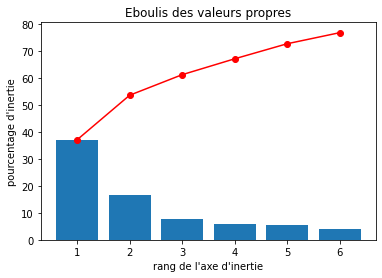

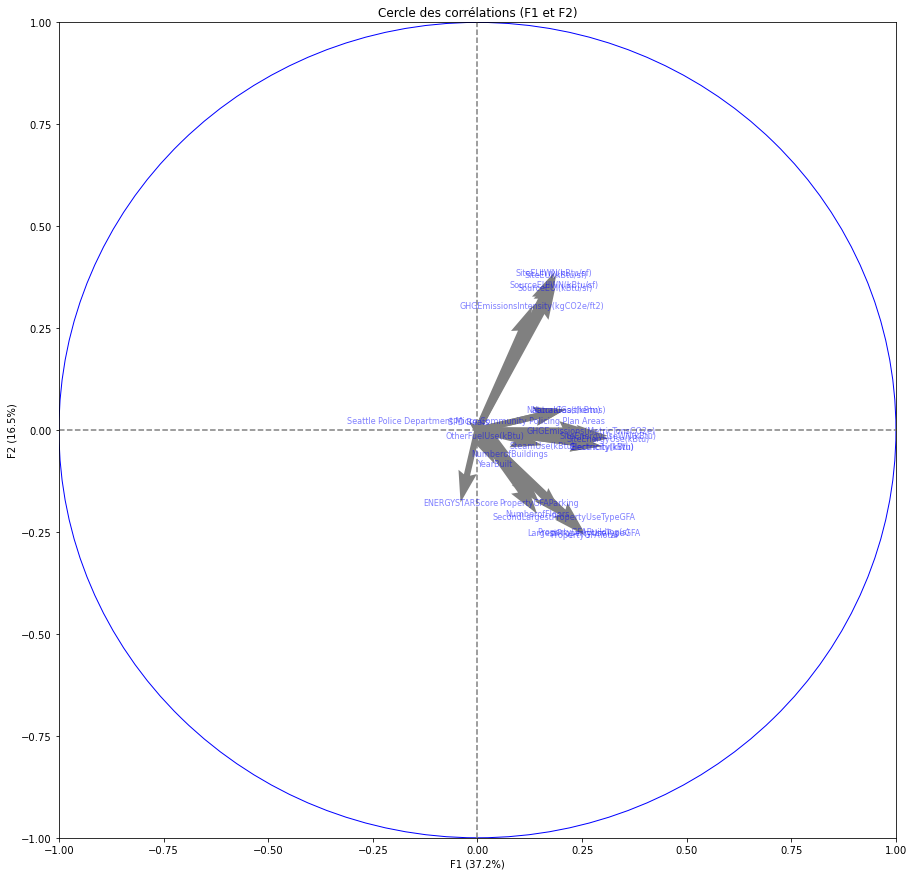

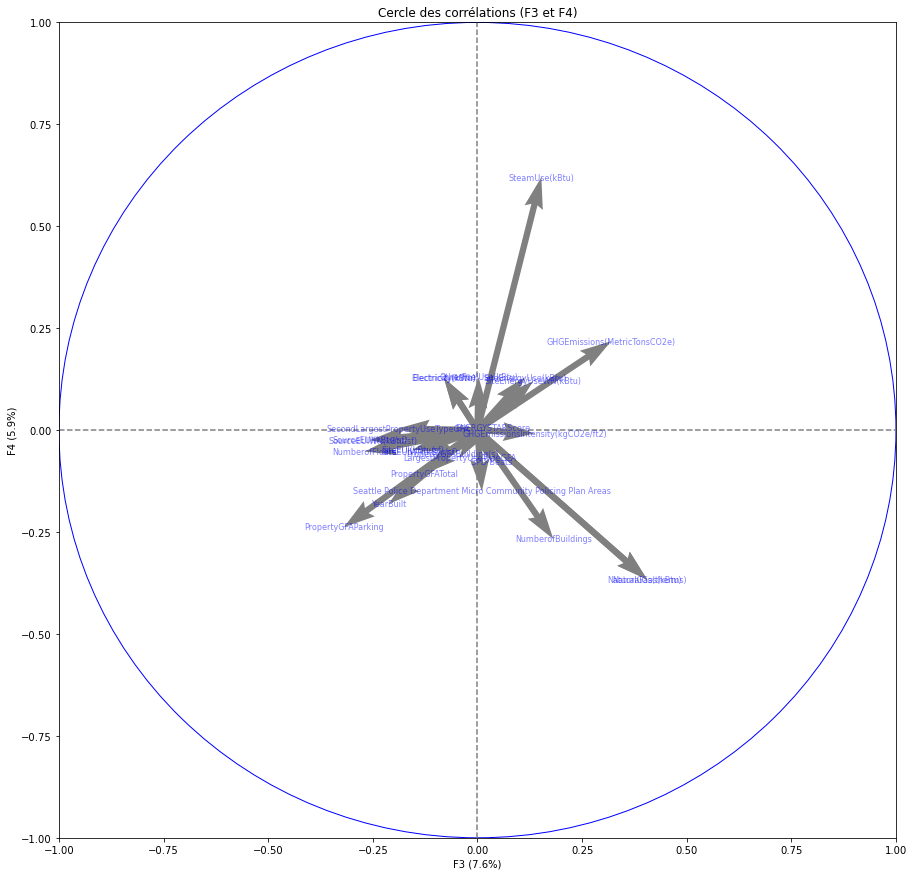

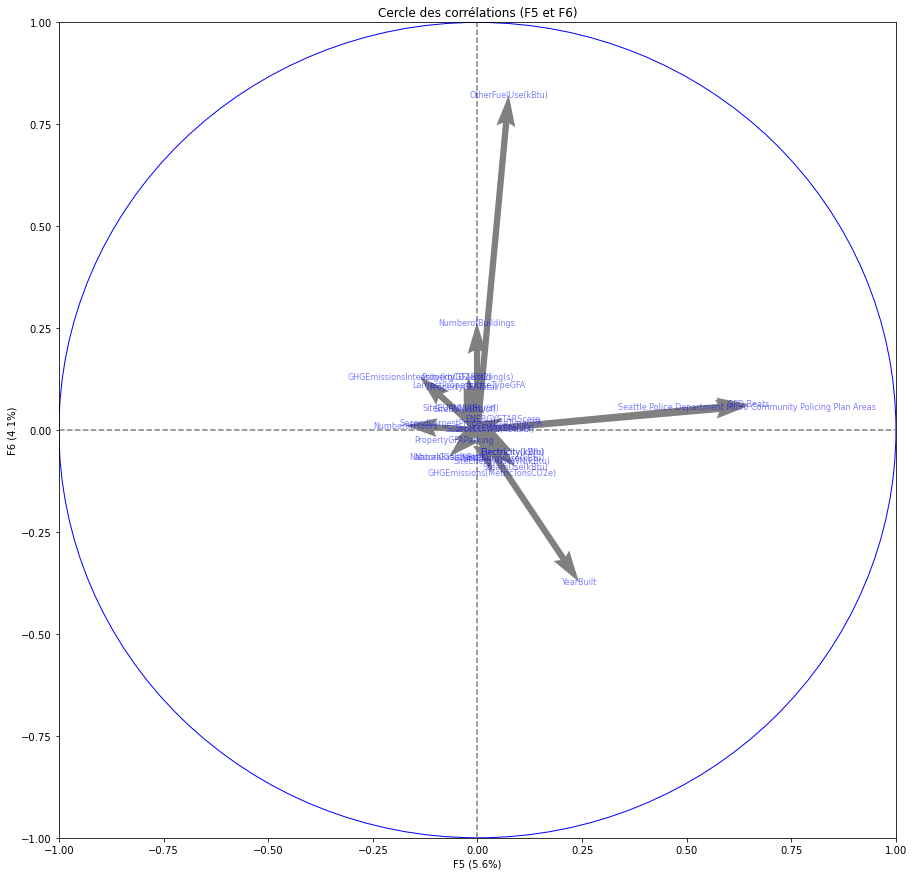

In [29]:
# choose the number of components to compute
n_comp = 6

list_21=['YearBuilt', 
                         'NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                         'LargestPropertyUseTypeGFA', 'NumberofFloors', 
                         'SecondLargestPropertyUseTypeGFA','ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 
                         'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 
                         'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 
                         'OtherFuelUse(kBtu)', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 
                         'Seattle Police Department Micro Community Policing Plan Areas', 'SPD Beats']


# select the columns used in the PCA
data_pca = df_NRJ_2015[list_21]

# Nutri_score grade :
#nutri = [df_NRJ_2015.loc[Id, 'nutriscore_grade'] for Id in data_pca.index]

# prepare the data for the PCA
data_pca = data_pca.fillna(data_pca.mean()) # Unknown values are often replaced by the variable's mean
X = data_pca.values
#names = df7_noNa["product_name"] # or data.index to get the labels
features = data_pca.columns

# Centring and scaling
std_scale = preprocessing.StandardScaler().fit(X)
X_scaled = std_scale.transform(X)

# Compute the principal components
pca = decomposition.PCA(n_components=n_comp)
pca.fit(X_scaled)

# Scree plot
display_scree_plot(pca)

# Correlation circle
pcs = pca.components_
display_circles(pcs, n_comp, pca, [(0,1),(2,3),(4,5)], labels = np.array(features))


plt.show()


# --------------------------------




<AxesSubplot:>

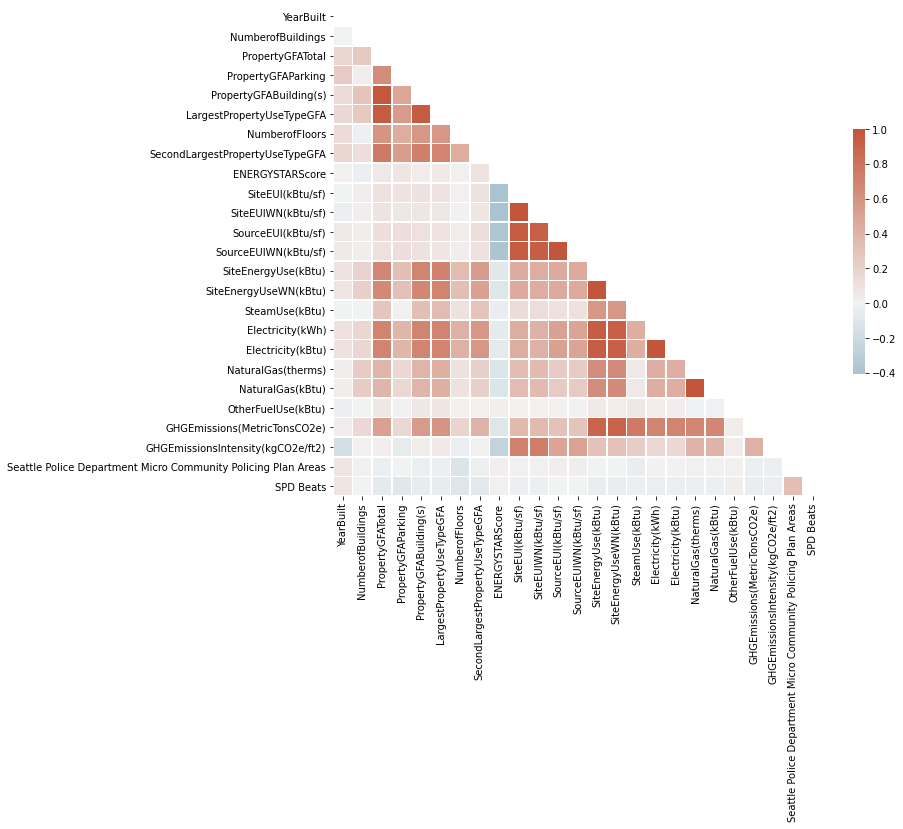

In [30]:
dfcorr=df_NRJ_2015[['YearBuilt','NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                         'LargestPropertyUseTypeGFA', 'NumberofFloors', 
                         'SecondLargestPropertyUseTypeGFA','ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 
                         'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 
                         'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 
                         'OtherFuelUse(kBtu)', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 
                         'Seattle Police Department Micro Community Policing Plan Areas', 'SPD Beats']]


corr = dfcorr.corr()

corr


# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [31]:
corr

,YearBuilt,NumberofBuildings,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,NumberofFloors,SecondLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats
YearBuilt,1.000000,-0.004222,0.181080,0.248852,0.141241,0.159239,0.142683,0.171239,0.011589,-0.008990,-0.025789,0.057837,0.051472,0.085684,0.081467,0.001868,0.110454,0.110454,0.028143,0.028143,-0.022980,0.035245,-0.159084,0.077662,0.075032
NumberofBuildings,-0.004222,1.000000,0.262966,0.033448,0.294679,0.260629,-0.017514,0.121005,-0.023697,0.027440,0.029103,0.026978,0.027914,0.194295,0.211656,-0.003271,0.167999,0.167999,0.245667,0.245667,-0.001656,0.165773,0.017461,0.009453,-0.008761
PropertyGFATotal,0.181080,0.262966,1.000000,0.648706,0.978159,0.954736,0.596612,0.754902,0.056831,0.106480,0.087989,0.127974,0.111642,0.678425,0.662026,0.284826,0.697844,0.697844,0.381319,0.381319,0.062270,0.518440,0.022912,-0.025815,-0.065763
PropertyGFAParking,0.248852,0.033448,0.648706,1.000000,0.476348,0.553280,0.445613,0.531953,0.079775,0.086773,0.072167,0.127134,0.117201,0.326776,0.315039,0.012191,0.390832,0.390832,0.165459,0.165459,0.005551,0.166104,-0.056237,-0.002896,-0.086471
PropertyGFABuilding(s),0.141241,0.294679,0.978159,0.476348,1.000000,0.951616,0.567785,0.726876,0.044616,0.099318,0.081945,0.113127,0.096971,0.694545,0.678805,0.325735,0.699484,0.699484,0.395353,0.395353,0.070426,0.553595,0.041830,-0.029034,-0.052361
LargestPropertyUseTypeGFA,0.159239,0.260629,0.954736,0.553280,0.951616,1.000000,0.579017,0.695961,0.056182,0.084313,0.068482,0.094334,0.079677,0.705917,0.694755,0.346079,0.696225,0.696225,0.426108,0.426107,0.081979,0.583793,0.052804,-0.025979,-0.048277
NumberofFloors,0.142683,-0.017514,0.596612,0.445613,0.567785,0.579017,1.000000,0.444142,0.012372,0.015420,0.002801,0.040549,0.032039,0.343528,0.327366,0.096026,0.411062,0.411062,0.107321,0.107321,0.011808,0.191113,-0.033674,-0.118129,-0.105375
SecondLargestPropertyUseTypeGFA,0.171239,0.121005,0.754902,0.531953,0.726876,0.695961,0.444142,1.000000,0.088846,0.100464,0.082355,0.129498,0.114586,0.541671,0.522550,0.290508,0.576130,0.576130,0.215424,0.215424,0.013972,0.407436,0.010074,-0.017761,-0.077594
ENERGYSTARScore,0.011589,-0.023697,0.056831,0.079775,0.044616,0.056182,0.012372,0.088846,1.000000,-0.394656,-0.403965,-0.375381,-0.386972,-0.090146,-0.096485,-0.041915,-0.064731,-0.064731,-0.113095,-0.113095,0.023561,-0.097862,-0.262729,0.019838,0.010814
SiteEUI(kBtu/sf),-0.008990,0.027440,0.106480,0.086773,0.099318,0.084313,0.015420,0.100464,-0.394656,1.000000,0.995946,0.950709,0.953012,0.451255,0.451588,0.136801,0.440049,0.440049,0.348296,0.348296,0.016998,0.360583,0.721475,0.014941,-0.020929


## This shows which variables are correlated, so we can already consider removing some of them

In [32]:
## Reminder of the objectives:

# obj :
# 1. predict the CO2 emissions and total energy use
# of buildings for which they have not been measured yet.
# The prediction relies on the declarative data of the commercial operating permit
# (building size and use, recent works, year built...)



# 2. assess the value of the "ENERGY STAR Score" for predicting emissions,
# which is tedious to compute with the team's current approach.

In [33]:
df_NRJ_2015.isna().sum()

OSEBuildingID                                                       0
DataYear                                                            0
BuildingType                                                        0
PrimaryPropertyType                                                 0
PropertyName                                                        0
TaxParcelIdentificationNumber                                       2
Location                                                            0
DefaultData                                                         1
Zip Codes                                                           0
CouncilDistrictCode                                                 0
SecondLargestPropertyUseType                                     1781
ListOfAllPropertyUseTypes                                         127
LargestPropertyUseType                                            136
Neighborhood                                                        0
ComplianceStatus    

In [5]:
df_NRJ_2016.isna().sum()

OSEBuildingID                         0
DataYear                              0
BuildingType                          0
PrimaryPropertyType                   0
PropertyName                          0
Address                               0
City                                  0
State                                 0
ZipCode                              16
TaxParcelIdentificationNumber         0
CouncilDistrictCode                   0
Neighborhood                          0
Latitude                              0
Longitude                             0
YearBuilt                             0
NumberofBuildings                     8
NumberofFloors                        0
PropertyGFATotal                      0
PropertyGFAParking                    0
PropertyGFABuilding(s)                0
ListOfAllPropertyUseTypes             9
LargestPropertyUseType               20
LargestPropertyUseTypeGFA            20
SecondLargestPropertyUseType       1697
SecondLargestPropertyUseTypeGFA    1697


1.1. CO2 emissions: 10 rows are incomplete


GHGEmissions(MetricTonsCO2e)  
GHGEmissionsIntensity(kgCO2e/ft2)

--> we choose GHGEmissions(MetricTonsCO2e)



1.2. Total energy use: 10 rows are incomplete

SiteEUI(kBtu/sf)                                                   
SiteEUIWN(kBtu/sf)                                                 
SourceEUI(kBtu/sf)                                                 
SourceEUIWN(kBtu/sf)                                      
SiteEnergyUse(kBtu)                                         
SiteEnergyUseWN(kBtu)                                           
SteamUse(kBtu)                                                    
Electricity(kWh)                                                   
Electricity(kBtu) 


--> we choose SiteEnergyUse(kBtu)

In [34]:
df_NRJ_2015.dtypes

OSEBuildingID                                                      int64
DataYear                                                           int64
BuildingType                                                      object
PrimaryPropertyType                                               object
PropertyName                                                      object
TaxParcelIdentificationNumber                                     object
Location                                                          object
DefaultData                                                       object
Zip Codes                                                          int64
CouncilDistrictCode                                                int64
SecondLargestPropertyUseType                                      object
ListOfAllPropertyUseTypes                                         object
LargestPropertyUseType                                            object
Neighborhood                                       

In [35]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,DefaultData,Zip Codes,CouncilDistrictCode,SecondLargestPropertyUseType,ListOfAllPropertyUseTypes,LargestPropertyUseType,Neighborhood,ComplianceStatus,YearBuilt,NumberofBuildings,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,NumberofFloors,SecondLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,"{'latitude': '47.61219025', 'longitude': '-122.33799744', 'human_address': '{""address"": ""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",No,18081,7,NaN,Hotel,Hotel,DOWNTOWN,Compliant,1927,1,88434,0,88434,88434.0,12.0,0.0,65.0,78.9,80.3,173.5,175.1,6981428.0,7097539.0,2023032.0,1080307.0,3686160.0,12724.0,1272388.0,0.0,249.43,2.64,14.0,31.0
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,"{'latitude': '47.61310583', 'longitude': '-122.33335756', 'human_address': '{""address"": ""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",No,18081,7,Parking,"Hotel, Parking, Restaurant",Hotel,DOWNTOWN,Compliant,1996,1,103566,15064,88502,83880.0,11.0,15064.0,51.0,94.4,99.0,191.3,195.2,8354235.0,8765788.0,0.0,1144563.0,3905411.0,44490.0,4448985.0,0.0,263.51,2.38,14.0,31.0


In [36]:
df_NRJ_2015['TaxParcelIdentificationNumber'].value_counts()

925049346     5
3224049012    5
2400002       5
8632880000    4
7666203240    4
             ..
8592900345    1
1825049055    1
6851700060    1
1887550000    1
2771108040    1
Name: TaxParcelIdentificationNumber, Length: 3245, dtype: int64

In [37]:
df_NRJ_2015[df_NRJ_2015['NumberofBuildings']==2]

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,DefaultData,Zip Codes,CouncilDistrictCode,SecondLargestPropertyUseType,ListOfAllPropertyUseTypes,LargestPropertyUseType,Neighborhood,ComplianceStatus,YearBuilt,NumberofBuildings,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,NumberofFloors,SecondLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats
1884,23637,2015,Multifamily LR (1-4),Low-Rise Multifamily,J&E APTS,7701400030,"{'latitude': '47.53115578', 'longitude': '-122.2695897', 'human_address': '{""address"": ""7910 RAINIER AVE S"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98118""}'}",No,18800,2,NaN,Multifamily Housing,Multifamily Housing,SOUTHEAST,Compliant,1956,2,21708,0,21708,21708.0,2.0,0.0,59.0,60.6,72.7,102.2,114.8,1315298.0,1577240.0,0.0,117310.0,400280.0,9150.0,915035.0,0.0,51.39,2.29,7.0,45.0
1944,23846,2015,NonResidential,Small- and Mid-Sized Office,DIAMOND BUILDING,7666202225,"{'latitude': '47.61843872', 'longitude': '-122.35874939', 'human_address': '{""address"": ""3161 ELLIOTT AVE"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98121""}'}",No,19576,7,NaN,Office,Office,DOWNTOWN,Compliant,1979,2,34030,0,34030,34030.0,3.0,0.0,49.0,51.6,53.4,150.6,151.7,1757194.0,1818828.0,0.0,459720.0,1568628.0,1886.0,188631.0,0.0,20.95,0.42,5.0,9.0
2193,24659,2015,Multifamily LR (1-4),Low-Rise Multifamily,CARROLL AND KENSINGTON APTS,6847700395,"{'latitude': '47.62129098', 'longitude': '-122.3269098', 'human_address': '{""address"": ""305 BELLEVUE AVE E"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98102""}'}",No,18376,3,Parking,"Multifamily Housing, Parking",Multifamily Housing,EAST,Compliant,1908,2,74516,23222,51294,51294.0,4.0,23222.0,89.0,28.9,31.6,86.3,94.5,1482997.0,1621055.0,0.0,402067.0,1371908.0,1111.0,111146.0,0.0,15.47,0.13,8.0,5.0
2570,26007,2015,Multifamily LR (1-4),Low-Rise Multifamily,BOLYSTON COURT APTS,8804900045,"{'latitude': '47.61669266', 'longitude': '-122.3228535', 'human_address': '{""address"": ""700 E OLIVE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98122""}'}",No,19578,3,Parking,"Multifamily Housing, Parking",Multifamily Housing,EAST,Compliant,1948,2,31457,10384,21073,21073.0,2.0,0.0,86.0,56.2,65.0,83.2,92.5,1183967.0,1370487.0,0.0,71680.0,244583.0,9394.0,939394.0,0.0,51.60,1.61,8.0,11.0
3219,49721,2015,Multifamily LR (1-4),Low-Rise Multifamily,WEST NEWTON FLATS,2771604405,"{'latitude': '47.63658205', 'longitude': '-122.3866334', 'human_address': '{""address"": ""2301 W NEWTON ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98199""}'}",Yes,18235,7,NaN,Multifamily Housing,Multifamily Housing,MAGNOLIA / QUEEN ANNE,Compliant,2012,2,21753,10642,11111,21753.0,3.0,0.0,41.0,37.3,43.1,101.6,114.1,812422.0,937637.0,0.0,190319.0,649395.0,1631.0,163054.0,0.0,13.19,0.48,33.0,27.0


#Variables to remove:

PropertyGFAParking and PropertyGFABuilding(s)    (PropertyGFATotal is their sum)

LargestPropertyUseTypeGFA takes the max of the two values above

SecondLargestPropertyUseTypeGFA takes the second max of the two values above.

SiteEUIWN(kBtu/sf) (same as SiteEUI, but weather-normalised)

SourceEUIWN(kBtu/sf) (same as SourceEUI, but weather-normalised)

SiteEnergyUseWN(kBtu) (same as SiteEnergyUse, but weather-normalised)

Electricity(kWh) (same as Electricity(kBtu), different unit)

NaturalGas(therms) (same as NaturalGas(kBtu), different unit)

SecondLargestPropertyUseType, ListOfAllPropertyUseTypes and LargestPropertyUseType (we keep PrimaryPropertyType, which summarises them)


In [38]:
drop_2015 = ['PropertyGFAParking','PropertyGFABuilding(s)','SiteEUIWN(kBtu/sf)','LargestPropertyUseTypeGFA','SecondLargestPropertyUseTypeGFA',
            'SourceEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)','Electricity(kWh)','NaturalGas(therms)',
            'SecondLargestPropertyUseType','ListOfAllPropertyUseTypes','LargestPropertyUseType']

<AxesSubplot:>

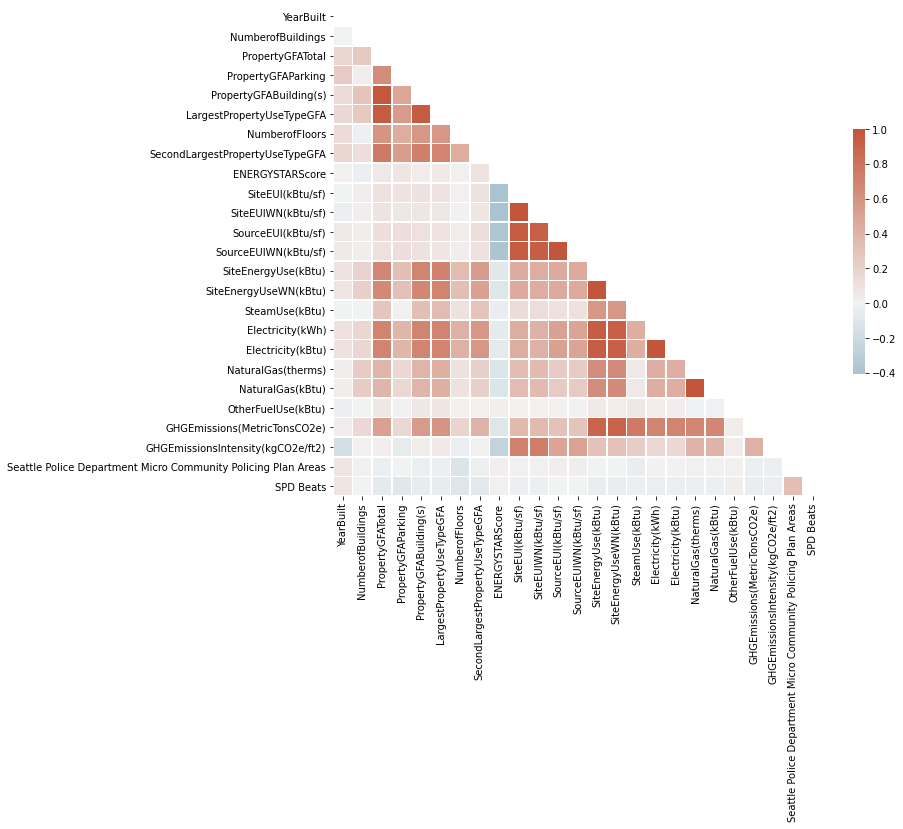

In [39]:
dfcorr=df_NRJ_2015[['YearBuilt','NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                         'LargestPropertyUseTypeGFA', 'NumberofFloors', 
                         'SecondLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 
                         'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 
                         'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 
                         'OtherFuelUse(kBtu)', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 
                         'Seattle Police Department Micro Community Policing Plan Areas', 'SPD Beats']]


corr = dfcorr.corr()

corr


# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [40]:
df_NRJ_2016.dtypes

OSEBuildingID                        int64
DataYear                             int64
BuildingType                        object
PrimaryPropertyType                 object
PropertyName                        object
Address                             object
City                                object
State                               object
ZipCode                            float64
TaxParcelIdentificationNumber       object
CouncilDistrictCode                  int64
Neighborhood                        object
Latitude                           float64
Longitude                          float64
YearBuilt                            int64
NumberofBuildings                  float64
NumberofFloors                       int64
PropertyGFATotal                     int64
PropertyGFAParking                   int64
PropertyGFABuilding(s)               int64
ListOfAllPropertyUseTypes           object
LargestPropertyUseType              object
LargestPropertyUseTypeGFA          float64
SecondLarge

In [41]:
df_NRJ_2016.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,ComplianceStatus,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,0.0,0.0,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,Compliant,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,4622.0,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,Compliant,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,0.0,0.0,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,Compliant,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,0.0,0.0,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,Compliant,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,0.0,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,Compliant,505.01,2.88


<AxesSubplot:>

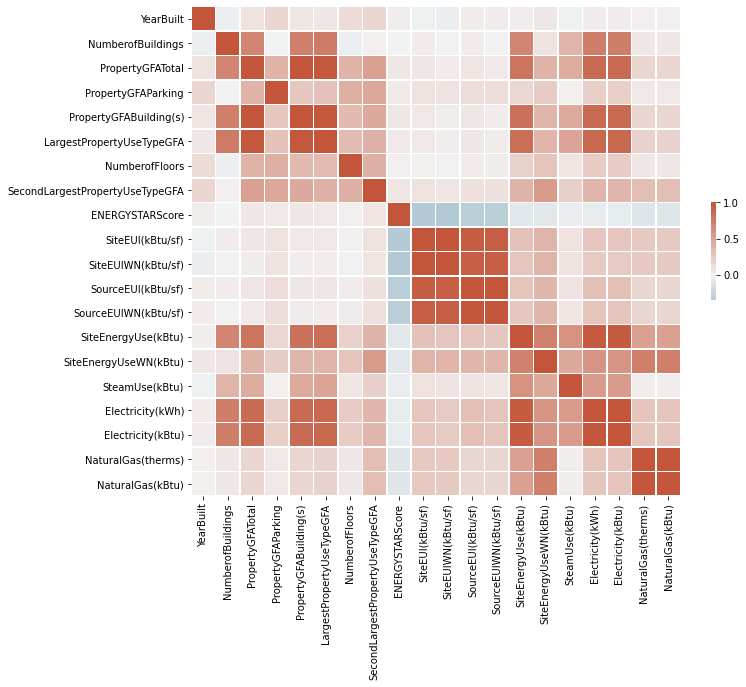

In [42]:
dfcorr2016=df_NRJ_2016[['YearBuilt','NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                         'LargestPropertyUseTypeGFA', 'NumberofFloors', 
                         'SecondLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 
                         'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 
                         'SteamUse(kBtu)', 'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)']]


corr2016 = dfcorr2016.corr()

corr2016


# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr2016,  cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .2})

In [43]:
df_NRJ_2015.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,Location,DefaultData,Zip Codes,CouncilDistrictCode,SecondLargestPropertyUseType,ListOfAllPropertyUseTypes,LargestPropertyUseType,Neighborhood,ComplianceStatus,YearBuilt,NumberofBuildings,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,NumberofFloors,SecondLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,"{'latitude': '47.61219025', 'longitude': '-122.33799744', 'human_address': '{""address"": ""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",No,18081,7,NaN,Hotel,Hotel,DOWNTOWN,Compliant,1927,1,88434,0,88434,88434.0,12.0,0.0,65.0,78.9,80.3,173.5,175.1,6981428.0,7097539.0,2023032.0,1080307.0,3686160.0,12724.0,1272388.0,0.0,249.43,2.64,14.0,31.0
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,"{'latitude': '47.61310583', 'longitude': '-122.33335756', 'human_address': '{""address"": ""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",No,18081,7,Parking,"Hotel, Parking, Restaurant",Hotel,DOWNTOWN,Compliant,1996,1,103566,15064,88502,83880.0,11.0,15064.0,51.0,94.4,99.0,191.3,195.2,8354235.0,8765788.0,0.0,1144563.0,3905411.0,44490.0,4448985.0,0.0,263.51,2.38,14.0,31.0
2,3,2015,NonResidential,Hotel,WESTIN HOTEL,659000475,"{'latitude': '47.61334897', 'longitude': '-122.33769944', 'human_address': '{""address"": ""1900 5TH AVE"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",Yes,18081,7,Parking,"Hotel, Parking, Swimming Pool",Hotel,DOWNTOWN,Compliant,1969,1,961990,0,961990,757243.0,41.0,100000.0,18.0,96.6,99.7,242.7,246.5,73130656.0,75506272.0,19660404.0,14583930.0,49762435.0,37099.0,3709900.0,0.0,2061.48,1.92,56.0,31.0
3,5,2015,NonResidential,Hotel,HOTEL MAX,659000640,"{'latitude': '47.61421585', 'longitude': '-122.33660889', 'human_address': '{""address"": ""620 STEWART ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",No,18081,7,NaN,Hotel,Hotel,DOWNTOWN,Compliant,1926,1,61320,0,61320,61320.0,10.0,0.0,1.0,460.4,462.5,636.3,643.2,28229320.0,28363444.0,23458518.0,811521.0,2769023.0,20019.0,2001894.0,0.0,1936.34,31.38,56.0,31.0
4,8,2015,NonResidential,Hotel,WARWICK SEATTLE HOTEL,659000970,"{'latitude': '47.6137544', 'longitude': '-122.3409238', 'human_address': '{""address"": ""401 LENORA ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98121""}'}",No,19576,7,Parking,"Hotel, Parking, Swimming Pool",Hotel,DOWNTOWN,Compliant,1980,1,119890,12460,107430,123445.0,18.0,68009.0,67.0,120.1,122.1,228.8,227.1,14829099.0,15078243.0,0.0,1777841.0,6066245.0,87631.0,8763105.0,0.0,507.70,4.02,56.0,31.0


#Variables to remove:

PropertyGFAParking and PropertyGFABuilding(s)    (PropertyGFATotal is their sum)

LargestPropertyUseTypeGFA takes the max of the two values above

SecondLargestPropertyUseTypeGFA takes the second max of the two values above.

SiteEUIWN(kBtu/sf) (same as SiteEUI, but weather-normalised)

SourceEUIWN(kBtu/sf) (same as SourceEUI, but weather-normalised)

SiteEnergyUseWN(kBtu) (same as SiteEnergyUse, but weather-normalised)

Electricity(kWh) (same as Electricity(kBtu), different unit)

NaturalGas(therms) (same as NaturalGas(kBtu), different unit)

SecondLargestPropertyUseType, ListOfAllPropertyUseTypes and LargestPropertyUseType (we keep PrimaryPropertyType, which summarises them)

In [44]:
drop_2016 = ['PropertyGFAParking','PropertyGFABuilding(s)','SiteEUIWN(kBtu/sf)','LargestPropertyUseTypeGFA','SecondLargestPropertyUseTypeGFA',
            'SourceEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)','Electricity(kWh)','NaturalGas(therms)',
            'SecondLargestPropertyUseType','ListOfAllPropertyUseTypes','LargestPropertyUseType']

In [45]:
df_NRJ_2016.drop(drop_2016,axis='columns',inplace=True)

In [46]:
df_NRJ_2015.drop(drop_2015,axis='columns',inplace=True)

In [47]:
df_NRJ_2015.shape

(3340, 28)

In [48]:
df_NRJ_2016.shape

(3376, 30)

In [49]:
# What do we do with the nominal qualitative variables?

In [50]:
# first, split the location variable

df_NRJ_2016.head(10)

df_NRJ_2016.head(10)


df_NRJ_2015['split'] = df_NRJ_2015['Location'].str.split(':')
df_NRJ_2015

#df_NRJ_2015['G'] = df_NRJ_2015['F'].str.split(':')
#df_NRJ_2015

#df_NRJ_2015['H'], df_NRJ_2015['I'],df_NRJ_2015['J'],df_NRJ_2015['K'],df_NRJ_2015['L']= df_NRJ_2015['Location'].str.split(':', 4).str
#df_NRJ_2015

#df_NRJ_2015['M'], df_NRJ_2015['N'],df_NRJ_2015['O'],df_NRJ_2015['P']=df_NRJ_2015['L'].str.split(':', 4).str
df_NRJ_2015.head(2)

df_NRJ_2015.rename(columns={'I':'Latitude'},inplace=True)
df_NRJ_2015.rename(columns={'J':'Longitude'},inplace=True)
df_NRJ_2015.rename(columns={'M':'Address'},inplace=True)
df_NRJ_2015.rename(columns={'N':'City'},inplace=True)
df_NRJ_2015.rename(columns={'O':'State'},inplace=True)
df_NRJ_2015.rename(columns={'P':'ZipCode'},inplace=True)

df_NRJ_2015.drop(['H','K'],axis='columns',inplace=True)

df_NRJ_2015.head(2)

df_NRJ_2015['Longitude1']=df_NRJ_2015['Longitude'].str[:-18].str[2:]

df_NRJ_2015['Longitude1']

df_NRJ_2015['Latitude1']=df_NRJ_2015['Latitude'].str[:-14].str[2:]

df_NRJ_2015['Latitude1']

df_NRJ_2015['Address1']=df_NRJ_2015['Address'].str[:-9].str[2:]

df_NRJ_2015.head(2)

df_NRJ_2015['City1']=df_NRJ_2015['City'].str[:-10].str[2:]

df_NRJ_2015['City1']

df_NRJ_2015['State1']=df_NRJ_2015['State'].str[:-8].str[2:]

df_NRJ_2015['State1']

df_NRJ_2015['ZipCode1']=df_NRJ_2015['ZipCode'].str[:-4].str[2:]

df_NRJ_2015['ZipCode1']

df_NRJ_2015.head(2)

df_NRJ_2015.drop(['split','Longitude','Latitude','Address','City','State','ZipCode'],axis='columns',inplace=True)

df_NRJ_2015.rename(columns={'ZipCode1':'ZipCode'},inplace=True)
df_NRJ_2015.rename(columns={'State1':'State'},inplace=True)
df_NRJ_2015.rename(columns={'City1':'City'},inplace=True)
df_NRJ_2015.rename(columns={'Address1':'Address'},inplace=True)
df_NRJ_2015.rename(columns={'Latitude1':'Latitude'},inplace=True)
df_NRJ_2015.rename(columns={'Longitude1':'Longitude'},inplace=True)



df_NRJ_2015.head(2)

In [51]:
df_NRJ_2015.drop(['Location'],axis='columns',inplace=True)

In [52]:
# Use V2 from now on

In [53]:
# df_NRJ_2015.to_csv('2015-building-energy-benchmarking_V2.csv')


In [54]:
# df_NRJ_2015.to_csv('2015-building-energy-benchmarking_V2.csv')

In [55]:
df_NRJ_2015

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,DefaultData,Zip Codes,CouncilDistrictCode,Neighborhood,ComplianceStatus,YearBuilt,NumberofBuildings,PropertyGFATotal,NumberofFloors,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,No,18081,7,DOWNTOWN,Compliant,1927,1,88434,12.0,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,0.0,249.43,2.64,14.0,31.0
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,No,18081,7,DOWNTOWN,Compliant,1996,1,103566,11.0,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,0.0,263.51,2.38,14.0,31.0
2,3,2015,NonResidential,Hotel,WESTIN HOTEL,659000475,Yes,18081,7,DOWNTOWN,Compliant,1969,1,961990,41.0,18.0,96.6,242.7,73130656.0,19660404.0,49762435.0,3709900.0,0.0,2061.48,1.92,56.0,31.0
3,5,2015,NonResidential,Hotel,HOTEL MAX,659000640,No,18081,7,DOWNTOWN,Compliant,1926,1,61320,10.0,1.0,460.4,636.3,28229320.0,23458518.0,2769023.0,2001894.0,0.0,1936.34,31.38,56.0,31.0
4,8,2015,NonResidential,Hotel,WARWICK SEATTLE HOTEL,659000970,No,19576,7,DOWNTOWN,Compliant,1980,1,119890,18.0,67.0,120.1,228.8,14829099.0,0.0,6066245.0,8763105.0,0.0,507.70,4.02,56.0,31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3335,50049,2015,Multifamily LR (1-4),Low-Rise Multifamily,PACIFIC CENTER CONDOMINIUM,6599950000,No,18379,2,DOWNTOWN,Compliant,2000,1,44650,4.0,71.0,25.6,80.4,1142949.0,0.0,1142996.0,0.0,0.0,7.97,0.07,26.0,16.0
3336,50055,2015,Multifamily MR (5-9),Mid-Rise Multifamily,IDENTITY APTS 4123,1142001670,No,18383,4,NORTHEAST,Compliant,2014,1,42393,7.0,98.0,48.6,124.2,1543282.0,0.0,1111352.0,431976.0,0.0,30.69,0.61,60.0,38.0
3337,50057,2015,Multifamily HR (10+),High-Rise Multifamily,CIRRUS,660000575,No,19576,7,DOWNTOWN,Compliant,2015,1,319481,40.0,79.0,52.7,93.1,16834414.0,0.0,5767761.0,11066893.0,0.0,627.97,1.89,56.0,7.0
3338,50058,2015,Multifamily LR (1-4),Low-Rise Multifamily,WEDGEWOOD ESTATES BLDG A,6392001040,No,18792,4,NORTHEAST,Compliant,1981,1,48230,3.0,44.0,34.8,109.4,777064.0,0.0,777096.0,0.0,0.0,5.42,0.04,55.0,48.0


In [56]:
df_NRJ_2015 = pd.read_csv('2015-building-energy-benchmarking_V2.csv')

In [57]:
df_NRJ_2015.drop(["Unnamed: 0"],axis='columns',inplace=True)

In [58]:
set(list(df_NRJ_2015.columns))-set(list(df_NRJ_2016.columns))

{'GHGEmissions(MetricTonsCO2e)',
 'GHGEmissionsIntensity(kgCO2e/ft2)',
 'L',
 'OtherFuelUse(kBtu)',
 'SPD Beats',
 'Seattle Police Department Micro Community Policing Plan Areas',
 'Zip Codes'}

In [59]:
set(list(df_NRJ_2016.columns))-set(list(df_NRJ_2015.columns))

{'GHGEmissionsIntensity',
 'ThirdLargestPropertyUseTypeGFA',
 'TotalGHGEmissions'}

In [60]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,TaxParcelIdentificationNumber,DefaultData,Zip Codes,CouncilDistrictCode,Neighborhood,ComplianceStatus,YearBuilt,NumberofBuildings,PropertyGFATotal,NumberofFloors,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),OtherFuelUse(kBtu),GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),Seattle Police Department Micro Community Policing Plan Areas,SPD Beats,L,Longitude,Latitude,Address,City,State,ZipCode
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,659000030,No,18081,7,DOWNTOWN,Compliant,1927,1,88434,12.0,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,0.0,249.43,2.64,14.0,31.0,"""405 OLIVE WAY"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",-122.337997,47.612190,405 OLIVE WAY,SEATTLE,WA,98101
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,659000220,No,18081,7,DOWNTOWN,Compliant,1996,1,103566,11.0,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,0.0,263.51,2.38,14.0,31.0,"""724 PINE ST"", ""city"": ""SEATTLE"", ""state"": ""WA"", ""zip"": ""98101""}'}",-122.333358,47.613106,724 PINE ST,SEATTLE,WA,98101


In [61]:
df_NRJ_2016.rename(columns={'TotalGHGEmissions':'GHGEmissions(MetricTonsCO2e)'},inplace=True)
df_NRJ_2016.rename(columns={'GHGEmissionsIntensity':'GHGEmissionsIntensity(kgCO2e/ft2)'},inplace=True)

In [62]:
df_NRJ_2016.rename(columns={'Zip Codes':'ZipCode'},inplace=True)

In [63]:
df_NRJ_2016.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2)
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0.0,60.0,81.699997,182.500000,7226362.5,2003882.0,3946027.0,1276453.0,False,Compliant,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,4622.0,61.0,94.800003,176.100006,8387933.0,0.0,3242851.0,5145082.0,False,Compliant,295.86,2.86


In [64]:
list(df_NRJ_2016.columns)

['OSEBuildingID',
 'DataYear',
 'BuildingType',
 'PrimaryPropertyType',
 'PropertyName',
 'Address',
 'City',
 'State',
 'ZipCode',
 'TaxParcelIdentificationNumber',
 'CouncilDistrictCode',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'ThirdLargestPropertyUseTypeGFA',
 'ENERGYSTARScore',
 'SiteEUI(kBtu/sf)',
 'SourceEUI(kBtu/sf)',
 'SiteEnergyUse(kBtu)',
 'SteamUse(kBtu)',
 'Electricity(kBtu)',
 'NaturalGas(kBtu)',
 'DefaultData',
 'ComplianceStatus',
 'GHGEmissions(MetricTonsCO2e)',
 'GHGEmissionsIntensity(kgCO2e/ft2)']

In [65]:
df_NRJ_2015=df_NRJ_2015[['OSEBuildingID',
 'DataYear',
 'BuildingType',
 'PrimaryPropertyType',
 'PropertyName',
 'Address',
 'City',
 'State',
 'ZipCode',
 'TaxParcelIdentificationNumber',
 'CouncilDistrictCode',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'ENERGYSTARScore',
 'SiteEUI(kBtu/sf)',
 'SourceEUI(kBtu/sf)',
 'SiteEnergyUse(kBtu)',
 'SteamUse(kBtu)',
 'Electricity(kBtu)',
 'NaturalGas(kBtu)',
 'DefaultData',
 'ComplianceStatus',
 'GHGEmissions(MetricTonsCO2e)',
 'GHGEmissionsIntensity(kgCO2e/ft2)', 'OtherFuelUse(kBtu)',
 'SPD Beats',
 'Seattle Police Department Micro Community Policing Plan Areas',
 'Zip Codes']]

In [66]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,Zip Codes
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,405 OLIVE WAY,SEATTLE,WA,98101,659000030,7,DOWNTOWN,47.612190,-122.337997,1927,1,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,No,Compliant,249.43,2.64,0.0,31.0,14.0,18081
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,724 PINE ST,SEATTLE,WA,98101,659000220,7,DOWNTOWN,47.613106,-122.333358,1996,1,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,No,Compliant,263.51,2.38,0.0,31.0,14.0,18081


In [67]:
df_NRJ_2016.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2)
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0.0,60.0,81.699997,182.500000,7226362.5,2003882.0,3946027.0,1276453.0,False,Compliant,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,4622.0,61.0,94.800003,176.100006,8387933.0,0.0,3242851.0,5145082.0,False,Compliant,295.86,2.86


In [68]:


# obj :
# 1. predict the CO2 emissions and total energy use
# of buildings for which they have not been measured yet.
# The prediction relies on the declarative data of the commercial operating permit
# (building size and use, recent works, year built...)



# 2. assess the value of the "ENERGY STAR Score" for predicting emissions,
# which is tedious to compute with the team's current approach.

In [69]:
# 1.1. CO2 emissions: we choose GHGEmissions(MetricTonsCO2e)

# 1.2 Energy use: we choose Electricity(kWh)

In [70]:
# Qualitative variables are first label-encoded to give them a numeric value
# Then one-hot encoded so they can be used

In [71]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,Zip Codes
0,1,2015,NonResidential,Hotel,MAYFLOWER PARK HOTEL,405 OLIVE WAY,SEATTLE,WA,98101,659000030,7,DOWNTOWN,47.612190,-122.337997,1927,1,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,No,Compliant,249.43,2.64,0.0,31.0,14.0,18081
1,2,2015,NonResidential,Hotel,PARAMOUNT HOTEL,724 PINE ST,SEATTLE,WA,98101,659000220,7,DOWNTOWN,47.613106,-122.333358,1996,1,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,No,Compliant,263.51,2.38,0.0,31.0,14.0,18081


In [72]:
df_NRJ_2015['PropertyName'].value_counts()

WAREHOUSE                        9
OFFICE BUILDING                  8
CLOVERDALE BUSINESS PARK         5
APARTMENTS                       4
KENYON BUSINESS PARK             3
                                ..
1518 5TH AVE OFFICE              1
WESTWOOD VILLAGE - BUILDING E    1
SAXE APTS                        1
UNIVERSITY CLUB                  1
AUDITORIUM APARTMENTS            1
Name: PropertyName, Length: 3287, dtype: int64

In [73]:
df_NRJ_2015.drop(['PropertyName','City','State','Latitude',
                  'Longitude','DefaultData','Zip Codes'],axis='columns',inplace=True)



In [74]:

df_NRJ_2016.drop(['PropertyName','City','State','Latitude',
                  'Longitude','DefaultData'],axis='columns',inplace=True)

In [75]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas
0,1,2015,NonResidential,Hotel,405 OLIVE WAY,98101,659000030,7,DOWNTOWN,1927,1,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0
1,2,2015,NonResidential,Hotel,724 PINE ST,98101,659000220,7,DOWNTOWN,1996,1,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0


In [76]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas
0,1,2015,NonResidential,Hotel,405 OLIVE WAY,98101,659000030,7,DOWNTOWN,1927,1,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0
1,2,2015,NonResidential,Hotel,724 PINE ST,98101,659000220,7,DOWNTOWN,1996,1,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0


In [77]:
df_NRJ_2016.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2)
0,1,2016,NonResidential,Hotel,405 Olive way,98101.0,0659000030,7,DOWNTOWN,1927,1.0,12,88434,0.0,60.0,81.699997,182.500000,7226362.5,2003882.0,3946027.0,1276453.0,Compliant,249.98,2.83
1,2,2016,NonResidential,Hotel,724 Pine street,98101.0,0659000220,7,DOWNTOWN,1996,1.0,11,103566,4622.0,61.0,94.800003,176.100006,8387933.0,0.0,3242851.0,5145082.0,Compliant,295.86,2.86


In [78]:
df_NRJ_2016['Address'] = df_NRJ_2016['Address'].str.lower()

In [79]:
df_NRJ_2015['Address'] = df_NRJ_2015['Address'].str.lower()

In [80]:
df_NRJ_2015.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas
0,1,2015,NonResidential,Hotel,405 olive way,98101,659000030,7,DOWNTOWN,1927,1,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0
1,2,2015,NonResidential,Hotel,724 pine st,98101,659000220,7,DOWNTOWN,1996,1,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0


In [81]:
variable_quanti_2015=['NumberofBuildings','NumberofFloors','PropertyGFATotal','ENERGYSTARScore',
                     'SiteEUI(kBtu/sf)','SourceEUI(kBtu/sf)','SiteEnergyUse(kBtu)','SteamUse(kBtu)',
                     'Electricity(kBtu)','NaturalGas(kBtu)','GHGEmissions(MetricTonsCO2e)',
                     'GHGEmissionsIntensity(kgCO2e/ft2)']

variable_quanti_2016=['NumberofBuildings','NumberofFloors','PropertyGFATotal','ENERGYSTARScore',
                     'SiteEUI(kBtu/sf)','SourceEUI(kBtu/sf)','SiteEnergyUse(kBtu)','SteamUse(kBtu)',
                     'Electricity(kBtu)','NaturalGas(kBtu)','GHGEmissions(MetricTonsCO2e)',
                     'GHGEmissionsIntensity(kgCO2e/ft2)']

variable_quali_2015=['OSEBuildingID','DataYear','BuildingType','PrimaryPropertyType',
                    'Address','ZipCode','TaxParcelIdentificationNumber',
                    'CouncilDistrictCode','Neighborhood','YearBuilt',
                    'ComplianceStatus']

variable_quali_2016=['OSEBuildingID','DataYear','BuildingType','PrimaryPropertyType',
                    'Address','ZipCode','TaxParcelIdentificationNumber',
                    'CouncilDistrictCode','Neighborhood','YearBuilt',
                    'ComplianceStatus']

In [82]:
for i in variable_quali_2015:

    print(df_NRJ_2015[i].value_counts())
    print()


24688    1
20987    1
661      1
657      1
23182    1
        ..
21732    1
19679    1
25822    1
24600    1
8        1
Name: OSEBuildingID, Length: 3340, dtype: int64

2015    3340
Name: DataYear, dtype: int64

NonResidential          1461
Multifamily LR (1-4)    1029
Multifamily MR (5-9)     554
Multifamily HR (10+)     107
SPS-District K-12         99
Nonresidential COS        68
Campus                    22
Name: BuildingType, dtype: int64

Low-Rise Multifamily           998
Mid-Rise Multifamily           539
Small- and Mid-Sized Office    297
Other                          258
Non-Refrigerated Warehouse     187
Large Office                   171
K-12 School                    136
Mixed Use Property             126
High-Rise Multifamily          103
Retail Store                   100
Hotel                           73
Worship Facility                72
Distribution Center\n           51
Senior Care Community           43
Medical Office                  43
Supermarket/Grocery Store

In [83]:
# 2015 and 2016:
# The variables on which we can apply a LabelEncoder are:
# BuildingType, Neighborhood, CouncilDistrictCode, ComplianceStatus voire : PrimaryPropertyType
# YearBuilt is an important variable: we can encode it by decade (1970-1979: 70,...)


# y : SiteEnergyUse(kBtu)


# merge the two dataframes into one:



In [84]:
df_NRJ_2016

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2)
0,1,2016,NonResidential,Hotel,405 olive way,98101.0,0659000030,7,DOWNTOWN,1927,1.0,12,88434,0.0,60.0,81.699997,182.500000,7.226362e+06,2003882.00,3.946027e+06,1.276453e+06,Compliant,249.98,2.83
1,2,2016,NonResidential,Hotel,724 pine street,98101.0,0659000220,7,DOWNTOWN,1996,1.0,11,103566,4622.0,61.0,94.800003,176.100006,8.387933e+06,0.00,3.242851e+06,5.145082e+06,Compliant,295.86,2.86
2,3,2016,NonResidential,Hotel,1900 5th avenue,98101.0,0659000475,7,DOWNTOWN,1969,1.0,41,956110,0.0,43.0,96.000000,241.899994,7.258702e+07,21566554.00,4.952666e+07,1.493800e+06,Compliant,2089.28,2.19
3,5,2016,NonResidential,Hotel,620 stewart st,98101.0,0659000640,7,DOWNTOWN,1926,1.0,10,61320,0.0,56.0,110.800003,216.199997,6.794584e+06,2214446.25,2.768924e+06,1.811213e+06,Compliant,286.43,4.67
4,8,2016,NonResidential,Hotel,401 lenora st,98121.0,0659000970,7,DOWNTOWN,1980,1.0,18,175580,0.0,75.0,114.800003,211.399994,1.417261e+07,0.00,5.368607e+06,8.803998e+06,Compliant,505.01,2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,50222,2016,Nonresidential COS,Office,1600 s dakota st,NaN,1624049080,2,GREATER DUWAMISH,1990,1.0,1,12294,0.0,46.0,69.099998,161.699997,8.497457e+05,0.00,5.242709e+05,3.254750e+05,Error - Correct Default Data,20.94,1.70
3372,50223,2016,Nonresidential COS,Other,719 8th ave s,NaN,3558300000,2,DOWNTOWN,2004,1.0,1,16000,0.0,NaN,59.400002,114.199997,9.502762e+05,0.00,3.965461e+05,5.537300e+05,Compliant,32.17,2.01
3373,50224,2016,Nonresidential COS,Other,1920 1st ave w,NaN,1794501150,7,MAGNOLIA / QUEEN ANNE,1974,1.0,1,13157,0.0,NaN,438.200012,744.799988,5.765898e+06,0.00,1.792159e+06,3.973739e+06,Compliant,223.54,16.99
3374,50225,2016,Nonresidential COS,Mixed Use Property,8319 8th ave s,NaN,7883603155,1,GREATER DUWAMISH,1989,1.0,1,14101,484.0,NaN,51.000000,105.300003,7.194712e+05,0.00,3.488702e+05,3.706010e+05,Compliant,22.11,1.57


#### Concatenate the two dataframes:

In [85]:
df_NRJ = pd.concat([df_NRJ_2015,df_NRJ_2016], ignore_index=True)


df_NRJ

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.900000,173.500000,6.981428e+06,2023032.0,3.686160e+06,1.272388e+06,Compliant,249.43,2.64,0.0,31.0,14.0,NaN
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.400000,191.300000,8.354235e+06,0.0,3.905411e+06,4.448985e+06,Compliant,263.51,2.38,0.0,31.0,14.0,NaN
2,3,2015,NonResidential,Hotel,1900 5th ave,98101.0,659000475,7,DOWNTOWN,1969,1.0,41.0,961990,18.0,96.600000,242.700000,7.313066e+07,19660404.0,4.976244e+07,3.709900e+06,Compliant,2061.48,1.92,0.0,31.0,56.0,NaN
3,5,2015,NonResidential,Hotel,620 stewart st,98101.0,659000640,7,DOWNTOWN,1926,1.0,10.0,61320,1.0,460.400000,636.300000,2.822932e+07,23458518.0,2.769023e+06,2.001894e+06,Compliant,1936.34,31.38,0.0,31.0,56.0,NaN
4,8,2015,NonResidential,Hotel,401 lenora st,98121.0,659000970,7,DOWNTOWN,1980,1.0,18.0,119890,67.0,120.100000,228.800000,1.482910e+07,0.0,6.066245e+06,8.763105e+06,Compliant,507.70,4.02,0.0,31.0,56.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6711,50222,2016,Nonresidential COS,Office,1600 s dakota st,NaN,1624049080,2,GREATER DUWAMISH,1990,1.0,1.0,12294,46.0,69.099998,161.699997,8.497457e+05,0.0,5.242709e+05,3.254750e+05,Error - Correct Default Data,20.94,1.70,NaN,NaN,NaN,0.0
6712,50223,2016,Nonresidential COS,Other,719 8th ave s,NaN,3558300000,2,DOWNTOWN,2004,1.0,1.0,16000,NaN,59.400002,114.199997,9.502762e+05,0.0,3.965461e+05,5.537300e+05,Compliant,32.17,2.01,NaN,NaN,NaN,0.0
6713,50224,2016,Nonresidential COS,Other,1920 1st ave w,NaN,1794501150,7,MAGNOLIA / QUEEN ANNE,1974,1.0,1.0,13157,NaN,438.200012,744.799988,5.765898e+06,0.0,1.792159e+06,3.973739e+06,Compliant,223.54,16.99,NaN,NaN,NaN,0.0
6714,50225,2016,Nonresidential COS,Mixed Use Property,8319 8th ave s,NaN,7883603155,1,GREATER DUWAMISH,1989,1.0,1.0,14101,NaN,51.000000,105.300003,7.194712e+05,0.0,3.488702e+05,3.706010e+05,Compliant,22.11,1.57,NaN,NaN,NaN,484.0


# --------------------------

# Create a new CSV
# Restart from here if something breaks



In [202]:
# df_NRJ.to_csv('All-building-energy-benchmarking.csv')


df_NRJ = pd.read_csv('All-building-energy-benchmarking.csv')

In [204]:
df_NRJ.drop(["Unnamed: 0"],axis='columns',inplace=True)

In [205]:
df_NRJ.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'Address', 'ZipCode', 'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)', 'ComplianceStatus', 'GHGEmissions(MetricTonsCO2e)', 'GHGEmissionsIntensity(kgCO2e/ft2)', 'OtherFuelUse(kBtu)', 'SPD Beats', 'Seattle Police Department Micro Community Policing Plan Areas', 'ThirdLargestPropertyUseTypeGFA'], dtype='object')

In [206]:
df_NRJ.shape

(6716, 27)

In [207]:
df_NRJ.isna().sum()

OSEBuildingID                                                       0
DataYear                                                            0
BuildingType                                                        0
PrimaryPropertyType                                                 0
Address                                                             0
ZipCode                                                            16
TaxParcelIdentificationNumber                                       2
CouncilDistrictCode                                                 0
Neighborhood                                                        0
YearBuilt                                                           0
NumberofBuildings                                                   8
NumberofFloors                                                      8
PropertyGFATotal                                                    0
ENERGYSTARScore                                                  1623
SiteEUI(kBtu/sf)    

In [208]:
df_NRJ['OSEBuildingID'].value_counts()

24688    2
23162    2
681      2
27304    2
677      2
        ..
25654    1
20152    1
365      1
838      1
50089    1
Name: OSEBuildingID, Length: 3432, dtype: int64

In [209]:
# filter on non-residential buildings:

df_NRJ=df_NRJ[df_NRJ['BuildingType']=="NonResidential"]

In [210]:
df_NRJ=df_NRJ.reset_index(drop=True)

In [211]:
### Nan : 



In [212]:
### Warning: NaN in some columns:

# Replace NaN in NumberofFloors and NumberofBuildings with the rounded means


df_NRJ['NumberofBuildings']=df_NRJ['NumberofBuildings'].replace({0:np.nan})

df_NRJ['NumberofBuildings']=df_NRJ['NumberofBuildings'].fillna(round(df_NRJ['NumberofBuildings'].mean()))
df_NRJ['NumberofFloors']=df_NRJ['NumberofFloors'].fillna(round(df_NRJ['NumberofFloors'].mean()))

df_NRJ.isna().sum()

OSEBuildingID                                                       0
DataYear                                                            0
BuildingType                                                        0
PrimaryPropertyType                                                 0
Address                                                             0
ZipCode                                                             0
TaxParcelIdentificationNumber                                       0
CouncilDistrictCode                                                 0
Neighborhood                                                        0
YearBuilt                                                           0
NumberofBuildings                                                   0
NumberofFloors                                                      0
PropertyGFATotal                                                    0
ENERGYSTARScore                                                   913
SiteEUI(kBtu/sf)    

In [213]:
df_NRJ['NumberofBuildings'].describe()

count    2921.000000
mean        1.037316
std         0.390351
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         9.000000
Name: NumberofBuildings, dtype: float64

### Before the LabelEncoder and OneHotEncoder, 

### create three columns to see whether the building mainly uses Electricity, Gas or Steam


In [214]:
df_NRJ['Electricity']=0

In [215]:
df_NRJ['Steam']=0

In [216]:
df_NRJ['NaturalGas']=0

In [217]:
for i in range(df_NRJ.shape[0]):
    if df_NRJ['Electricity(kBtu)'][i]>df_NRJ['SteamUse(kBtu)'][i] and df_NRJ['Electricity(kBtu)'][i]>df_NRJ['NaturalGas(kBtu)'][i] :
        df_NRJ.at[i, 'Electricity']=1
    
    elif df_NRJ['SteamUse(kBtu)'][i]>df_NRJ['Electricity'][i] and df_NRJ['SteamUse(kBtu)'][i]>df_NRJ['NaturalGas(kBtu)'][i] :
        df_NRJ.at[i, 'Steam']=1
        
    elif df_NRJ['NaturalGas(kBtu)'][i]>df_NRJ['SteamUse(kBtu)'][i] and df_NRJ['NaturalGas(kBtu)'][i]>df_NRJ['Electricity'][i] :
        df_NRJ.at[i, 'NaturalGas']=1
    


In [218]:
df_NRJ.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0,NaN,1,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0,NaN,0,0,1


In [219]:
df_NRJ.shape

(2921, 30)

# Outliers 

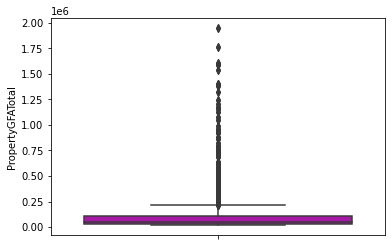

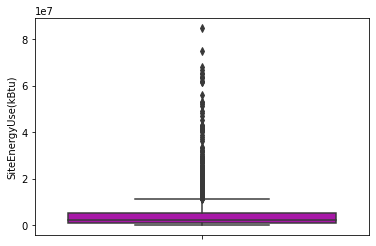

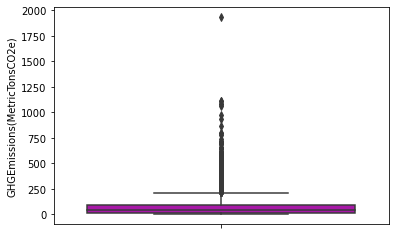

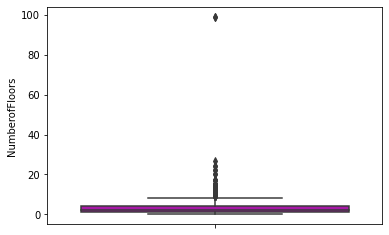

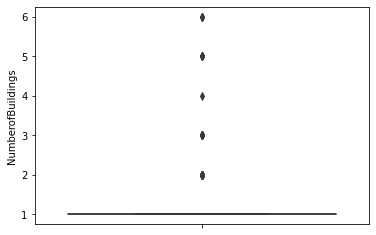

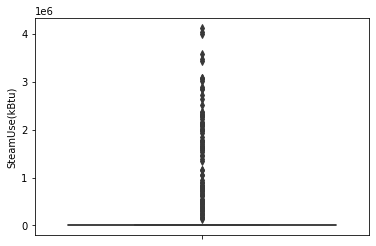

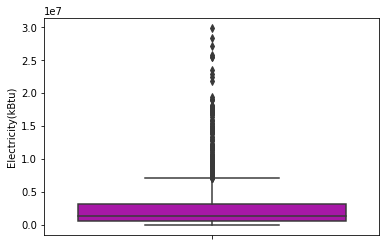

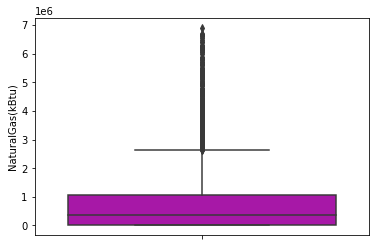

In [220]:
sns.boxplot(y='PropertyGFATotal',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['PropertyGFATotal']<300000]

sns.boxplot(y='SiteEnergyUse(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['SiteEnergyUse(kBtu)']<30000000]

sns.boxplot(y='GHGEmissions(MetricTonsCO2e)',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['GHGEmissions(MetricTonsCO2e)']<400]

sns.boxplot(y='NumberofFloors',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['NumberofFloors']<30]

sns.boxplot(y='NumberofBuildings',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['NumberofBuildings']<20]

sns.boxplot(y='SteamUse(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['SteamUse(kBtu)']<4000000]

sns.boxplot(y='Electricity(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()

df_NRJ=df_NRJ[df_NRJ['Electricity(kBtu)']<20000000]

sns.boxplot(y='NaturalGas(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()

#df_NRJ=df_NRJ[df_NRJ['NaturalGas(kBtu)']<]

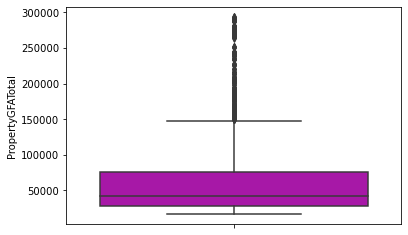

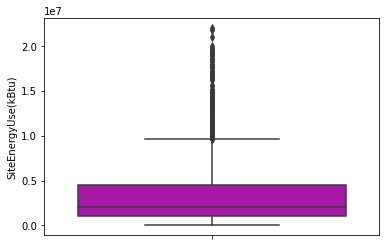

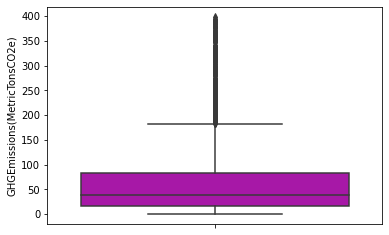

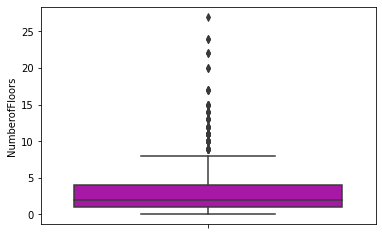

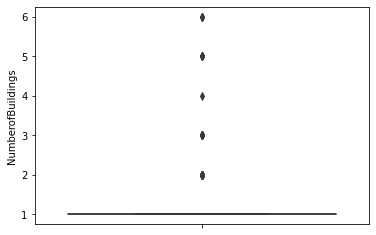

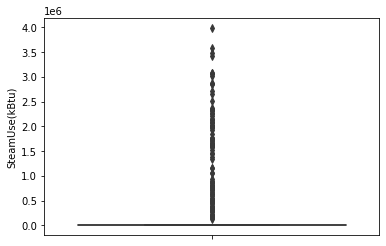

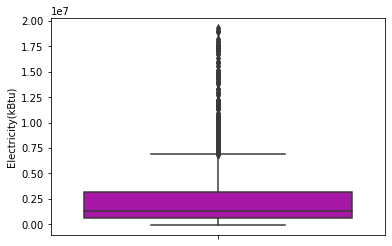

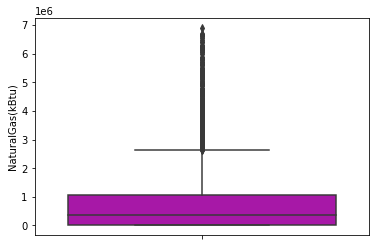

In [221]:
sns.boxplot(y='PropertyGFATotal',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='SiteEnergyUse(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='GHGEmissions(MetricTonsCO2e)',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='NumberofFloors',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='NumberofBuildings',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='SteamUse(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='Electricity(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()
sns.boxplot(y='NaturalGas(kBtu)',palette=["m", "g"],
            data=df_NRJ)
plt.show()


### Then remove all columns that are meter readings
### and keep only Compliant data


In [222]:
df_NRJ=df_NRJ[df_NRJ['ComplianceStatus']=='Compliant']

In [223]:
df_NRJ.shape

(2511, 30)

### Then decide which qualitative variable to use --> look at the distribution


In [224]:
df_NRJ.head(5)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0,NaN,1,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0,NaN,0,0,1
5,10,2015,NonResidential,Hotel,1619 9th ave,98101.0,660000825,7,DOWNTOWN,1926,1.0,11.0,83008,25.0,76.9,149.5,6252842.0,0.0,2679698.0,3573255.0,Compliant,208.46,2.37,0.0,31.0,14.0,NaN,0,0,1
6,11,2015,NonResidential,Other,901 pine st,98101.0,660000955,7,DOWNTOWN,1926,1.0,8.0,102761,NaN,62.5,152.2,6426022.0,2003108.0,4108004.0,315079.0,Compliant,199.99,1.77,0.0,31.0,14.0,NaN,1,0,0
7,12,2015,NonResidential,Hotel,612 2nd ave,98104.0,939000080,7,DOWNTOWN,1904,1.0,15.0,163984,46.0,77.0,174.6,12633744.0,0.0,7355649.0,5278400.0,Compliant,331.61,1.83,0.0,19.0,14.0,NaN,1,0,0


In [225]:
# convert the 'Neighborhood' column to upper case

In [226]:
#df_NRJ['Neighborhood'] = map(lambda x: str(x).upper(), df_NRJ['Neighborhood'])
#df_NRJ['Neighborhood'] = df_NRJ['Neighborhood'].str.upper()
df_NRJ['Neighborhood']=df_NRJ['Neighborhood'].str.upper()

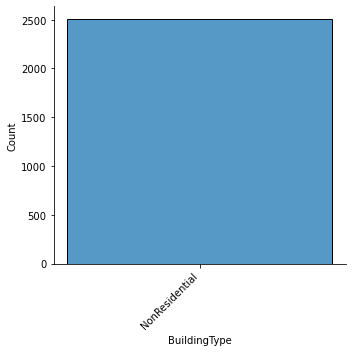

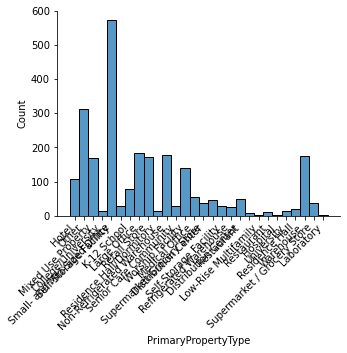

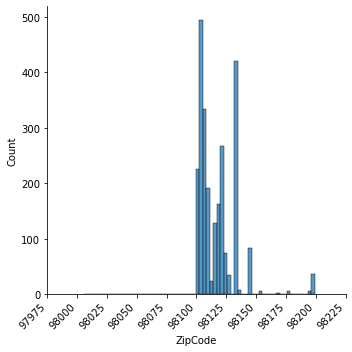

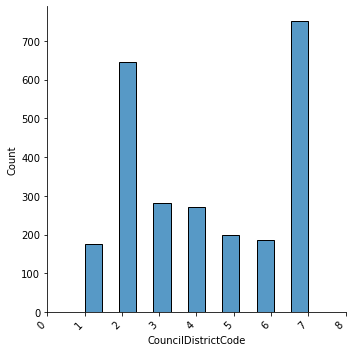

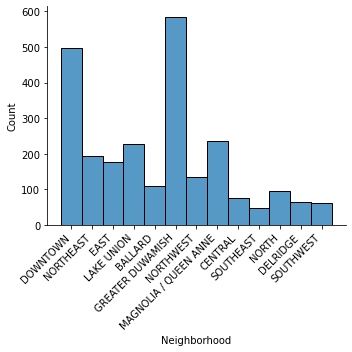

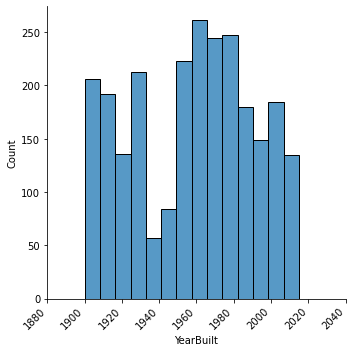

In [227]:
variable_quali=['BuildingType','PrimaryPropertyType',
                    'ZipCode',
                    'CouncilDistrictCode','Neighborhood','YearBuilt']

for vq in variable_quali :

    a=sns.displot(data=df_NRJ[vq])
    a.set_xticklabels(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    

# variables on which we want to apply a LabelEncoder:
# BuildingType, Neighborhood, CouncilDistrictCode 
# YearBuilt encoded by decade (1970-1979: 70, 2010-2019: 110...)
# --> discriminating enough, without too many distinct values


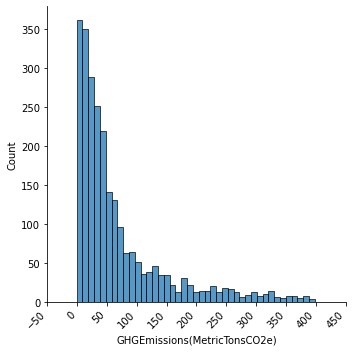

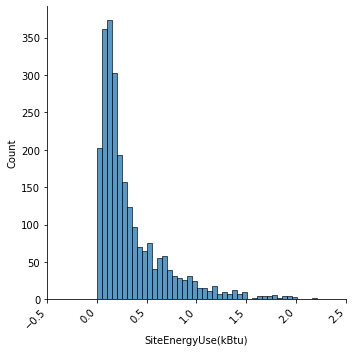

In [228]:
a=sns.displot(data=df_NRJ['GHGEmissions(MetricTonsCO2e)'])
a.set_xticklabels(rotation=45, ha="right")
plt.tight_layout()
plt.show()

a=sns.displot(data=df_NRJ['SiteEnergyUse(kBtu)'])
a.set_xticklabels(rotation=45, ha="right")
plt.tight_layout()
plt.show()

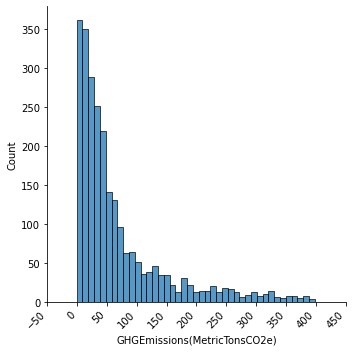

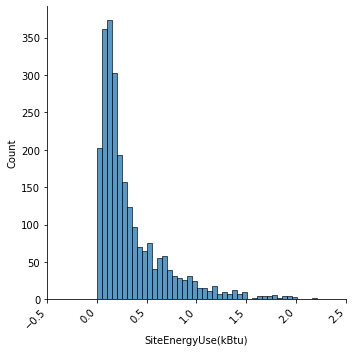

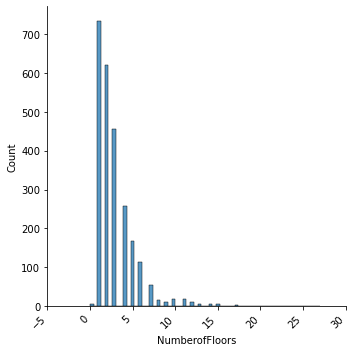

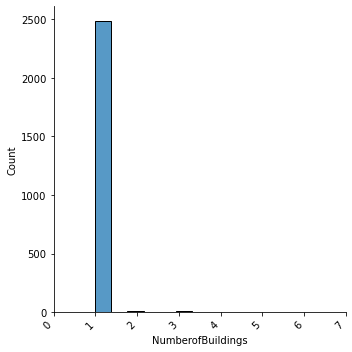

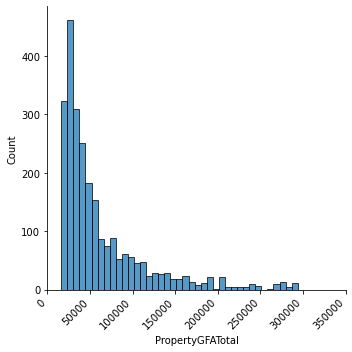

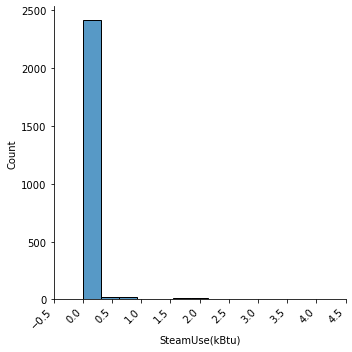

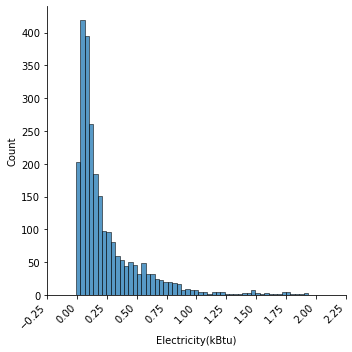

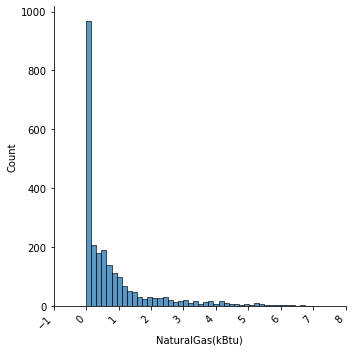

In [229]:
variable_quanti=['GHGEmissions(MetricTonsCO2e)',
'SiteEnergyUse(kBtu)',
'NumberofFloors',
'NumberofBuildings',
'PropertyGFATotal',
'SteamUse(kBtu)',
'Electricity(kBtu)',
'NaturalGas(kBtu)']

for vq in variable_quanti :

    a=sns.displot(data=df_NRJ[vq])
    a.set_xticklabels(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [230]:
df_NRJ[variable_quanti].skew(axis=0)

GHGEmissions(MetricTonsCO2e)     1.958911
SiteEnergyUse(kBtu)              1.987499
NumberofFloors                   3.037293
NumberofBuildings               14.513440
PropertyGFATotal                 2.087334
SteamUse(kBtu)                   6.835719
Electricity(kBtu)                2.459898
NaturalGas(kBtu)                 2.156845
dtype: float64

In [231]:
df_NRJ.shape

(2511, 30)

In [232]:
# test a log transform of the floors, buildings and Property GFA variables

df_NRJ=df_NRJ[df_NRJ['NumberofFloors']>0]

df_NRJ['log_NumberofFloors']=np.log(df_NRJ['NumberofFloors'])
df_NRJ['log_NumberofBuildings']=np.log(df_NRJ['NumberofBuildings'])
df_NRJ['log_PropertyGFATotal']=np.log(df_NRJ['PropertyGFATotal'])

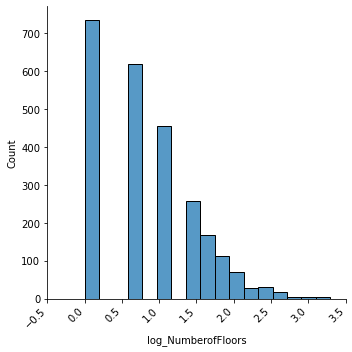

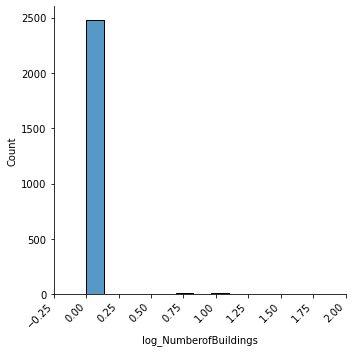

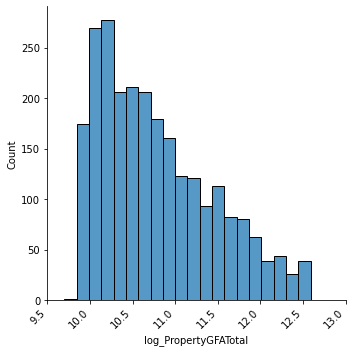

In [233]:
variable_quanti_V2=['log_NumberofFloors',
'log_NumberofBuildings',
'log_PropertyGFATotal']

for vq in variable_quanti_V2 :

    a=sns.displot(data=df_NRJ[vq])
    a.set_xticklabels(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [234]:
df_NRJ[variable_quanti_V2].skew(axis=0)

log_NumberofFloors        0.366597
log_NumberofBuildings    11.492736
log_PropertyGFATotal      0.723965
dtype: float64

In [235]:
# --> we drop numberofbuildings, which is unusable (and not really discriminating)



### LabelEncoder 

In [236]:
from sklearn.preprocessing import OneHotEncoder

In [237]:
from sklearn import preprocessing
lab_enc = preprocessing.LabelEncoder()
#one_hot = preprocessing.OneHotEncoder()

#y_BuildingType=df_NRJ_2015['BuildingType']
#e_BuildingType = lab_enc.fit_transform(y_BuildingType)

#df_NRJ_2015['e_BuildingType']=e_BuildingType


#one_hot_BuildingType = pd.get_dummies(df_NRJ['BuildingType'])

#df_NRJ = df_NRJ.join(one_hot_BuildingType)

In [238]:
# filter on non-residential buildings

#df_NRJ=df_NRJ[df_NRJ['Multifamily HR (10+)']==0]

#df_NRJ=df_NRJ[df_NRJ['Multifamily LR (1-4)']==0]

#df_NRJ=df_NRJ[df_NRJ['Multifamily MR (5-9)']==0]

#to_drop2=['Multifamily HR (10+)','Multifamily LR (1-4)','Multifamily MR (5-9)','NonResidential','Nonresidential COS','Nonresidential WA']

#df_NRJ.drop(to_drop2,axis='columns',inplace=True)

df_NRJ.shape

(2505, 33)

In [239]:
one_hot_Neighborhood = pd.get_dummies(df_NRJ['Neighborhood'])

df_NRJ = df_NRJ.join(one_hot_Neighborhood)

In [240]:
one_hot_CouncilDistrictCode = pd.get_dummies(df_NRJ['CouncilDistrictCode'])

df_NRJ = df_NRJ.join(one_hot_CouncilDistrictCode)

In [241]:
df_NRJ.rename(columns={1:'CouncilDistrictCode_1'},inplace=True)
df_NRJ.rename(columns={2:'CouncilDistrictCode_2'},inplace=True)
df_NRJ.rename(columns={3:'CouncilDistrictCode_3'},inplace=True)
df_NRJ.rename(columns={4:'CouncilDistrictCode_4'},inplace=True)
df_NRJ.rename(columns={5:'CouncilDistrictCode_5'},inplace=True)
df_NRJ.rename(columns={6:'CouncilDistrictCode_6'},inplace=True)
df_NRJ.rename(columns={7:'CouncilDistrictCode_7'},inplace=True)

In [242]:
df_NRJ['YearBuilt'].describe()

count    2505.000000
mean     1957.815968
std        32.554833
min      1900.000000
25%      1927.000000
50%      1962.000000
75%      1984.000000
max      2015.000000
Name: YearBuilt, dtype: float64

In [243]:
df_NRJ=df_NRJ.reset_index(drop=True)

In [244]:
# YearBuilt


df_NRJ['Decade']=0

#dec=0

for i in range(df_NRJ.shape[0]):
    if df_NRJ['YearBuilt'][i]<1910:
        df_NRJ.at[i, 'Decade']=0
        
    elif df_NRJ['YearBuilt'][i]>=1910 and df_NRJ['YearBuilt'][i]<1920:
        df_NRJ.at[i, 'Decade']=10
        
    elif df_NRJ['YearBuilt'][i]>=1920 and df_NRJ['YearBuilt'][i]<1930:
        df_NRJ.at[i, 'Decade']=20
        
    elif df_NRJ['YearBuilt'][i]>=1930 and df_NRJ['YearBuilt'][i]<1940:
        df_NRJ.at[i, 'Decade']=30
        
    elif df_NRJ['YearBuilt'][i]>=1940 and df_NRJ['YearBuilt'][i]<1950:
        df_NRJ.at[i, 'Decade']=40  
        
    elif df_NRJ['YearBuilt'][i]>=1950 and df_NRJ['YearBuilt'][i]<1960:
        df_NRJ.at[i, 'Decade']=50  
        
    elif df_NRJ['YearBuilt'][i]>=1960 and df_NRJ['YearBuilt'][i]<1970:
        df_NRJ.at[i, 'Decade']=60
        
    elif df_NRJ['YearBuilt'][i]>=1970 and df_NRJ['YearBuilt'][i]<1980:
        df_NRJ.at[i, 'Decade']=70
        
    elif df_NRJ['YearBuilt'][i]>=1980 and df_NRJ['YearBuilt'][i]<1990:
        df_NRJ.at[i, 'Decade']=80
        
    elif df_NRJ['YearBuilt'][i]>=1990 and df_NRJ['YearBuilt'][i]<2000:
        df_NRJ.at[i, 'Decade']=90
        
    elif df_NRJ['YearBuilt'][i]>=2000 and df_NRJ['YearBuilt'][i]<2010:
        df_NRJ.at[i, 'Decade']=100
        
    elif df_NRJ['YearBuilt'][i]>=2010 and df_NRJ['YearBuilt'][i]<2020:
        df_NRJ.at[i, 'Decade']=110
        
        
        
#df_NRJ['Decade']=decade
        

In [245]:
df_NRJ['YearBuilt'].isnull().sum()

0

In [246]:
df_NRJ.head(10)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,log_NumberofFloors,log_NumberofBuildings,log_PropertyGFATotal,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0,NaN,1,0,0,2.484907,0.0,11.390012,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.547964,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,90
2,10,2015,NonResidential,Hotel,1619 9th ave,98101.0,660000825,7,DOWNTOWN,1926,1.0,11.0,83008,25.0,76.9,149.5,6252842.0,0.0,2679698.0,3573255.0,Compliant,208.46,2.37,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.326692,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20
3,11,2015,NonResidential,Other,901 pine st,98101.0,660000955,7,DOWNTOWN,1926,1.0,8.0,102761,NaN,62.5,152.2,6426022.0,2003108.0,4108004.0,315079.0,Compliant,199.99,1.77,0.0,31.0,14.0,NaN,1,0,0,2.079442,0.0,11.540161,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20
4,12,2015,NonResidential,Hotel,612 2nd ave,98104.0,939000080,7,DOWNTOWN,1904,1.0,15.0,163984,46.0,77.0,174.6,12633744.0,0.0,7355649.0,5278400.0,Compliant,331.61,1.83,0.0,19.0,14.0,NaN,1,0,0,2.708050,0.0,12.007524,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
5,17,2015,NonResidential,Hotel,400 spring st,98104.0,942000210,7,DOWNTOWN,1928,1.0,9.0,65009,39.0,104.7,166.5,6807227.0,1987163.0,1615057.0,3205074.0,Compliant,334.87,5.04,0.0,19.0,14.0,NaN,0,0,1,2.197225,0.0,11.082281,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20
6,24,2015,NonResidential,Mixed Use Property,810 4th ave,98104.0,942000510,7,DOWNTOWN,1907,1.0,5.0,57452,NaN,130.2,278.7,7481768.0,1755365.0,3773975.0,1952583.0,Compliant,265.50,4.34,0.0,19.0,14.0,NaN,1,0,0,1.609438,0.0,10.958705,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
7,29,2015,NonResidential,Hotel,4242 roosevelt way ne,98105.0,1142000755,4,NORTHEAST,2001,1.0,6.0,88592,85.0,66.9,151.5,3880806.0,0.0,2254751.0,1626149.0,Compliant,102.08,1.04,0.0,38.0,60.0,NaN,1,0,0,1.791759,0.0,11.391797,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,100
8,30,2015,NonResidential,College/University,1000 lenora st,98121.0,660001420,7,DOWNTOWN,1928,1.0,7.0,126593,NaN,78.3,158.9,9791557.0,0.0,4582663.0,5209084.0,Compliant,308.60,2.28,0.0,7.0,56.0,NaN,0,0,1,1.945910,0.0,11.748732,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20
9,31,2015,NonResidential,Other,1017 olive way,98101.0,660001725,7,DOWNTOWN,1930,1.0,2.0,67224,NaN,20.7,64.9,1388717.0,0.0,1388775.0,0.0,Compliant,9.68,0.06,0.0,31.0,14.0,NaN,1,0,0,0.693147,0.0,11.115786,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,30


In [247]:
one_hot_Decade = pd.get_dummies(df_NRJ['Decade'])

df_NRJ = df_NRJ.join(one_hot_Decade)

In [248]:
df_NRJ.head(10)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,log_NumberofFloors,log_NumberofBuildings,log_PropertyGFATotal,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,0,10,20,30,40,50,60,70,80,90,100,110
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.9,173.5,6981428.0,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0,NaN,1,0,0,2.484907,0.0,11.390012,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.4,191.3,8354235.0,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.547964,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,90,0,0,0,0,0,0,0,0,0,1,0,0
2,10,2015,NonResidential,Hotel,1619 9th ave,98101.0,660000825,7,DOWNTOWN,1926,1.0,11.0,83008,25.0,76.9,149.5,6252842.0,0.0,2679698.0,3573255.0,Compliant,208.46,2.37,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.326692,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0
3,11,2015,NonResidential,Other,901 pine st,98101.0,660000955,7,DOWNTOWN,1926,1.0,8.0,102761,NaN,62.5,152.2,6426022.0,2003108.0,4108004.0,315079.0,Compliant,199.99,1.77,0.0,31.0,14.0,NaN,1,0,0,2.079442,0.0,11.540161,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0
4,12,2015,NonResidential,Hotel,612 2nd ave,98104.0,939000080,7,DOWNTOWN,1904,1.0,15.0,163984,46.0,77.0,174.6,12633744.0,0.0,7355649.0,5278400.0,Compliant,331.61,1.83,0.0,19.0,14.0,NaN,1,0,0,2.708050,0.0,12.007524,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
5,17,2015,NonResidential,Hotel,400 spring st,98104.0,942000210,7,DOWNTOWN,1928,1.0,9.0,65009,39.0,104.7,166.5,6807227.0,1987163.0,1615057.0,3205074.0,Compliant,334.87,5.04,0.0,19.0,14.0,NaN,0,0,1,2.197225,0.0,11.082281,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0
6,24,2015,NonResidential,Mixed Use Property,810 4th ave,98104.0,942000510,7,DOWNTOWN,1907,1.0,5.0,57452,NaN,130.2,278.7,7481768.0,1755365.0,3773975.0,1952583.0,Compliant,265.50,4.34,0.0,19.0,14.0,NaN,1,0,0,1.609438,0.0,10.958705,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
7,29,2015,NonResidential,Hotel,4242 roosevelt way ne,98105.0,1142000755,4,NORTHEAST,2001,1.0,6.0,88592,85.0,66.9,151.5,3880806.0,0.0,2254751.0,1626149.0,Compliant,102.08,1.04,0.0,38.0,60.0,NaN,1,0,0,1.791759,0.0,11.391797,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,100,0,0,0,0,0,0,0,0,0,0,1,0
8,30,2015,NonResidential,College/University,1000 lenora st,98121.0,660001420,7,DOWNTOWN,1928,1.0,7.0,126593,NaN,78.3,158.9,9791557.0,0.0,4582663.0,5209084.0,Compliant,308.60,2.28,0.0,7.0,56.0,NaN,0,0,1,1.945910,0.0,11.748732,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0
9,31,2015,NonResidential,Other,1017 olive way,98101.0,660001725,7,DOWNTOWN,1930,1.0,2.0,67224,NaN,20.7,64.9,1388717.0,0.0,1388775.0,0.0,Compliant,9.68,0.06,0.0,31.0,14.0,NaN,1,0,0,0.693147,0.0,11.115786,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,30,0,0,0,1,0,0,0,0,0,0,0,0


In [249]:
df_NRJ.rename(columns={0:'1900_1909'},inplace=True)
df_NRJ.rename(columns={10:'1910_1919'},inplace=True)
df_NRJ.rename(columns={20:'1920_1929'},inplace=True)
df_NRJ.rename(columns={30:'1930_1939'},inplace=True)
df_NRJ.rename(columns={40:'1940_1949'},inplace=True)
df_NRJ.rename(columns={50:'1950_1959'},inplace=True)
df_NRJ.rename(columns={60:'1960_1969'},inplace=True)
df_NRJ.rename(columns={70:'1970_1979'},inplace=True)
df_NRJ.rename(columns={80:'1980_1989'},inplace=True)
df_NRJ.rename(columns={90:'1990_1999'},inplace=True)
df_NRJ.rename(columns={100:'2000_2009'},inplace=True)
df_NRJ.rename(columns={110:'2010_2019'},inplace=True)

In [250]:
#df_NRJ.head(100)

In [251]:
# encode the primarypropertytypes

In [252]:
df_NRJ['PrimaryPropertyType'].value_counts()

Small- and Mid-Sized Office    572
Other                          312
Large Office                   183
Non-Refrigerated Warehouse     179
Warehouse                      175
Retail Store                   173
Mixed Use Property             169
Worship Facility               139
Hotel                          107
K-12 School                     77
Medical Office                  55
Distribution Center             50
Distribution Center\n           47
Supermarket / Grocery Store     37
Supermarket/Grocery Store       36
Self-Storage Facility           29
Senior Care Community           28
Self-Storage Facility\n         27
Refrigerated Warehouse          25
Residence Hall                  17
Residence Hall/Dormitory        15
College/University              14
University                      13
Restaurant                      11
Restaurant\n                     8
Laboratory                       3
Hospital                         2
Low-Rise Multifamily             2
Name: PrimaryPropert

In [253]:
df_NRJ_test=df_NRJ

In [254]:
##### cells not listed in map are ignored and replaced by NaN. To be improved. Restart here.



df_NRJ['PrimaryPropertyType'] = df_NRJ['PrimaryPropertyType'].replace({'K-12 School':'K_12 School',
                                                        'Distribution Center\n':'Distribution Center',
                                                         'Supermarket / Grocery Store':'Supermarket_Grocery Store',
                                                         'Supermarket/Grocery Store':'Supermarket_Grocery Store',          
                                                         'Self-Storage Facility':'Self_Storage Facility',          
                                                         'Self-Storage Facility\n':'Self_Storage Facility',  
                                                         'Restaurant\n':'Restaurant',           
                                                         'Residence Hall':'Residence Hall/Dormitory',           
                                                         'University':'College/University',           
                                                        'Self-Storage Facility\n':'Self_Storage Facility',
                                                        'Non-Refrigerated Warehouse':'Warehouse',
                                                        'Refrigerated Warehouse':'Warehouse'})
                          #   ,na_action='ignore')

In [255]:
df_NRJ['PrimaryPropertyType'].value_counts()

Small- and Mid-Sized Office    572
Warehouse                      379
Other                          312
Large Office                   183
Retail Store                   173
Mixed Use Property             169
Worship Facility               139
Hotel                          107
Distribution Center             97
K_12 School                     77
Supermarket_Grocery Store       73
Self_Storage Facility           56
Medical Office                  55
Residence Hall/Dormitory        32
Senior Care Community           28
College/University              27
Restaurant                      19
Laboratory                       3
Hospital                         2
Low-Rise Multifamily             2
Name: PrimaryPropertyType, dtype: int64

In [256]:
one_hot_PrimaryPropertyType = pd.get_dummies(df_NRJ['PrimaryPropertyType'])

df_NRJ = df_NRJ.join(one_hot_PrimaryPropertyType)

In [257]:
df_NRJ

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),GHGEmissionsIntensity(kgCO2e/ft2),OtherFuelUse(kBtu),SPD Beats,Seattle Police Department Micro Community Policing Plan Areas,ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,log_NumberofFloors,log_NumberofBuildings,log_PropertyGFATotal,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Other,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,78.900000,173.500000,6981428.00,2023032.0,3686160.0,1272388.0,Compliant,249.43,2.64,0.0,31.0,14.0,NaN,1,0,0,2.484907,0.0,11.390012,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,94.400000,191.300000,8354235.00,0.0,3905411.0,4448985.0,Compliant,263.51,2.38,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.547964,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,90,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,10,2015,NonResidential,Hotel,1619 9th ave,98101.0,660000825,7,DOWNTOWN,1926,1.0,11.0,83008,25.0,76.900000,149.500000,6252842.00,0.0,2679698.0,3573255.0,Compliant,208.46,2.37,0.0,31.0,14.0,NaN,0,0,1,2.397895,0.0,11.326692,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,11,2015,NonResidential,Other,901 pine st,98101.0,660000955,7,DOWNTOWN,1926,1.0,8.0,102761,NaN,62.500000,152.200000,6426022.00,2003108.0,4108004.0,315079.0,Compliant,199.99,1.77,0.0,31.0,14.0,NaN,1,0,0,2.079442,0.0,11.540161,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,12,2015,NonResidential,Hotel,612 2nd ave,98104.0,939000080,7,DOWNTOWN,1904,1.0,15.0,163984,46.0,77.000000,174.600000,12633744.00,0.0,7355649.0,5278400.0,Compliant,331.61,1.83,0.0,19.0,14.0,NaN,1,0,0,2.708050,0.0,12.007524,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2500,50062,2016,NonResidential,Hotel,3926 aurora ave n,98103.0,1931300480,4,LAKE UNION,2014,1.0,4.0,126823,72.0,68.500000,169.500000,6042399.50,0.0,4115620.0,1926779.0,Compliant,131.02,1.03,NaN,NaN,NaN,0.0,1,0,0,1.386294,0.0,11.750548,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,110,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2501,50068,2016,NonResidential,Warehouse,6518 ellis,98108.0,2824049007,2,GREATER DUWAMISH,1955,1.0,1.0,52085,37.0,69.199997,102.099998,3605855.50,0.0,732803.0,2873052.0,Compliant,157.70,3.03,NaN,NaN,NaN,0.0,0,0,1,0.000000,0.0,10.860632,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,50,0,0,0,0,0,1,0,0,0,0,

In [258]:
to_drop=['SiteEUI(kBtu/sf)','SourceEUI(kBtu/sf)','SteamUse(kBtu)','Electricity(kBtu)','NaturalGas(kBtu)','GHGEmissionsIntensity(kgCO2e/ft2)','OtherFuelUse(kBtu)',
        'SPD Beats','Seattle Police Department Micro Community Policing Plan Areas']

df_NRJ.drop(to_drop,axis='columns',inplace=True)

In [259]:

#df_NRJ.to_csv('P4_Modelisation.csv')


# -----------------------------------------------------------------

# Modelling: 

In [262]:

df_NRJ = pd.read_csv('P4_Modelisation.csv')
df_NRJ.drop(["Unnamed: 0"],axis='columns',inplace=True)

In [263]:
df_NRJ

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEnergyUse(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,log_NumberofFloors,log_NumberofBuildings,log_PropertyGFATotal,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Other,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,6981428.00,Compliant,249.43,NaN,1,0,0,2.484907,0.0,11.390012,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,8354235.00,Compliant,263.51,NaN,0,0,1,2.397895,0.0,11.547964,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,90,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,10,2015,NonResidential,Hotel,1619 9th ave,98101.0,660000825,7,DOWNTOWN,1926,1.0,11.0,83008,25.0,6252842.00,Compliant,208.46,NaN,0,0,1,2.397895,0.0,11.326692,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,11,2015,NonResidential,Other,901 pine st,98101.0,660000955,7,DOWNTOWN,1926,1.0,8.0,102761,NaN,6426022.00,Compliant,199.99,NaN,1,0,0,2.079442,0.0,11.540161,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,12,2015,NonResidential,Hotel,612 2nd ave,98104.0,939000080,7,DOWNTOWN,1904,1.0,15.0,163984,46.0,12633744.00,Compliant,331.61,NaN,1,0,0,2.708050,0.0,12.007524,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2500,50062,2016,NonResidential,Hotel,3926 aurora ave n,98103.0,1931300480,4,LAKE UNION,2014,1.0,4.0,126823,72.0,6042399.50,Compliant,131.02,0.0,1,0,0,1.386294,0.0,11.750548,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,110,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2501,50068,2016,NonResidential,Warehouse,6518 ellis,98108.0,2824049007,2,GREATER DUWAMISH,1955,1.0,1.0,52085,37.0,3605855.50,Compliant,157.70,0.0,0,0,1,0.000000,0.0,10.860632,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,50,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2502,50069,2016,NonResidential,Small- and Mid-Sized Office,7277 perimeter rd.,98108.0,2824049007,2,GREATER DUWAMISH,1929,1.0,2.0,24990,9.0,4420650.50,Compliant,134.80,0.0,0,0,1,0.693147,0.0,10.126231,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2503,50070,2016,NonResidential,Other,7135 sportsfield drive ne,98155.0,0225049062,4,NORTHEAST,2013,1.0,1.0,72000,NaN,2925780.00,Compliant,67.65,0.0,1,0,0,0.000000,0.0,11.184421,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,110,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [60]:
df_NRJ_initial=df_NRJ

In [61]:

xtrain_columns=['NumberofBuildings','NumberofFloors','PropertyGFATotal']+list(df_NRJ.columns[18:])


# warning: test in progress with 'Multifamily HR (10+)','Multifamily LR (1-4)','Multifamily MR (5-9)', and all the others
# buildingTypes other than nonResidential removed

# add the primary property types, knowing that Building Types is filtered on non-residential

# drop numberofbuildings (not standardised, and hard to standardise)

xtrain_columns_V2=['NumberofFloors',
 'PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Other',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office',
 'Supermarket_Grocery Store',
 'Warehouse',
 'Worship Facility']


# log-transform numberoffloors and propertyGFA
xtrain_columns_V3=xtrain_columns_V2=['log_NumberofFloors',
 'log_PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Other',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office',
 'Supermarket_Grocery Store',
 'Warehouse',
 'Worship Facility']



df_NRJ_train=df_NRJ[xtrain_columns_V2]

## Modelling GHG emissions:

In [63]:
df_NRJ.shape

(2505, 77)

In [310]:
# What to do with empty cells? --> these rows are not used for modelling.
# as in the previous projects, to estimate the 10 missing values,
# we train on the complete rows, then apply the model to the empty ones.

In [529]:
df_NRJ.isna().sum()

OSEBuildingID                        0
DataYear                             0
BuildingType                         0
PrimaryPropertyType                  0
Address                              0
ZipCode                              0
TaxParcelIdentificationNumber        0
CouncilDistrictCode                  0
Neighborhood                         0
YearBuilt                            0
NumberofBuildings                    0
NumberofFloors                       0
PropertyGFATotal                     0
ENERGYSTARScore                    794
SiteEnergyUse(kBtu)                  0
ComplianceStatus                     0
GHGEmissions(MetricTonsCO2e)         0
ThirdLargestPropertyUseTypeGFA    1274
Electricity                          0
Steam                                0
NaturalGas                           0
Campus                               0
SPS-District K-12                    0
BALLARD                              0
CENTRAL                              0
DELRIDGE                 

In [530]:
df_NRJ.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEnergyUse(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,Campus,SPS-District K-12,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Non-Refrigerated Warehouse,Other,Refrigerated Warehouse,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,1.0,12.0,88434,65.0,6981428.0,Compliant,249.43,NaN,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,20,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,1.0,11.0,103566,51.0,8354235.0,Compliant,263.51,NaN,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,90,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [65]:
df_NRJ.drop('Decade',axis='columns',inplace=True)
#df_NRJ.drop('Not Compliant',axis='columns',inplace=True)
#df_NRJ.drop('Compliant',axis='columns',inplace=True)

## Dummy Regressor --> ok

In [64]:
df_NRJ=df_NRJ[df_NRJ['GHGEmissions(MetricTonsCO2e)']>0]


df_NRJ['log_GHGEmissions(MetricTonsCO2e)']=np.log(df_NRJ['GHGEmissions(MetricTonsCO2e)'])


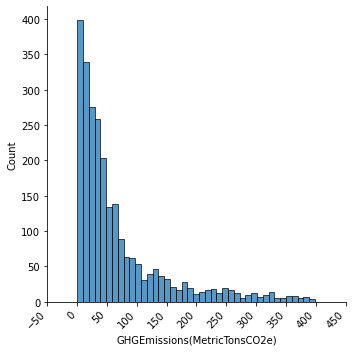

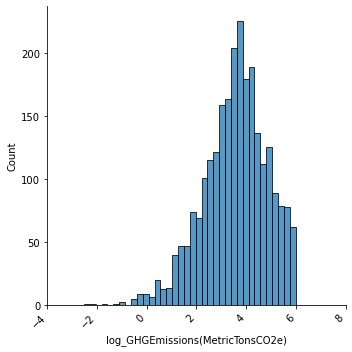

In [533]:
a=sns.displot(data=df_NRJ['GHGEmissions(MetricTonsCO2e)'])
a.set_xticklabels(rotation=45, ha="right")
plt.tight_layout()
plt.show()

a=sns.displot(data=df_NRJ['log_GHGEmissions(MetricTonsCO2e)'])
a.set_xticklabels(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [534]:
df_NRJ.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'Address', 'ZipCode', 'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'ENERGYSTARScore', 'SiteEnergyUse(kBtu)', 'ComplianceStatus', 'GHGEmissions(MetricTonsCO2e)', 'ThirdLargestPropertyUseTypeGFA', 'Electricity', 'Steam', 'NaturalGas', 'Campus', 'SPS-District K-12', 'BALLARD', 'CENTRAL', 'DELRIDGE', 'DOWNTOWN', 'EAST', 'GREATER DUWAMISH', 'LAKE UNION', 'MAGNOLIA / QUEEN ANNE', 'NORTH', 'NORTHEAST', 'NORTHWEST', 'SOUTHEAST', 'SOUTHWEST', 'CouncilDistrictCode_1', 'CouncilDistrictCode_2', 'CouncilDistrictCode_3', 'CouncilDistrictCode_4', 'CouncilDistrictCode_5', 'CouncilDistrictCode_6', 'CouncilDistrictCode_7', '1900_1909', '1910_1919', '1920_1929', '1930_1939', '1940_1949', '1950_1959', '1960_1969', '1970_1979', '1980_1989', '1990_1999', '2000_2009', '2010_2019', 'College/University', 'Distribution Center', 'Hospital',


In [65]:
# Model without NaN, with negative CO2 values. No log, no scaling.


df_NRJ_NoNan=df_NRJ_initial[~df_NRJ_initial['GHGEmissions(MetricTonsCO2e)'].isna()]

X_DR = df_NRJ_NoNan[xtrain_columns_V2]
y_DR = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']


In [66]:


X_train_DR, X_test_DR, y_train_DR, y_test_DR = train_test_split(X_DR, y_DR, random_state=0)


dummy_regr = DummyRegressor(strategy="mean")


start_time = timeit.default_timer()

dummy_regr.fit(X_train_DR, y_train_DR)

elapsed = timeit.default_timer() - start_time

print(elapsed)

y_predict_DR=dummy_regr.predict(X_test_DR)


0.0004007999999657841


In [130]:

# R2 :
print("r2_score (dummy mean): {:.2f}".format(r2_score(y_test_DR, y_predict_DR)))

r2_score (dummy mean): -0.00


In [131]:
# RMSE : 

print("Mean squared error (linear model): {:.2f}".format(mean_squared_error(y_test_DR, y_predict_DR)))


Mean squared error (linear model): 6072.54


In [132]:
# Model without NaN or negative CO2 values. With log and scaling.

In [68]:
df_NRJ=df_NRJ[df_NRJ['GHGEmissions(MetricTonsCO2e)']>0]


df_NRJ_NoNan=df_NRJ[~df_NRJ['log_GHGEmissions(MetricTonsCO2e)'].isna()]


X_DR = df_NRJ_NoNan[xtrain_columns_V2]


from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_DR)
X_DR_std = std_scale.transform(X_DR)

abc=list(df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)'])

data_std=pd.DataFrame(X_DR_std,columns=xtrain_columns_V2)

data_std=data_std.assign(logGHGEmissions=df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)'])



In [69]:
data_std['logGHGEmissions'].isna().sum()

4

In [71]:
data_std=data_std[~data_std['logGHGEmissions'].isna()]


X_std_DR = data_std[xtrain_columns_V2]
y_log_DR = data_std['logGHGEmissions']

X_train_std_DR, X_test_std_DR, y_train_log_DR, y_test_log_DR = train_test_split(X_std_DR, y_log_DR, random_state=0)


dummy_regr = DummyRegressor(strategy="mean")

start_time = timeit.default_timer()

dummy_regr.fit(X_train_std_DR, y_train_log_DR)

elapsed = timeit.default_timer() - start_time

print(elapsed)

y_log_predict_DR=dummy_regr.predict(X_test_std_DR)

0.0005333999999947991


In [136]:

# R2 :
print("r2_score (dummy mean): {:.2f}".format(r2_score(y_test_log_DR, y_log_predict_DR)))

# RMSE : 
print("Mean squared error (linear model): {:.2f}".format(mean_squared_error(y_test_log_DR, y_log_predict_DR)))



r2_score (dummy mean): -0.01
Mean squared error (linear model): 1.81


In [543]:
# R2 score close to 0. RMSE has decreased though.

## Linear Regression --> ok

#Example from the previous project:





df7_noNa=df7[~df7["nutriscore_score"].isna()]


mod = sm.regression.linear_model.OLS.from_formula(formula='nutriscore_score ~ energy_100g + fat_100g+saturated_fat_100g+carbohydrates_100g+sugars_100g+sodium_100g+fiber_100g',
                                     data=df7_noNa)

res=mod.fit()


#xdat = rets['EUROSTOXX']
#xdat = sm.add_constant(xdat)
#ydat = rets['VSTOXX']
#model = sm.OLS(y=ydat,x=xdat).fit()


print(res.summary())

In [544]:

import statsmodels.api as sm
import statsmodels.formula.api as smf

In [137]:
# build a model on the whole dataframe without log transform:


mod = sm.regression.linear_model.OLS.from_formula(
    formula='Q("GHGEmissions(MetricTonsCO2e)") ~ NumberofBuildings+NumberofFloors+PropertyGFATotal+Electricity+Steam+NaturalGas+Campus+Q("Multifamily HR (10+)")+Q("Multifamily LR (1-4)")+Q("Multifamily MR (5-9)")+NonResidential+Q("Nonresidential COS")+Q("Nonresidential WA")+Q("SPS-District K-12")+BALLARD+Ballard+CENTRAL+Central+DELRIDGE+Q("DELRIDGE NEIGHBORHOODS")+DOWNTOWN+Delridge+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+North+Northwest+SOUTHEAST+SOUTHWEST+CouncilDistrictCode_1+CouncilDistrictCode_2+CouncilDistrictCode_3+CouncilDistrictCode_4+CouncilDistrictCode_5+CouncilDistrictCode_6+CouncilDistrictCode_7+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")',
                                     data=df_NRJ_initial)

res=mod.fit()

print(res.summary())


                                    OLS Regression Results                                   
Dep. Variable:     Q("GHGEmissions(MetricTonsCO2e)")   R-squared:                       0.337
Model:                                           OLS   Adj. R-squared:                  0.332
Method:                                Least Squares   F-statistic:                     68.55
Date:                               Thu, 02 Sep 2021   Prob (F-statistic):               0.00
Time:                                       10:44:56   Log-Likelihood:                -48352.
No. Observations:                               6537   AIC:                         9.680e+04
Df Residuals:                                   6488   BIC:                         9.713e+04
Df Model:                                         48                                         
Covariance Type:                           nonrobust                                         
                                  coef    std err          t

In [138]:


# build a model after removing negative CO2 emissions and log-transforming this variable



df_NRJ=df_NRJ[df_NRJ['GHGEmissions(MetricTonsCO2e)']>0]


df_NRJ_NoNan=df_NRJ[~df_NRJ['log_GHGEmissions(MetricTonsCO2e)'].isna()]

mod = sm.regression.linear_model.OLS.from_formula(
    formula='Q("log_GHGEmissions(MetricTonsCO2e)") ~ NumberofBuildings+NumberofFloors+PropertyGFATotal+Electricity+Steam+NaturalGas+Campus+Q("Multifamily HR (10+)")+Q("Multifamily LR (1-4)")+Q("Multifamily MR (5-9)")+NonResidential+Q("Nonresidential COS")+Q("Nonresidential WA")+Q("SPS-District K-12")+BALLARD+Ballard+CENTRAL+Central+DELRIDGE+Q("DELRIDGE NEIGHBORHOODS")+DOWNTOWN+Delridge+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+North+Northwest+SOUTHEAST+SOUTHWEST+CouncilDistrictCode_1+CouncilDistrictCode_2+CouncilDistrictCode_3+CouncilDistrictCode_4+CouncilDistrictCode_5+CouncilDistrictCode_6+CouncilDistrictCode_7+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")',
                                     data=df_NRJ_NoNan)

res=mod.fit()

print(res.summary())




                                      OLS Regression Results                                     
Dep. Variable:     Q("log_GHGEmissions(MetricTonsCO2e)")   R-squared:                       0.533
Model:                                               OLS   Adj. R-squared:                  0.529
Method:                                    Least Squares   F-statistic:                     157.3
Date:                                   Thu, 02 Sep 2021   Prob (F-statistic):               0.00
Time:                                           10:44:56   Log-Likelihood:                -9430.4
No. Observations:                                   6532   AIC:                         1.896e+04
Df Residuals:                                       6484   BIC:                         1.928e+04
Df Model:                                             47                                         
Covariance Type:                               nonrobust                                         
                    

In [139]:
# build a standardised model + log transform.

In [545]:
X_LR = df_NRJ_NoNan[xtrain_columns_V2]

from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_LR)
X_LR_std = std_scale.transform(X_LR)

abc=list(df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)'])

data_std=pd.DataFrame(X_LR_std,columns=xtrain_columns_V2)

data_std=data_std.assign(logGHGEmissions=df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)'])

In [546]:
data_std

,NumberofBuildings,NumberofFloors,PropertyGFATotal,Electricity,Steam,NaturalGas,SPS-District K-12,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Non-Refrigerated Warehouse,Other,Refrigerated Warehouse,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility,logGHGEmissions
0,-0.027591,3.662754,0.494437,0.564437,-0.098374,-0.549665,0.0,-0.213334,-0.176922,-0.164534,2.012060,-0.275796,-0.552129,-0.315741,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,-0.321823,-0.293827,2.944139,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,-0.295428,-0.318791,-0.147050,-0.104404,-0.200746,-0.028273,4.733061,-0.178119,-0.034634,-0.279966,-0.028273,-0.148461,-0.26903,-0.277469,-0.377274,-0.100423,-0.119062,-0.087441,-0.271581,-0.151248,-0.106342,-0.544120,-0.172062,-0.274116,-0.242433,5.519178
1,-0.027591,3.257203,0.781940,-1.771678,-0.098374,1.819289,0.0,-0.213334,-0.176922,-0.164534,2.012060,-0.275796,-0.552129,-0.315741,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,-0.321823,-0.293827,-0.339658,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,3.384924,-0.318791,-0.147050,-0.104404,-0.200746,-0.028273,4.733061,-0.178119,-0.034634,-0.279966,-0.028273,-0.148461,-0.26903,-0.277469,-0.377274,-0.100423,-0.119062,-0.087441,-0.271581,-0.151248,-0.106342,-0.544120,-0.172062,-0.274116,-0.242433,5.574091
2,-0.027591,3.257203,0.391345,-1.771678,-0.098374,1.819289,0.0,-0.213334,-0.176922,-0.164534,2.012060,-0.275796,-0.552129,-0.315741,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,-0.321823,-0.293827,2.944139,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,-0.295428,-0.318791,-0.147050,-0.104404,-0.200746,-0.028273,4.733061,-0.178119,-0.034634,-0.279966,-0.028273,-0.148461,-0.26903,-0.277469,-0.377274,-0.100423,-0.119062,-0.087441,-0.271581,-0.151248,-0.106342,-0.544120,-0.172062,-0.274116,-0.242433,5.339747
3,-0.027591,2.040550,0.766645,0.564437,-0.098374,-0.549665,0.0,-0.213334,-0.176922,-0.164534,2.012060,-0.275796,-0.552129,-0.315741,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,-0.321823,-0.293827,2.944139,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,-0.295428,-0.318791,-0.147050,-0.104404,-0.200746,-0.028273,-0.211280,-0.178119,-0.034634,-0.279966,-0.028273,-0.148461,-0.26903,-0.277469,2.650593,-0.100423,-0.119062,-0.087441,-0.271581,-0.151248,-0.106342,-0.544120,-0.172062,-0.274116,-0.242433,5.298267
4,-0.027591,4.879408,1.929861,0.564437,-0.098374,-0.549665,0.0,-0.213334,-0.176922,-0.164534,2.012060,-0.275796,-0.552129,-0.315741,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,3.107301,-0.293827,-0.339658,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,-0.295428,-0.318791,-0.147050,-0.104404,-0.200746,-0.028273,4.733061,-0.178119,-0.034634,-0.279966,-0.028273,-0.148461,-0.26903,-0.277469,-0.377274,-0.100423,-0.119062,-0.087441,-0.271581,-0.151248,-0.106342,-0.544120,-0.172062,-0.274116,-0.242433,5.803960
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,-0.027591,0.418346,1.223815,0.564437,-0.098374,-0.549665,0.0,-0.213334,-0.176922,-0.164534,-0.497003,-0.275796,-0.552129,3.167150,-0.322578,-0.198584,-0.288987,-0.238718,-0.1398,-0.158017,-0.321823,-0.293827,-0.339658,-0.189724,-0.210246,-0.341848,-0.409104,-0.344755,-0.33007,-0.295428,-0.318791,6.800388,-0.104404,-0.200746,-0.028273,4.733061,-0.1781

In [551]:
xtrain_columns_V2

['NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'SPS-District K-12',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Non-Refrigerated Warehouse',
 'Other',
 'Refrigerated Warehouse',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office',
 'Supermarket_Grocery Store',
 'Warehouse',
 'Worship Facility']

In [72]:

df_NRJ_NoNan=df_NRJ[~df_NRJ['log_GHGEmissions(MetricTonsCO2e)'].isna()]

mod = sm.regression.linear_model.OLS.from_formula(
    formula= 'logGHGEmissions ~ log_NumberofFloors+log_PropertyGFATotal+Electricity+Steam+NaturalGas+BALLARD+CENTRAL+DELRIDGE+DOWNTOWN+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+SOUTHEAST+SOUTHWEST+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")+Q("College/University")+Q("Distribution Center")+Hospital+Hotel+Q("K_12 School")+Laboratory+Q("Large Office")+Q("Low-Rise Multifamily")+Q("Medical Office")+Q("Mixed Use Property")+Other+Q("Residence Hall/Dormitory")+Restaurant+Q("Retail Store")+Q("Self_Storage Facility")+Q("Senior Care Community")+Q("Small- and Mid-Sized Office")+Q("Supermarket_Grocery Store")+Warehouse+Q("Worship Facility")',
    #formula='logGHGEmissions ~ NumberofBuildings+NumberofFloors+PropertyGFATotal+Electricity+Steam+NaturalGas+Campus+Q("Multifamily HR (10+)")+Q("Multifamily LR (1-4)")+Q("Multifamily MR (5-9)")+NonResidential+Q("Nonresidential COS")+Q("Nonresidential WA")+Q("SPS-District K-12")+BALLARD+Ballard+CENTRAL+Central+DELRIDGE+Q("DELRIDGE NEIGHBORHOODS")+DOWNTOWN+Delridge+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+North+Northwest+SOUTHEAST+SOUTHWEST+CouncilDistrictCode_1+CouncilDistrictCode_2+CouncilDistrictCode_3+CouncilDistrictCode_4+CouncilDistrictCode_5+CouncilDistrictCode_6+CouncilDistrictCode_7+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")',
                                     data=data_std)

start_time = timeit.default_timer()

res=mod.fit()

elapsed = timeit.default_timer() - start_time

print(elapsed)

print(res.summary())

0.06396150000000489
                            OLS Regression Results                            
Dep. Variable:        logGHGEmissions   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.071
Method:                 Least Squares   F-statistic:                     5.177
Date:                Tue, 14 Sep 2021   Prob (F-statistic):           3.62e-26
Time:                        14:42:48   Log-Likelihood:                -4059.5
No. Observations:                2497   AIC:                             8213.
Df Residuals:                    2450   BIC:                             8487.
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------


---> whatever we do, the p-value remains well above the threshold.

The model is not significant overall, even if some variables are relevant for the study.

## Kernel ridge regression --> ok

 create the data matrix
X = data[data.columns[:-1]].values

 create the label vector
y = data['quality'].values

 create a training set and a test set (30% of the data)
from sklearn import model_selection
X_train, X_test, y_train, y_test = \
    model_selection.train_test_split(X, y, test_size=0.3)
                                
 standardise the data
from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_train)
X_train_std = std_scale.transform(X_train)
X_test_std = std_scale.transform(X_test)    

In [144]:
df_NRJ.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,YearBuilt,log_GHGEmissions(MetricTonsCO2e),NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEnergyUse(kBtu),ComplianceStatus,GHGEmissions(MetricTonsCO2e),Electricity,Steam,NaturalGas,Campus,Multifamily HR (10+),Multifamily LR (1-4),Multifamily MR (5-9),NonResidential,Nonresidential COS,Nonresidential WA,SPS-District K-12,BALLARD,Ballard,CENTRAL,Central,DELRIDGE,DELRIDGE NEIGHBORHOODS,DOWNTOWN,Delridge,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,North,Northwest,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019
0,1,2015,NonResidential,Hotel,405 olive way,98101.0,659000030,7,DOWNTOWN,1927,5.519178,1.0,12.0,88434,65.0,6981428.0,Compliant,249.43,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
1,2,2015,NonResidential,Hotel,724 pine st,98101.0,659000220,7,DOWNTOWN,1996,5.574091,1.0,11.0,103566,51.0,8354235.0,Compliant,263.51,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0


In [47]:

df_NRJ_NoNan=df_NRJ[~df_NRJ['GHGEmissions(MetricTonsCO2e)'].isna()]

X_Ridge = df_NRJ_NoNan[xtrain_columns_V2]
y_Ridge = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_Ridge, X_test_Ridge, y_train_Ridge, y_test_Ridge = \
    model_selection.train_test_split(X_Ridge, y_Ridge, test_size=0.3)

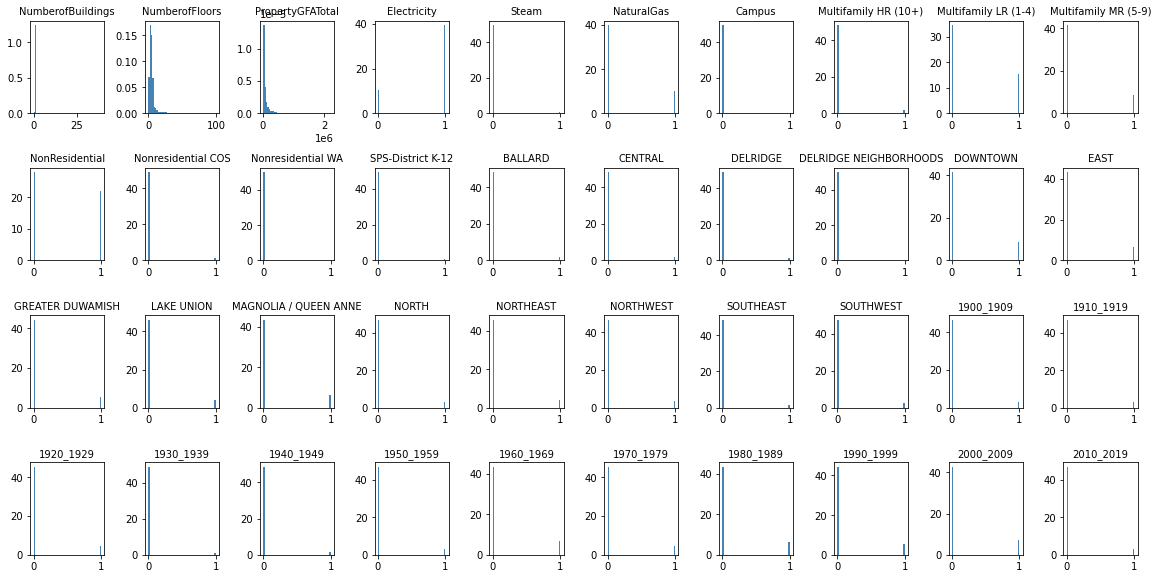

In [51]:
#besoin de standardiser ??

fig = plt.figure(figsize=(16, 12))
i=0
for col in X_Ridge.columns:
    ax = fig.add_subplot(6,10, i+1)
    h = ax.hist(X_Ridge[col][:], bins=50, color='steelblue', density=True, edgecolor='none')
    ax.set_title(col, fontsize=10)
    i=i+1
fig.tight_layout()


# --> Yes / first two columns?



In [52]:
# standardise the data
from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_Ridge_std = std_scale.transform(X_train_Ridge)
X_test_Ridge_std = std_scale.transform(X_test_Ridge)

X_Ridge_std=std_scale.transform(X_Ridge)

In [53]:
X_Ridge_std

array([[-0.07152865,  1.28978742, -0.0170721 , ..., -0.35711114,
        -0.41406586, -0.25251815],
       [-0.07152865,  1.11165054,  0.08452507, ...,  2.80024868,
        -0.41406586, -0.25251815],
       [-0.07152865,  6.45575704,  5.84803614, ..., -0.35711114,
        -0.41406586, -0.25251815],
       ...,
       [-0.07152865, -0.6697183 , -0.52248647, ..., -0.35711114,
        -0.41406586, -0.25251815],
       [-0.07152865, -0.6697183 , -0.51614839, ..., -0.35711114,
        -0.41406586, -0.25251815],
       [-0.07152865, -0.6697183 , -0.48823804, ..., -0.35711114,
        -0.41406586, -0.25251815]])

In [770]:
df_std=pd.DataFrame(X_Ridge_std,columns=xtrain_columns_V2)

In [775]:
df_NRJ.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEnergyUse(kBtu),GHGEmissions(MetricTonsCO2e),ThirdLargestPropertyUseTypeGFA,Electricity,Steam,NaturalGas,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Other,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility
count,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,1714.000000,2.508000e+03,2508.000000,1234.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000,2508.000000
mean,16985.303030,2015.492026,98117.165869,4.287480,1957.863238,1.007974,2.978070,62463.786284,62.586348,3.416509e+06,67.904617,1293.532658,0.757177,0.009569,0.231659,0.043461,0.030702,0.026316,0.198565,0.070574,0.233254,0.090510,0.094498,0.037879,0.076954,0.053828,0.019139,0.024322,0.070574,0.257177,0.112041,0.107257,0.079745,0.073764,0.299442,53.520734,0.093700,0.079346,0.104067,0.034689,0.042265,0.104466,0.143142,0.106061,0.098086,0.080144,0.092504,0.021531,0.010766,0.038676,0.000797,0.042663,0.030702,0.001196,0.072967,0.000797,0.021531,0.067384,0.124402,0.013955,0.007576,0.068979,0.022329,0.011164,0.228469,0.029107,0.151116,0.055423
std,12227.049109,0.500036,17.316627,2.182876,32.570883,0.289313,2.511703,52691.636353,28.792530,3.549765e+06,79.464548,4285.180214,0.428874,0.097373,0.421976,0.203933,0.172543,0.160105,0.398999,0.256163,0.422987,0.286969,0.292578,0.190941,0.266571,0.225722,0.137040,0.154078,0.256163,0.437165,0.315480,0.309501,0.270952,0.261438,0.458105,32.295578,0.291469,0.270332,0.305408,0.183027,0.201233,0.305925,0.350287,0.307977,0.297490,0.271569,0.289794,0.145175,0.103218,0.192861,0.028233,0.202138,0.172543,0.034572,0.260133,0.028233,0.145175,0.250736,0.330105,0.117329,0.086726,0.253469,0.147779,0.105091,0.419930,0.168140,0.358234,0.228849
min,1.000000,2015.000000,98006.000000,1.000000,1900.000000,0.000000,0.000000,16300.000000,1.000000,0.000000e+00,-0.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,718.750000,2015.000000,98105.000000,2.000000,1927.000000,1.000000,1.000000,27593.500000,43.000000,1.067502e+06,16.067500,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000

In [772]:
df_std.describe()

,NumberofBuildings,NumberofFloors,PropertyGFATotal,Electricity,Steam,NaturalGas,SPS-District K-12,BALLARD,CENTRAL,DELRIDGE,DOWNTOWN,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,SOUTHEAST,SOUTHWEST,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,College/University,Distribution Center,Hospital,Hotel,K_12 School,Laboratory,Large Office,Low-Rise Multifamily,Medical Office,Mixed Use Property,Non-Refrigerated Warehouse,Other,Refrigerated Warehouse,Residence Hall/Dormitory,Restaurant,Retail Store,Self_Storage Facility,Senior Care Community,Small- and Mid-Sized Office,Supermarket_Grocery Store,Warehouse,Worship Facility
count,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.0,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000,2504.000000
mean,-0.001971,0.016010,0.003925,0.014139,-0.006836,-0.012724,0.0,0.021320,0.007387,0.007948,-0.004223,0.030093,-0.008970,-0.013979,0.008150,-0.004522,0.002230,-0.013638,-0.001718,-0.018600,-0.001124,0.024645,-0.005181,-0.021063,0.003331,-0.019433,-0.006174,0.011496,-0.011106,0.016455,0.007226,0.004358,0.024108,-0.003319,-0.010153,0.005329,0.009762,0.001674,0.009700,0.009544,0.003107,0.005156,-0.001673,-0.018118,-0.008310,-0.015981,-0.016237,0.026809,0.000705,-0.007390,0.015405,-0.005459,-0.007856,-0.027752
std,0.993288,1.021416,1.019063,0.991800,0.966401,0.992235,0.0,1.049267,1.020658,1.024012,0.997014,1.052339,0.994608,0.980563,1.011617,0.989330,1.003745,0.973713,0.994192,0.944621,0.998636,1.039562,0.993488,0.948329,1.007807,0.975597,0.993954,1.015067,0.985380,1.026082,1.010461,1.014813,1.121207,0.992302,0.836780,1.012338,1.027140,1.024637,1.016343,1.183047,1.010493,1.009143,0.997422,0.979978,0.960105,0.936340,0.912413,1.047329,1.002479,0.966457,1.010335,0.984937,0.987063,0.948151
min,-3.459900,-1.213385,-0.888682,-1.742661,-0.101885,-0.558012,0.0,-0.202480,-0.173154,-0.160503,-0.499643,-0.260080,-0.558012,-0.323521,-0.318110,-0.200948,-0.287782,-0.246034,-0.140679,-0.167836,-0.322443,-0.280745,-0.342559,-0.200948,-0.208514,-0.352872,-0.412723,-0.338384,-0.336285,-0.286617,-0.314836,-0.144841,-0.092928,-0.202480,-0.033806,-0.208514,-0.173154,-0.033806,-0.274784,-0.023898,-0.146882,-0.266279,-0.278372,-0.387764,-0.104707,-0.127441,-0.096003,-0.257570,-0.150888,-0.110144,-0.534228,-0.174895,-0.278372,-0.257570
25%,-0.029371,-0.799231,-0.670440,0.573835,-0.101885,-0.558012,0.0,-0.202480,-0.173154,-0.160503,-0.499643,-0.260080,-0.558012,-0.323521,-0.318110,-0.200948,-0.287782,-0.246034,-0.140679,-0.167836,-0.322443,-0.280745,-0.342559,-0.200948,-0.208514,-0.352872,-0.412723,-0.338384,-0.336285,-0.286617,-0.314836,-0.144841,-0.092928,-0.202480,-0.033806,-0.208514,-0.173154,-0.033806,-0.274784,-0.023898,-0.146882,-0.266279,-0.278372,-0.387764,-0.104707,-0.127441,-0.096003,-0.257570,-0.150888,-0.110144,-0.534228,-0.174895,-0.278372,-0.257570
50%,-0.029371,-0.385078,-0.394889,0.573835,-0.101885,-0.558012,0.0,-0.202480,-0.173154,-0.160503,-0.499643,-0.260080,-0.558012,-0.323521,-0.318110,-0.200948,-0.287782,-0.246034,-0.140679,-0.167836,-0.322443,-0.280745,-0.342559,-0.200948,-0.208514,-0.352872,-0.412723,-0.338384,-0.336285,-0.286617,-0.314836,-0.144841,-0.092928,-0.202480,-0.033806,-0.208514,-0.173154,-0.033806,-0.274784,-0.023898,-0.146882,-0.266279,-0.278372,-0.387764,-0.104707,-0.127441,-0.096003,-0.257570,-0.150888,-0.110144,-0.534228,-0.174895,-0.278372,-0.257570
75%,-0.029371

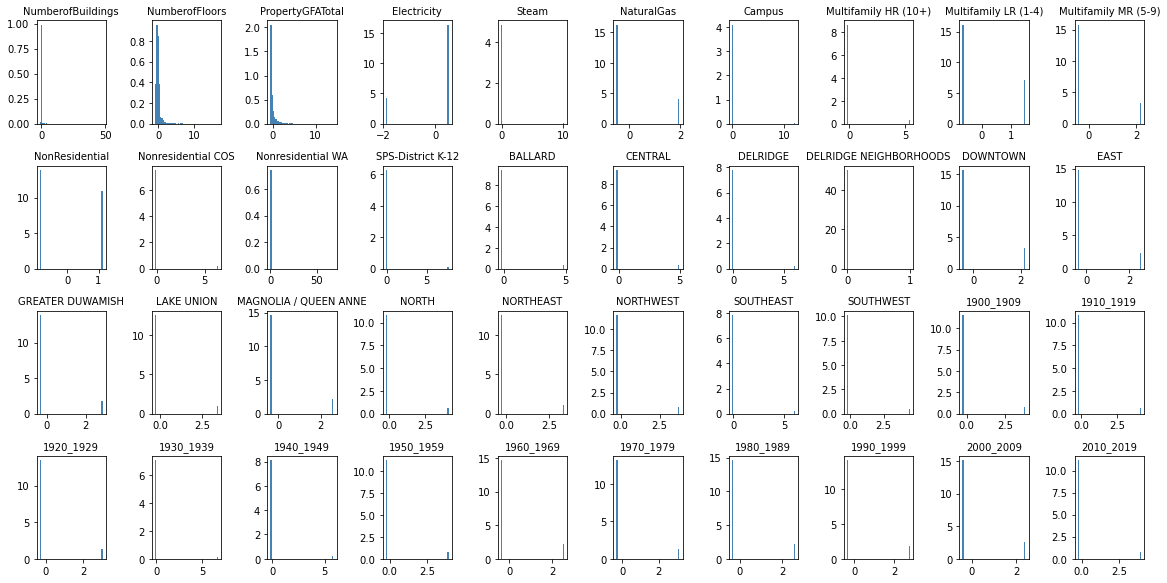

In [54]:

fig = plt.figure(figsize=(16, 12))

for feat_idx in range(X_Ridge_std.shape[1]):
    ax = fig.add_subplot(6,10, (feat_idx+1))
    h = ax.hist(X_Ridge_std[:, feat_idx], bins=50, color = 'steelblue', density=True, edgecolor='none')
    ax.set_title(X_Ridge.columns[feat_idx], fontsize=10)
    
fig.tight_layout()

In [55]:
# We can now train a kernel ridge regression on the training set using
# default values for the regularisation parameter and the Gaussian RBF kernel bandwidth:

import numpy as np

from sklearn import kernel_ridge
predicteur_Ridge = kernel_ridge.KernelRidge(
    alpha=1.0, # default value
    kernel='rbf', # noyau Gaussien
    gamma=0.01)   # valeur de 1/(2 * sigma**2)
                                     
# train the model on the training set
predicteur_Ridge.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set
y_test_Ridge_pred = predicteur_Ridge.predict(X_test_Ridge_std)

# compute the RMSE on the test set
from sklearn import metrics
rmse = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred))
print("RMSE: {:.2f}".format(rmse))

RMSE: 251.35


In [56]:
#predicteur_Ridge.best_params_

In [57]:
from sklearn.metrics import r2_score

print(r2_score(y_test_Ridge, y_test_Ridge_pred))





0.38025614839271993


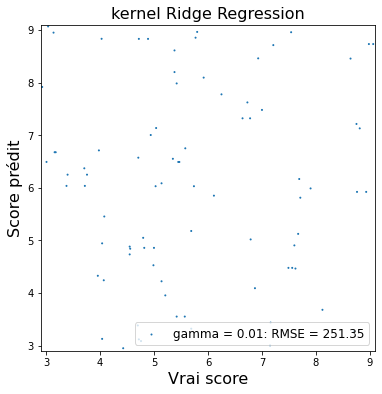

In [58]:

from matplotlib import pyplot as plt

# create a figure

fig = plt.figure(figsize=(6, 6))

# For each pair (y, y') where y is a true value and y' the predicted value, count
# the number of such pairs.
# This count is used to scale the corresponding markers
# in a scatter plot
sizes = {}
for (yt, yp) in zip(list(y_test_Ridge), list(y_test_Ridge_pred)):
    if (yt, yp) in sizes.keys():
        sizes[(yt, yp)] += 1
    else:
        sizes[(yt, yp)] = 1        
keys = sizes.keys()

# plot the predictions
plt.scatter([k[0] for k in keys], 
            [k[1] for k in keys], 
             s=[sizes[k] for k in keys], 
            label="gamma = 0.01: RMSE = {:.2f}".format(rmse))

# label the axes and the chart
plt.xlabel('Vrai score', fontsize=16)
plt.ylabel(u'Score prédit', fontsize=16)
plt.title('kernel Ridge Regression', fontsize=16)

# axis limits
plt.xlim([2.9, 9.1])
plt.ylim([2.9, 9.1])

# show the legend
plt.legend(loc="lower right", fontsize=12)

In [59]:
y_test_Ridge_pred
df_visualisation=pd.DataFrame(y_test_Ridge_pred)

In [60]:
y_test_Ridge2=y_test_Ridge.reset_index()

In [61]:
y_test_Ridge2.drop('index',axis='columns',inplace=True)

In [160]:
start_time = timeit.default_timer()

# values of parameter C
alpha_range = np.logspace(-2, 2, 5)

# values of parameter gamma
gamma_range = np.logspace(-2, 1, 4)

# parameter grid
param_grid = {'alpha': alpha_range, 'gamma': gamma_range}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_Ridge = model_selection.GridSearchCV(
        kernel_ridge.KernelRidge(kernel='rbf'),
        param_grid,
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_Ridge.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set with the selected model
y_test_Ridge_pred_cv = grid_pred_Ridge.predict(X_test_Ridge_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred_cv))


elapsed = timeit.default_timer() - start_time

print(elapsed)



In [161]:
grid_pred_Ridge.best_params_

{'alpha': 1.0, 'gamma': 0.01}

In [162]:
rmse_cv

377.8673540253454

In [163]:
print(r2_score(y_test_Ridge, y_test_Ridge_pred))

0.4396064878268354


In [164]:
print(r2_score(y_test_Ridge, y_test_Ridge_pred_cv))


0.4396064878268354


In [165]:
rmse = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred))


In [166]:
rmse

377.8673540253454

##### RMSE : 

In [167]:
metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred)

142783.73723811572

In [168]:
metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred_cv)

142783.73723811572

In [169]:
#### Show the distribution of y
#### Look for metrics to handle skewness (log transform above a given skewness value)
#### Log-transform the target to reduce skewness

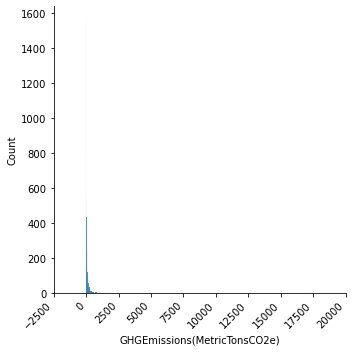

In [170]:
a=sns.displot(data=df_NRJ['GHGEmissions(MetricTonsCO2e)'])
a.set_xticklabels(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [171]:
df_NRJ['GHGEmissions(MetricTonsCO2e)'].describe()

count     6532.000000
mean       116.127936
std        484.567028
min          0.080000
25%          9.487500
50%         33.225000
75%         92.002500
max      16870.980000
Name: GHGEmissions(MetricTonsCO2e), dtype: float64

In [172]:
# remove negative CO2 emissions

# df_NRJ=df_NRJ[df_NRJ['GHGEmissions(MetricTonsCO2e)']>0]

In [173]:
df_NRJ['GHGEmissions(MetricTonsCO2e)'].describe()

count     6532.000000
mean       116.127936
std        484.567028
min          0.080000
25%          9.487500
50%         33.225000
75%         92.002500
max      16870.980000
Name: GHGEmissions(MetricTonsCO2e), dtype: float64

In [174]:
df_NRJ.isna().sum()

OSEBuildingID                          0
DataYear                               0
BuildingType                           0
PrimaryPropertyType                    0
Address                                0
ZipCode                               13
TaxParcelIdentificationNumber          2
CouncilDistrictCode                    0
Neighborhood                           0
YearBuilt                              0
log_GHGEmissions(MetricTonsCO2e)       0
NumberofBuildings                      0
NumberofFloors                         0
PropertyGFATotal                       0
ENERGYSTARScore                     1576
SiteEnergyUse(kBtu)                    0
ComplianceStatus                       0
GHGEmissions(MetricTonsCO2e)           0
Electricity                            0
Steam                                  0
NaturalGas                             0
Campus                                 0
Multifamily HR (10+)                   0
Multifamily LR (1-4)                   0
Multifamily MR (

#### Log transform of y:

In [141]:
#df_NRJ['log_GHGEmissions(MetricTonsCO2e)']=np.log(df_NRJ['GHGEmissions(MetricTonsCO2e)'])

In [75]:


df_NRJ_NoNan=df_NRJ[~df_NRJ['log_GHGEmissions(MetricTonsCO2e)'].isna()]

X_Ridge = df_NRJ_NoNan[xtrain_columns_V2]
y_Ridge = df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_Ridge, X_test_Ridge, y_train_Ridge, y_test_Ridge = \
    model_selection.train_test_split(X_Ridge, y_Ridge, test_size=0.3)

std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_Ridge_std = std_scale.transform(X_train_Ridge)
X_test_Ridge_std = std_scale.transform(X_test_Ridge)

X_Ridge_std=std_scale.transform(X_Ridge)

In [77]:
from sklearn import kernel_ridge
predicteur_Ridge = kernel_ridge.KernelRidge(
    alpha=1.0, # default value
    kernel='rbf', # noyau Gaussien
    gamma=0.01)   # valeur de 1/(2 * sigma**2)
                                     
# train the model on the training set
predicteur_Ridge.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set
y_test_Ridge_pred = predicteur_Ridge.predict(X_test_Ridge_std)

# compute the RMSE on the test set
from sklearn import metrics
rmse = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred))
print("RMSE: {:.2f}".format(rmse))

RMSE: 0.86


In [145]:
print("R2 : "+str(r2_score(y_test_Ridge, y_test_Ridge_pred)))

R2 : 0.5517012979258118


In [560]:
# CV

In [146]:
start_time = timeit.default_timer()


# values of parameter C
alpha_range = np.logspace(-2, 2, 5)

# values of parameter gamma
gamma_range = np.logspace(-2, 1, 4)

# parameter grid
param_grid = {'alpha': alpha_range, 'gamma': gamma_range}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_Ridge_log = model_selection.GridSearchCV(
        kernel_ridge.KernelRidge(kernel='rbf'),
        param_grid,
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_Ridge_log.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set with the selected model
y_test_Ridge_pred_cv = grid_pred_Ridge_log.predict(X_test_Ridge_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred_cv))


elapsed = timeit.default_timer() - start_time

print(elapsed)

14.47433809999984


In [147]:
grid_pred_Ridge_log.best_params_

{'alpha': 0.1, 'gamma': 0.01}

In [148]:
# R2 : 
#print("R2 : "+str(r2_score(y_test_Ridge, y_test_Ridge_pred_cv)))


In [149]:
#print("RMSE: {:.2f}".format(rmse_cv))

In [78]:
Ridge_opt=kernel_ridge.KernelRidge(kernel='rbf',alpha=0.01,gamma=0.01)

start_time = timeit.default_timer()

Ridge_opt.fit(X_train_Ridge_std, y_train_Ridge)

elapsed = timeit.default_timer() - start_time

print(elapsed)

pred_Ridge_opt=Ridge_opt.predict(X_test_Ridge_std)
score_RMSE_Ridge_opt=mean_squared_error(y_test_Ridge,pred_Ridge_opt)
score_R2_Ridge_opt=Ridge_opt.score(X_test_Ridge_std, y_test_Ridge)

0.14704229999995277


In [152]:
score_RMSE_Ridge_opt

0.6111317861778773

In [153]:
score_R2_Ridge_opt

0.6264284319880162

In [159]:
## feature optimisation:
# look for the most important features to improve the score

from sklearn.inspection import permutation_importance
r = permutation_importance(Ridge_opt, X_test_Ridge_std, y_test_Ridge,
                         n_repeats=30,
                            random_state=0)

r.importances_mean.argsort()[::-1]

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print(f"{df_NRJ_train.columns[i]:<8}"
              f"{r.importances_mean[i]:.3f}"
              f" +/- {r.importances_std[i]:.3f}")

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print("'"+f"{df_NRJ_train.columns[i]:<8}"+"',")


log_PropertyGFATotal0.525 +/- 0.036
Warehouse0.253 +/- 0.018
log_NumberofFloors0.141 +/- 0.015
Self_Storage Facility0.104 +/- 0.014
Electricity0.095 +/- 0.013
Supermarket_Grocery Store0.073 +/- 0.009
NaturalGas0.071 +/- 0.012
DOWNTOWN0.067 +/- 0.008
Small- and Mid-Sized Office0.067 +/- 0.010
2000_20090.065 +/- 0.006
GREATER DUWAMISH0.053 +/- 0.008
MAGNOLIA / QUEEN ANNE0.052 +/- 0.007
1980_19890.051 +/- 0.007
Retail Store0.051 +/- 0.010
Distribution Center0.049 +/- 0.006
1900_19090.046 +/- 0.009
Other   0.040 +/- 0.007
1910_19190.038 +/- 0.008
Mixed Use Property0.038 +/- 0.006
EAST    0.038 +/- 0.006
Large Office0.037 +/- 0.007
1940_19490.035 +/- 0.008
1970_19790.035 +/- 0.008
1920_19290.032 +/- 0.006
1990_19990.032 +/- 0.007
Worship Facility0.031 +/- 0.007
2010_20190.031 +/- 0.010
BALLARD 0.031 +/- 0.006
NORTHEAST0.027 +/- 0.005
LAKE UNION0.027 +/- 0.004
NORTHWEST0.027 +/- 0.006
1950_19590.026 +/- 0.006
1930_19390.024 +/- 0.006
CENTRAL 0.019 +/- 0.006
1960_19690.018 +/- 0.005
SOUTHEAST

In [160]:
x_opt=['log_PropertyGFATotal',
'Warehouse',
'log_NumberofFloors',
'Self_Storage Facility',
'Electricity',
'Supermarket_Grocery Store',
'NaturalGas',
'DOWNTOWN',
'Small- and Mid-Sized Office',
'2000_2009']

In [161]:
df_NRJ_NoNan=df_NRJ[~df_NRJ['log_GHGEmissions(MetricTonsCO2e)'].isna()]

X_Ridge = df_NRJ_NoNan[x_opt]
y_Ridge = df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_Ridge, X_test_Ridge, y_train_Ridge, y_test_Ridge = \
    model_selection.train_test_split(X_Ridge, y_Ridge, test_size=0.3)

std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_Ridge_std = std_scale.transform(X_train_Ridge)
X_test_Ridge_std = std_scale.transform(X_test_Ridge)

X_Ridge_std=std_scale.transform(X_Ridge)



In [162]:
start_time = timeit.default_timer()


# values of parameter C
alpha_range = np.logspace(-2, 2, 5)

# values of parameter gamma
gamma_range = np.logspace(-2, 1, 4)

# parameter grid
param_grid = {'alpha': alpha_range, 'gamma': gamma_range}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_Ridge_log = model_selection.GridSearchCV(
        kernel_ridge.KernelRidge(kernel='rbf'),
        param_grid,
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_Ridge_log.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set with the selected model
y_test_Ridge_pred_cv = grid_pred_Ridge_log.predict(X_test_Ridge_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred_cv))


elapsed = timeit.default_timer() - start_time

print(elapsed)

11.214798500000143


In [163]:
grid_pred_Ridge_log.best_params_

{'alpha': 0.01, 'gamma': 0.01}

In [164]:
Ridge_opt=kernel_ridge.KernelRidge(kernel='rbf',alpha=0.01,gamma=0.01)
Ridge_opt.fit(X_train_Ridge_std, y_train_Ridge)
pred_Ridge_opt=Ridge_opt.predict(X_test_Ridge_std)
score_RMSE_Ridge_opt=mean_squared_error(y_test_Ridge,pred_Ridge_opt)
score_R2_Ridge_opt=Ridge_opt.score(X_test_Ridge_std, y_test_Ridge)

In [165]:
score_RMSE_Ridge_opt

0.9174771482380775

In [166]:
score_R2_Ridge_opt

0.4347182075347713

## Random Forest   --> ok

In [154]:
# Model standardised on X, without log transform of y

df_NRJ_NoNan=df_NRJ[~df_NRJ['GHGEmissions(MetricTonsCO2e)'].isna()]

X_RF = df_NRJ_NoNan[xtrain_columns_V2]
y_RF = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_RF, X_test_RF, y_train_RF, y_test_RF = \
    model_selection.train_test_split(X_RF, y_RF, test_size=0.3)

In [82]:
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor(n_estimators=500, oob_score=True)

In [156]:
std_scale = preprocessing.StandardScaler().fit(X_train_RF)
X_train_RF_std = std_scale.transform(X_train_RF)
X_test_RF_std = std_scale.transform(X_test_RF)

X_RF_std=std_scale.transform(X_RF)

In [157]:
model = rfr.fit(X_train_RF_std, y_train_RF)

In [90]:
pred = rfr.predict(X_test_RF_std)


In [91]:
rfr.score(X_test_RF_std, y_test_RF)

0.6576563188581513

In [92]:
from sklearn import metrics

metrics.r2_score(y_test_RF, pred)

0.6576563188581513

In [93]:
X_RF_std.shape

(2501, 50)

In [94]:
### feature selection

from sklearn.feature_selection import SelectFromModel
select = SelectFromModel(rfr, prefit=True, threshold=0.01)
X_train_RF2_std = select.transform(X_train_RF_std)
print(X_train_RF2_std.shape)

(1750, 19)


In [95]:
X_test_RF2_std = select.transform(X_test_RF_std)

In [96]:
model = rfr.fit(X_train_RF2_std, y_train_RF)

rfr.score(X_test_RF2_std, y_test_RF)

0.6140417099159123

In [97]:
pred2 = rfr.predict(X_test_RF2_std)

metrics.r2_score(y_test_RF, pred2)

0.6140417099159123

In [98]:


start_time = timeit.default_timer()

model = rfr.fit(X_train_RF2_std, y_train_RF)

rfr.score(X_train_RF2_std, y_train_RF)

elapsed = timeit.default_timer() - start_time

#print(rfc.score)

print(elapsed)

2.422427599999992


In [99]:


start_time = timeit.default_timer()

model = rfr.fit(X_train_RF_std, y_train_RF)

rfr.score(X_train_RF_std, y_train_RF)

elapsed = timeit.default_timer() - start_time

#print(rfc.score)

print(elapsed)

4.022149599999921


OK, this new model does not change much except run time: 1 s faster with fewer features.

##### RMSE :

In [100]:
metrics.mean_squared_error(y_test_RF, pred)

2148.9265768948358

In [101]:
metrics.mean_squared_error(y_test_RF, pred2)

2422.6999732205536

In [102]:
# Model standardised on X, with log transform of y

In [103]:
#df_NRJ['log_GHGEmissions(MetricTonsCO2e)']=np.log(df_NRJ['GHGEmissions(MetricTonsCO2e)'])

In [79]:
X_RF = df_NRJ[xtrain_columns_V2]
y_RF_log = df_NRJ['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_RF, X_test_RF, y_train_RF_log, y_test_RF_log = \
    model_selection.train_test_split(X_RF, y_RF_log, test_size=0.1)

In [80]:
std_scale = preprocessing.StandardScaler().fit(X_train_RF)
X_train_RF_std = std_scale.transform(X_train_RF)
X_test_RF_std = std_scale.transform(X_test_RF)

X_RF_std=std_scale.transform(X_RF)

In [175]:
model = rfr.fit(X_train_RF_std, y_train_RF_log)

In [176]:
pred = rfr.predict(X_test_RF_std)


In [177]:
rfr.score(X_test_RF_std, y_test_RF_log)

0.7850764335145807

In [178]:
metrics.mean_squared_error(y_test_RF_log, pred)

0.34481853576624943

In [110]:
# Cross-validated optimisation of the standardised model with log transform (no extra parameters, otherwise too slow)

In [179]:
start_time = timeit.default_timer()


# parameter grid
param_grid = { 
    'n_estimators': [200, 700],
    'max_features': ['auto', 'sqrt', 'log2']
}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_RF = model_selection.GridSearchCV(
        param_grid=param_grid,
        estimator=RandomForestRegressor(param_grid),
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_RF.fit(X_train_RF_std, y_train_RF_log)

# predict on the test set with the selected model
y_test_log_pred_cv = grid_pred_RF.predict(X_test_RF_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_RF_log, y_test_log_pred_cv))


elapsed = timeit.default_timer() - start_time

print(elapsed)

In [ ]:
grid_pred_RF.best_params_

In [113]:

rmse_cv

0.6853842277905977

In [114]:
y_test_log_pred_cv.shape

(751,)

In [115]:
rfr.score(X_test_RF_std, y_test_log_pred_cv)

0.9566615443210237

In [116]:
rfr_opt = RandomForestRegressor(n_estimators=200, max_features='auto')

rfr_opt.fit(X_train_RF_std, y_train_RF_log)
y_test_log_pred_cv = rfr_opt.predict(X_test_RF_std)

rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_RF_log, y_test_log_pred_cv))
r2_rfr=rfr_opt.score(X_test_RF_std, y_test_log_pred_cv)

In [117]:
rmse_cv

0.6849031734901693

In [118]:
r2_rfr

1.0

In [119]:
# Hyperopt :

In [180]:
start_time = timeit.default_timer()



seed=2

def objective(params):
    mf=float(params['max_features'])
    est=int(params['n_estimators'])
    md=float(params['max_depth'])
    msl=int(params['min_samples_leaf'])
    mss=int(params['min_samples_split'])
    nj=(params['n_jobs'])
    
    model=RandomForestRegressor(max_features=mf,n_estimators=est,max_depth=md,min_samples_leaf=msl,min_samples_split=mss,n_jobs=nj)
    model.fit(X_train_RF_std, y_train_RF_log)
    pred=model.predict(X_test_RF_std)
    score_RMSE=mean_squared_error(y_test_RF_log, pred)
    score_R2=model.score(X_test_RF_std, y_test_RF_log)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'max_features':hp.uniform('max_features',0.0,1.0),
           'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5.0,20.0),
           'min_samples_leaf':hp.uniform('min_samples_leaf',1,5),
           'min_samples_split':hp.uniform('min_samples_split',2.0,6.0),
           'n_jobs':hp.choice('n_jobs',[-1,1])}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=50,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)



100%|███████████████████████████████████████████████| 50/50 [00:48<00:00,  1.04trial/s, best loss: 0.39161896014288383]
48.19949120000001


In [181]:
best

{'max_depth': 17.345603882956127,
 'max_features': 0.47194067017666297,
 'min_samples_leaf': 1.583631945561164,
 'min_samples_split': 2.373167820699558,
 'n_estimators': 284.3372366080888,
 'n_jobs': 1}

In [83]:


rfr_opt=RandomForestRegressor(max_features=0.65,n_estimators=284,max_depth=17,
                              min_samples_leaf=1,min_samples_split=2)


start_time = timeit.default_timer()

rfr_opt.fit(X_train_RF_std, y_train_RF_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)

pred_rfr_opt=rfr_opt.predict(X_test_RF_std)
score_RMSE_rfr_opt=mean_squared_error(y_test_RF_log,pred_rfr_opt)
score_R2_rfr_opt=rfr_opt.score(X_test_RF_std, y_test_RF_log)

1.7109530000000177


In [108]:
score_RMSE_rfr_opt

0.37668398737017994

In [109]:
score_R2_rfr_opt

0.7799843506126513

In [110]:
# init :
shap.initjs()



<IPython.core.display.HTML object>

In [111]:
explainer = shap.TreeExplainer(rfr_opt)
shap_values = explainer.shap_values(X_test_RF_std)


In [112]:

# unique value :
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_RF_std[0,:])


In [112]:

# global : 
shap.force_plot(explainer.expected_value, shap_values, X_test_RF_std)

In [113]:
xtrain_columns_V2

['log_NumberofFloors',
 'log_PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Other',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office',
 'Supermarket_Grocery Store',
 'Warehouse',
 'Worship Facility']

## G Boost    --> warning future version

In [138]:


df_NRJ_NoNan=df_NRJ[~df_NRJ['GHGEmissions(MetricTonsCO2e)'].isna()]

X_GB = df_NRJ_NoNan[xtrain_columns_V2]
y_GB = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_GB, X_test_GB, y_train_GB, y_test_GB = \
    model_selection.train_test_split(X_GB, y_GB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_GB)
X_train_GB_std = std_scale.transform(X_train_GB)
X_test_GB_std = std_scale.transform(X_test_GB)

X_Ridge_std=std_scale.transform(X_GB)


In [139]:

est = GradientBoostingRegressor(n_estimators=100, learning_rate=0.01,
    max_depth=3, random_state=0, loss='ls').fit(X_train_GB_std, y_train_GB)

mean_squared_error(y_test_GB, est.predict(X_test_GB_std))

243197.14168025675

In [140]:
metrics.r2_score(y_test_GB, est.predict(X_test_GB_std))

0.3319664904094801

##### RMSE :

In [141]:
metrics.mean_squared_error(y_test_GB,est.predict(X_test_GB_std))

243197.14168025675

In [142]:
# log-transform y:

In [608]:
X_GB = df_NRJ_NoNan[xtrain_columns_V2]
y_GB = df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_GB, X_test_GB, y_train_GB_log, y_test_GB_log = \
    model_selection.train_test_split(X_GB, y_GB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_GB)
X_train_GB_std = std_scale.transform(X_train_GB)
X_test_GB_std = std_scale.transform(X_test_GB)

X_GB_std=std_scale.transform(X_GB)

In [609]:

est = GradientBoostingRegressor(n_estimators=100, learning_rate=0.01,
    max_depth=3, random_state=0, loss='ls').fit(X_train_GB_std, y_train_GB_log)

mean_squared_error(y_test_GB_log, est.predict(X_test_GB_std))

1.0111338641552776

In [610]:
metrics.r2_score(y_test_GB_log, est.predict(X_test_GB_std))

0.3459523543351065

In [146]:
# optimise with y_log -> Grid CV

In [147]:
sklearn.__version__

'0.23.2'

In [148]:
### Erreur future warning !
import warnings

# run block of code and catch warnings
with warnings.catch_warnings():
# ignore all caught warnings
    warnings.filterwarnings("ignore")
	# execute code that will generate warnings



# values of parameter learning_rate
 #learning_rate = [0.0001,0.001,0.01,0.1,1]

    start_time = timeit.default_timer()
   
    
# values of parameter gamma
    max_depth = [2,4,6]

# parameter grid
    param_grid = {'n_estimators': [200, 700],#'learning_rate': learning_rate, 
              'max_depth': max_depth,'max_features': ['auto', 'sqrt', 'log2']}


# score used to select the best model
    score = 'neg_mean_squared_error'

# initialise cross-validation
    grid_pred_GB = model_selection.GridSearchCV(
        param_grid=param_grid,        
        estimator=GradientBoostingRegressor(param_grid),
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
    grid_pred_GB.fit(X_train_GB_std, y_train_GB_log)

# predict on the test set with the selected model
    y_test_log_pred_cv_GB = grid_pred_GB.predict(X_test_GB_std)

# compute the corresponding RMSE
    rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_GB_log, y_test_log_pred_cv_GB))


    elapsed = timeit.default_timer() - start_time

    print(elapsed)

In [149]:
grid_pred_GB.best_params_

{'max_depth': 2, 'max_features': 'auto', 'n_estimators': 200}

In [150]:
rmse_cv

0.6695241867089883

In [151]:
metrics.r2_score(y_test_log_pred_cv_GB, est.predict(X_test_GB_std))

## Kernel SVM     --> ok

In [84]:


#df_NRJ_NoNan=df_NRJ[~df_NRJ['GHGEmissions(MetricTonsCO2e)'].isna()]

X_SVM = df_NRJ_NoNan[xtrain_columns_V2]
y_SVM = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_SVM, X_test_SVM, y_train_SVM, y_test_SVM = \
    model_selection.train_test_split(X_SVM, y_SVM, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_SVM_std = std_scale.transform(X_train_SVM)
X_test_SVM_std = std_scale.transform(X_test_SVM)

X_SVM_std=std_scale.transform(X_SVM)


In [153]:
# Create an SVM with a Gaussian kernel, gamma=0.01
from sklearn import svm
SVM_regressor = svm.SVR(kernel='rbf', gamma=0.01)

# Train the SVM on the training set
SVM_regressor.fit(X_train_SVM_std, y_train_SVM)

SVR(gamma=0.01)

In [154]:
# predict on the test set
y_test_SVM_pred = SVM_regressor.predict(X_test_SVM_std)

metrics.r2_score(y_test_SVM, y_test_SVM_pred)


0.01413070655648585

In [155]:
y_test_array=asarray(y_test_SVM)
y_pred_array=asarray(y_test_SVM_pred)

In [156]:
y_pred_array

array([ 6.13271195, 30.3585717 , 65.64850466, ...,  6.3559852 ,
       54.58267743, 39.79612899])

##### RMSE : 

In [157]:
metrics.mean_squared_error(y_test_SVM,y_test_SVM_pred)

60344.110811943574

In [234]:
# log-transform y:

In [85]:
X_SVM = df_NRJ_NoNan[xtrain_columns_V2]
y_SVM_log = df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_SVM, X_test_SVM, y_train_SVM_log, y_test_SVM_log = \
    model_selection.train_test_split(X_SVM, y_SVM_log, test_size=0.1)


std_scale = preprocessing.StandardScaler().fit(X_train_SVM)
X_train_SVM_std = std_scale.transform(X_train_SVM)
X_test_SVM_std = std_scale.transform(X_test_SVM)

X_SVM_std=std_scale.transform(X_SVM)

In [86]:
# Create an SVM with a Gaussian kernel, gamma=0.01
from sklearn import svm
SVM_regressor = svm.SVR(kernel='linear', gamma=0.01,C=2,epsilon=0.2)

# Train the SVM on the training set
SVM_regressor.fit(X_train_SVM_std, y_train_SVM_log)

SVR(C=2, epsilon=0.2, gamma=0.01, kernel='linear')

In [192]:
# predict on the test set
y_test_SVM_pred_log = SVM_regressor.predict(X_test_SVM_std)

metrics.r2_score(y_test_SVM_log, y_test_SVM_pred_log)


0.5007473598362067

In [193]:
metrics.mean_squared_error(y_test_SVM_log,y_test_SVM_pred_log)

0.822709050711909

In [194]:
start_time = timeit.default_timer()



# parameter grid
parameters = {'kernel': ['linear', 'sigmoid', 'poly', 'rbf'], 'C':[1.5, 10],'gamma': [1e-7, 1e-4],'epsilon':[0.1,0.2,0.5,0.3]}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_SVM = model_selection.GridSearchCV(
        param_grid=parameters,
        estimator=svm.SVR(param_grid),
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_SVM.fit(X_train_SVM_std, y_train_SVM_log)

# predict on the test set with the selected model
y_test_log_pred_cv_SVM = grid_pred_SVM.predict(X_test_SVM_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_SVM_log, y_test_log_pred_cv_SVM))



elapsed = timeit.default_timer() - start_time

print(elapsed)

 50%|████████████████████████▌                        | 5/10 [00:25<00:16,  3.36s/trial, best loss: 0.6846308177338675]

In [ ]:
grid_pred_SVM.best_params_

In [87]:
SVM_opt=svm.SVR(C= 1.5, epsilon= 0.5, gamma= 1e-07, kernel= 'linear')

start_time = timeit.default_timer()

SVM_opt.fit(X_train_SVM_std, y_train_SVM_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)
pred_SVM_opt=SVM_opt.predict(X_test_SVM_std)
score_RMSE_SVM_opt=mean_squared_error(y_test_SVM_log,pred_SVM_opt)
score_R2_SVM_opt=SVM_opt.score(X_test_SVM_std, y_test_SVM_log)

1.021802600000001


In [ ]:
score_RMSE_SVM_opt

In [ ]:
score_R2_SVM_opt

## KNN      --> oK

In [89]:


#df_NRJ_NoNan=df_NRJ[~df_NRJ['GHGEmissions(MetricTonsCO2e)'].isna()]

X_KNN = df_NRJ_NoNan[xtrain_columns_V2]
y_KNN = df_NRJ_NoNan['GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_KNN, X_test_KNN, y_train_KNN, y_test_KNN = \
    model_selection.train_test_split(X_KNN, y_KNN, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_KNN)
X_train_KNN_std = std_scale.transform(X_train_KNN)
X_test_KNN_std = std_scale.transform(X_test_KNN)

X_KNN_std=std_scale.transform(X_KNN)


from sklearn import neighbors
knn=neighbors.KNeighborsRegressor(n_neighbors=2)
knn.fit(X_train_KNN_std,y_train_KNN)

KNeighborsRegressor(n_neighbors=2)

In [244]:
score=knn.score(X_test_KNN_std,y_test_KNN)
score

0.34502346093386904

<function matplotlib.pyplot.show(close=None, block=None)>

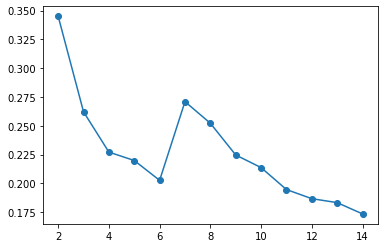

In [245]:
scores=[]
for k in range(2,15):
    knn=neighbors.KNeighborsRegressor(k)
    scores.append(knn.fit(X_train_KNN_std,y_train_KNN).score(X_test_KNN_std,y_test_KNN))
plt.plot(range(2,15),scores,'o-')
plt.show

best score for k=2

In [246]:
# Use if the best k differs from the initial k:

#knn=neighbors.KNeighborsRegressor(n_neighbors=5)
#knn.fit(X_train_KNN_std,y_train_KNN)

#score=knn.score(X_test_KNN_std,y_test_KNN)
#score

In [247]:
pred_y_knn = knn.predict(X_test_KNN_std)

In [248]:
metrics.r2_score(y_test_KNN, pred_y_knn)

0.17356183770487388

##### RMSE 

In [249]:
metrics.mean_squared_error(y_test_KNN,pred_y_knn)

122039.13166165844

In [250]:
# log-transform y:

In [90]:
X_KNN = df_NRJ_NoNan[xtrain_columns_V2]
y_KNN_log = df_NRJ_NoNan['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_KNN, X_test_KNN, y_train_KNN_log, y_test_KNN_log = \
    model_selection.train_test_split(X_KNN, y_KNN_log, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_KNN)
X_train_KNN_std = std_scale.transform(X_train_KNN)
X_test_KNN_std = std_scale.transform(X_test_KNN)

X_KNN_std=std_scale.transform(X_KNN)


from sklearn import neighbors
knn=neighbors.KNeighborsRegressor(n_neighbors=2)
knn.fit(X_train_KNN_std,y_train_KNN_log)

KNeighborsRegressor(n_neighbors=2)

In [612]:
score=knn.score(X_test_KNN_std,y_test_KNN_log)
score

0.29871725865821663

<function matplotlib.pyplot.show(close=None, block=None)>

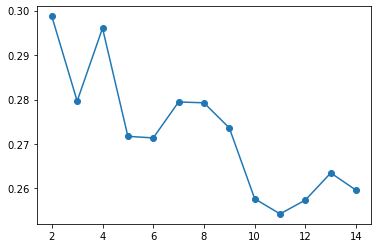

In [613]:
scores=[]
for k in range(2,15):
    knn=neighbors.KNeighborsRegressor(k)
    scores.append(knn.fit(X_train_KNN_std,y_train_KNN_log).score(X_test_KNN_std,y_test_KNN_log))
plt.plot(range(2,15),scores,'o-')
plt.show

In [614]:
pred_y_knn_log = knn.predict(X_test_KNN_std)

In [615]:
metrics.r2_score(y_test_KNN_log, pred_y_knn_log)

0.2596010601258848

In [616]:
metrics.mean_squared_error(y_test_KNN_log,pred_y_knn_log)

1.216177128728423

In [257]:
### grid search for KNN:

In [617]:
start_time = timeit.default_timer()


# parameter grid
param_grid = { 
    'n_neighbors':[2,3,4,5,6,7,8,9,10,11]
}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_KNN = model_selection.GridSearchCV(
        param_grid=param_grid,        
        estimator=neighbors.KNeighborsRegressor(param_grid),
        cv=5,
        scoring=score)
                                    
# run cross-validation on the training set
grid_pred_KNN.fit(X_train_KNN_std, y_train_KNN_log)

# predict on the test set with the selected model
y_test_log_pred_cv_KNN = grid_pred_KNN.predict(X_test_KNN_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_KNN_log, y_test_log_pred_cv_KNN))


elapsed = timeit.default_timer() - start_time

print(elapsed)

2.312544500000513


In [618]:
grid_pred_KNN.best_params_

{'n_neighbors': 11}

In [91]:
knn=neighbors.KNeighborsRegressor(n_neighbors=11)

start_time = timeit.default_timer()


knn.fit(X_train_KNN_std,y_train_KNN_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)

0.01908050000008643


In [260]:
rmse_cv

0.9161050338028776

In [261]:
metrics.r2_score(y_test_KNN_log, y_test_log_pred_cv_KNN)

0.6209341680272333

In [620]:
pred_y_knn_log = knn.predict(X_test_KNN_std)



In [621]:
metrics.r2_score(y_test_KNN_log, pred_y_knn_log)

0.2542848272397539

In [622]:
metrics.mean_squared_error(y_test_KNN_log,pred_y_knn_log)

1.2249095572867428

## XG BOOST  --> ok

In [227]:
# create an xgboost regression model
# model = xgboost.XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)

In [92]:
X_XGB = df_NRJ[xtrain_columns_V3]
y_XGB = df_NRJ['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

In [67]:
X_train_XGB_std

array([[-1.25046807, -0.21524238,  0.55226468, ..., -0.16245911,
        -0.41678402, -0.23420572],
       [-0.23961161, -1.2968297 , -1.81072599, ..., -0.16245911,
        -0.41678402, -0.23420572],
       [-0.23961161, -0.31785145,  0.55226468, ..., -0.16245911,
        -0.41678402, -0.23420572],
       ...,
       [ 0.35170152,  0.46150778,  0.55226468, ..., -0.16245911,
        -0.41678402, -0.23420572],
       [-1.25046807, -1.1068199 ,  0.55226468, ..., -0.16245911,
        -0.41678402, -0.23420572],
       [ 0.77124485,  2.0845048 ,  0.55226468, ..., -0.16245911,
        -0.41678402, -0.23420572]])

In [68]:
model = xgboost.XGBRegressor()

In [69]:
from sklearn import model_selection

# define model evaluation method (cross validation)
cv = model_selection.RepeatedKFold(n_splits=10, n_repeats=3, random_state=1)
# evaluate model
scores = model_selection.cross_val_score(model, X_train_XGB_std, y_train_XGB, scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)

In [70]:
from numpy import absolute 

# force scores to be positive

scores = absolute(scores)
print('Mean MAE: %.3f (%.3f)' % (scores.mean(), scores.std()) )

Mean MAE: 0.490 (0.036)


In [71]:
from numpy import asarray

# fit model
model.fit(X_train_XGB_std, y_train_XGB)

# make a prediction
Xarray=asarray(X_test_XGB_std)

y_pred_XGB = model.predict(Xarray)

In [72]:
metrics.r2_score(y_test_XGB, y_pred_XGB)

0.648437988445123

In [73]:
# hyperopt


start_time = timeit.default_timer()


seed=2

#model = xgboost.XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)


def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    eta=float(params['eta'])
    sbs=int(params['subsample'])
    csb=int(params['colsample_bytree'])
    
    model=xgboost.XGBRegressor(n_estimators=est,max_depth=md,eta=eta,subsample=sbs,colsample_bytree=csb)
    model.fit(X_train_XGB_std, y_train_XGB)
    pred=model.predict(X_test_XGB_std)
    score_RMSE=mean_squared_error(y_test_XGB, pred)
    score_R2=model.score(X_test_XGB_std, y_test_XGB)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5,20),
           'eta':hp.uniform('eta',0.01,1),
           'subsample':hp.uniform('subsample',0.1,2),
           'colsample_bytree':hp.uniform('colsample_bytree',0.1,2)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=50,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|████████████████████████████████████████████████| 50/50 [00:31<00:00,  1.58trial/s, best loss: 0.5139732985570465]
31.707265800000016


In [74]:
best

{'colsample_bytree': 1.4137063957016562,
 'eta': 0.11682049756538224,
 'max_depth': 10.693291021084281,
 'n_estimators': 258.48512538405396,
 'subsample': 1.3822573014637565}

In [93]:
xgb_opt=xgboost.XGBRegressor(n_estimators=270,max_depth=13,eta=0.11,subsample=1,colsample_bytree=1)

start_time = timeit.default_timer()

xgb_opt.fit(X_train_XGB_std, y_train_XGB)

elapsed = timeit.default_timer() - start_time

print(elapsed)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

2.3220016000000214


In [76]:
score_RMSE_xgb_opt

0.5406455193197888

In [77]:
score_R2_xgb_opt

0.6637757610711558

In [98]:
# look for the most important features to improve the score

from sklearn.inspection import permutation_importance
r = permutation_importance(xgb_opt, X_test_XGB_std, y_test_XGB,
                         n_repeats=30,
                            random_state=0)

r.importances_mean.argsort()[::-1]

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print(f"{df_NRJ_train.columns[i]:<8}"
              f"{r.importances_mean[i]:.3f}"
              f" +/- {r.importances_std[i]:.3f}")

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print("'"+f"{df_NRJ_train.columns[i]:<8}"+"',")

log_PropertyGFATotal0.721 +/- 0.060
Electricity0.386 +/- 0.036
Warehouse0.142 +/- 0.020
Supermarket_Grocery Store0.075 +/- 0.015
log_NumberofFloors0.073 +/- 0.010
Small- and Mid-Sized Office0.027 +/- 0.006
Self_Storage Facility0.025 +/- 0.010
1980_19890.023 +/- 0.003
1970_19790.022 +/- 0.005
Distribution Center0.020 +/- 0.004
DOWNTOWN0.017 +/- 0.005
Mixed Use Property0.011 +/- 0.003
Worship Facility0.011 +/- 0.002
EAST    0.009 +/- 0.002
1950_19590.009 +/- 0.003
Large Office0.009 +/- 0.001
1920_19290.008 +/- 0.003
Hotel   0.008 +/- 0.003
Restaurant0.006 +/- 0.001
2010_20190.006 +/- 0.002
SOUTHWEST0.006 +/- 0.002
DELRIDGE0.005 +/- 0.001
NORTHEAST0.005 +/- 0.001
1930_19390.004 +/- 0.002
NORTH   0.001 +/- 0.001
'log_PropertyGFATotal',
'Electricity',
'Warehouse',
'Supermarket_Grocery Store',
'log_NumberofFloors',
'Small- and Mid-Sized Office',
'Self_Storage Facility',
'1980_1989',
'1970_1979',
'Distribution Center',
'DOWNTOWN',
'Mixed Use Property',
'Worship Facility',
'EAST    ',
'1950_19

In [99]:
xtrain_columns_opt=['log_PropertyGFATotal',
'Electricity',
'Warehouse',
'Supermarket_Grocery Store',
'log_NumberofFloors',
'Small- and Mid-Sized Office',
'Self_Storage Facility',
'1980_1989',
'1970_1979',
'Distribution Center',
'DOWNTOWN',
'Mixed Use Property',
'Worship Facility',
'EAST',
'1950_1959',
'Large Office',
'1920_1929',
'Hotel',
'Restaurant',
'2010_2019',
'SOUTHWEST',
'DELRIDGE',
'NORTHEAST',
'1930_1939',
'NORTH']


In [100]:
# try again with these new features

X_XGB = df_NRJ[xtrain_columns_opt]
y_XGB = df_NRJ['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.1)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

In [81]:
# hyperopt


start_time = timeit.default_timer()


seed=2

#model = xgboost.XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)


def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    eta=float(params['eta'])
    sbs=int(params['subsample'])
    csb=int(params['colsample_bytree'])
    
    model=xgboost.XGBRegressor(n_estimators=est,max_depth=md,eta=eta,subsample=sbs,colsample_bytree=csb)
    model.fit(X_train_XGB_std, y_train_XGB)
    pred=model.predict(X_test_XGB_std)
    score_RMSE=mean_squared_error(y_test_XGB, pred)
    score_R2=model.score(X_test_XGB_std, y_test_XGB)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5,20),
           'eta':hp.uniform('eta',0.01,1),
           'subsample':hp.uniform('subsample',0.1,2),
           'colsample_bytree':hp.uniform('colsample_bytree',0.1,2)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=50,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|████████████████████████████████████████████████| 50/50 [00:27<00:00,  1.84trial/s, best loss: 0.1384435373014314]
27.12853839999991


In [82]:
best

{'colsample_bytree': 1.5174618871256238,
 'eta': 0.09813775447411308,
 'max_depth': 18.114160620787242,
 'n_estimators': 155.06809290427208,
 'subsample': 1.420411985170184}

In [101]:
xgb_opt=xgboost.XGBRegressor(n_estimators=155,max_depth=18,eta=0.60,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

In [102]:
score_RMSE_xgb_opt

0.2565234960396654

In [103]:
score_R2_xgb_opt

0.8065776559980637

In [636]:
df_NRJ.shape

(2504, 78)

In [127]:
#Lime :

In [255]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train_XGB_std, mode='regression',training_labels=y_train_XGB, 
                                                   feature_names=xtrain_columns_V2) #, categorical_features=['CHAS'])
explanation = explainer.explain_instance(X_test_XGB_std[0], xgb_opt.predict)
explanation.show_in_notebook()

In [ ]:
# SHAP :

In [100]:
shap.initjs()

<IPython.core.display.HTML object>

In [105]:
explainer = shap.TreeExplainer(xgb_opt)
shap_values = explainer.shap_values(X_test_XGB_std)



In [176]:
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_XGB_std[0,:])


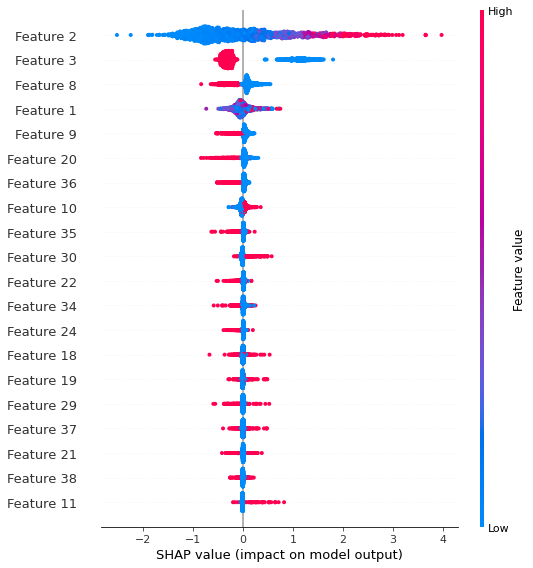

In [177]:
shap.summary_plot(shap_values, X_test_XGB_std)


In [106]:
#global :
shap.force_plot(explainer.expected_value, shap_values, X_test_XGB_std)


In [107]:
xtrain_columns_opt

['log_PropertyGFATotal',
 'Electricity',
 'Warehouse',
 'Supermarket_Grocery Store',
 'log_NumberofFloors',
 'Small- and Mid-Sized Office',
 'Self_Storage Facility',
 '1980_1989',
 '1970_1979',
 'Distribution Center',
 'DOWNTOWN',
 'Mixed Use Property',
 'Worship Facility',
 'EAST',
 '1950_1959',
 'Large Office',
 '1920_1929',
 'Hotel',
 'Restaurant',
 '2010_2019',
 'SOUTHWEST',
 'DELRIDGE',
 'NORTHEAST',
 '1930_1939',
 'NORTH']

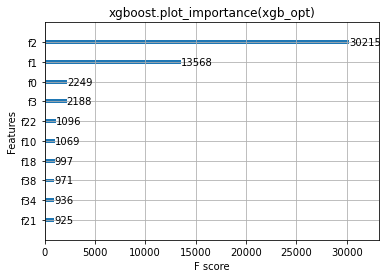

In [272]:
xgboost.plot_importance(xgb_opt,max_num_features=10)
plt.title("xgboost.plot_importance(xgb_opt)")
plt.show()

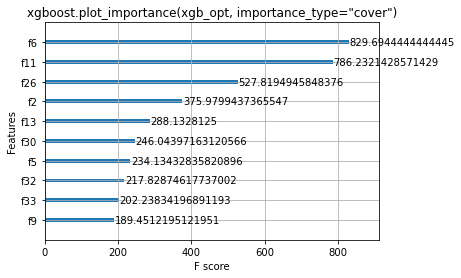

In [284]:
xgboost.plot_importance(xgb_opt, importance_type="cover",max_num_features=10)
plt.title('xgboost.plot_importance(xgb_opt, importance_type="cover")')
plt.show()

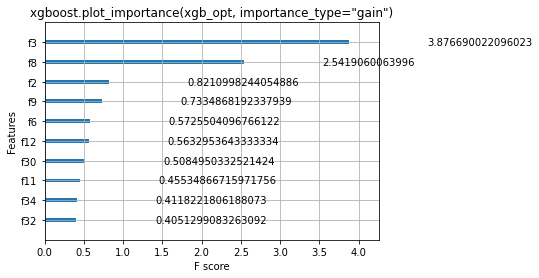

In [273]:
xgboost.plot_importance(xgb_opt, importance_type="gain",max_num_features=10)
plt.title('xgboost.plot_importance(xgb_opt, importance_type="gain")')
plt.show()


# parameter grid
param_grid = { 
    'n_estimators':[100,1000,10000], 
    'max_depth':[2,3,4,5,6,7,8]
}

# score used to select the best model
score = 'neg_mean_squared_error'

# initialise cross-validation
grid_pred_XGB = model_selection.GridSearchCV(
        estimator=xgboost.XGBRegressor,
        param_grid=param_grid,
        cv=5,
        scoring=score)
                                    



grid_pred_XGB.best_params_

# run cross-validation on the training set
grid_pred_XGB.fit(X_train_XGB_std, y_train_XGB)

# predict on the test set with the selected model
y_test_pred_cv_XGB = grid_pred.predict(X_test_XGB_std)

# compute the corresponding RMSE
rmse_cv = np.sqrt(metrics.mean_squared_error(y_test_XGB, y_test_pred_cv_XGB))

In [271]:
# DONE : 

#### R2 scores for each model: metrics.r2_score

#### evaluate the RMSE (root mean square error): metrics.mean_squared_error(y_true, y_pred)

#### Start with simple models: DummyRegressor and LinearRegression.

#### Variable de sortie : Site Energy Use, GHG Emission

#### Log-transform the targets to change the shape of the distribution (extreme values inflate the RMSE).
    ## keep the high-RMSE model, then re-run with the log.
        #Done for the initial models.
        #Done for kernel SVM.
        #done for Random Forest
        #done for kernel SVM
        #done for KNN
        #done for Gradient Boosting

        
#### possibly add one or two models: XGBoost - neural network
        
#### ROC curves for each model --> not a binary classifier: not relevant

#### search for optimal parameters (and show how the score changes with some parameters): cross-validation
    # algo de Cross val ok

    
#### run time of each model (especially the best-parameter search)

#### Re-run the models on Site Energy Use
    
    
# TO DO


#### find the best parameters for each model with best_params
    ### adjust the parameter ranges

#### plot errors against the model variables
        
### Use skewness to decide whether to log-transform values based on their distribution (log if too skewed)



In [272]:
df_NRJ.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,YearBuilt,log_GHGEmissions(MetricTonsCO2e),NumberofBuildings,NumberofFloors,PropertyGFATotal,ENERGYSTARScore,SiteEnergyUse(kBtu),GHGEmissions(MetricTonsCO2e),Electricity,Steam,NaturalGas,Campus,Multifamily HR (10+),Multifamily LR (1-4),Multifamily MR (5-9),NonResidential,Nonresidential COS,Nonresidential WA,SPS-District K-12,BALLARD,Ballard,CENTRAL,Central,DELRIDGE,DELRIDGE NEIGHBORHOODS,DOWNTOWN,Delridge,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,North,Northwest,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019
count,6532.000000,6532.000000,6519.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6.532000e+03,4956.000000,6.532000e+03,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.00000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000,6532.000000
mean,20959.375689,2015.490508,98116.817763,4.464789,1968.182639,3.486109,1.072719,4.744948,9.334938e+04,67.586158,5.258070e+06,116.127936,0.789651,0.009186,0.201164,0.007042,0.032915,0.307103,0.172076,0.442131,0.022811,0.000153,0.015769,0.038273,0.000919,0.034293,0.00398,0.024189,0.000153,0.173301,0.000612,0.135181,0.111145,0.075168,0.126914,0.049449,0.079914,0.064758,0.006124,0.001531,0.026638,0.047459,0.081292,0.150337,0.176056,0.105481,0.101041,0.073025,0.312768,0.064299,0.056338,0.091855,0.022198,0.026485,0.062921,0.133344,0.093233,0.128138,0.112829,0.147581,0.060778
std,11826.883702,0.499948,17.786809,2.121732,33.069919,1.499750,1.613963,5.520262,1.891809e+05,27.060981,1.835044e+07,484.567028,0.407588,0.095407,0.400901,0.083629,0.178427,0.461328,0.377475,0.496678,0.149311,0.012373,0.124588,0.191870,0.030296,0.181994,0.06297,0.153646,0.012373,0.378536,0.024740,0.341943,0.314336,0.263683,0.332902,0.216820,0.271181,0.246117,0.078020,0.039100,0.161036,0.212634,0.273304,0.357429,0.380897,0.307195,0.301406,0.260198,0.463656,0.245303,0.230591,0.288844,0.147340,0.160585,0.242839,0.339972,0.290781,0.334269,0.316408,0.354711,0.238940
min,1.000000,2015.000000,98006.000000,1.000000,1900.000000,-2.525729,0.000000,0.000000,1.128500e+04,1.000000,1.144100e+04,0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20004.000000,2015.000000,98105.000000,3.000000,1948.000000,2.249975,1.000000,2.000000,2.837700e+04,52.000000,9.283485e+05,9.487500,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,23089.000000,2015.000000,98115.000000,4.000000,1974.000000,3.503303,1.000000,4.000000,4.387800e+04,75.000000,1.7

# ------------------------------------------------------
# -----------------------------------------------------------
# -----------------------------------------------------------------------

# Re-run the models on Site Energy Use

## Dummy Regressor --> no Hyperopt / Optuna needed

In [114]:
df_NRJ=df_NRJ_initial[df_NRJ_initial['SiteEnergyUse(kBtu)']>0]

df_NRJ['Log_SiteEnergyUse(kBtu)']=np.log(df_NRJ['SiteEnergyUse(kBtu)'])

In [115]:
list(df_NRJ.columns[18:-1])

['Electricity',
 'Steam',
 'NaturalGas',
 'log_NumberofFloors',
 'log_NumberofBuildings',
 'log_PropertyGFATotal',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 'CouncilDistrictCode_1',
 'CouncilDistrictCode_2',
 'CouncilDistrictCode_3',
 'CouncilDistrictCode_4',
 'CouncilDistrictCode_5',
 'CouncilDistrictCode_6',
 'CouncilDistrictCode_7',
 'Decade',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Other',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office

In [116]:



#df_NRJ_NoNan=df_NRJ[~df_NRJ['Log_SiteEnergyUse(kBtu)'].isna()]
df_NRJ_NoNan=df_NRJ

X_DR = df_NRJ_NoNan[xtrain_columns_V2]

from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_DR)
X_DR_std = std_scale.transform(X_DR)

data_std=pd.DataFrame(X_DR_std,columns=xtrain_columns_V2)

data_std=data_std.assign(logGHGEmissions=df_NRJ_NoNan['Log_SiteEnergyUse(kBtu)'])

In [40]:
data_std

,NumberofBuildings,NumberofFloors,PropertyGFATotal,Electricity,Steam,NaturalGas,Campus,Multifamily HR (10+),Multifamily LR (1-4),Multifamily MR (5-9),NonResidential,Nonresidential COS,Nonresidential WA,SPS-District K-12,BALLARD,Ballard,CENTRAL,Central,DELRIDGE,DELRIDGE NEIGHBORHOODS,DOWNTOWN,Delridge,EAST,GREATER DUWAMISH,LAKE UNION,MAGNOLIA / QUEEN ANNE,NORTH,NORTHEAST,NORTHWEST,North,Northwest,SOUTHEAST,SOUTHWEST,CouncilDistrictCode_1,CouncilDistrictCode_2,CouncilDistrictCode_3,CouncilDistrictCode_4,CouncilDistrictCode_5,CouncilDistrictCode_6,CouncilDistrictCode_7,Decade,1900_1909,1910_1919,1920_1929,1930_1939,1940_1949,1950_1959,1960_1969,1970_1979,1980_1989,1990_1999,2000_2009,2010_2019,logGHGEmissions
0,-0.045035,1.315194,-0.025688,0.517435,-0.096232,-0.501481,-0.08417,-0.184384,-0.666427,-0.4556,1.123668,-0.152701,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,-0.012367,2.185521,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,-0.297900,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,1.482943,-1.321056,-0.26199,-0.2442,3.146162,-0.150591,-0.16485,-0.258977,-0.392526,-0.320756,-0.383133,-0.356678,-0.416083,-0.254919,15.758764
1,-0.045035,1.133942,0.054344,-1.932608,-0.096232,1.994093,-0.08417,-0.184384,-0.666427,-0.4556,1.123668,-0.152701,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,-0.012367,2.185521,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,-0.297900,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,1.482943,0.796418,-0.26199,-0.2442,-0.317848,-0.150591,-0.16485,-0.258977,-0.392526,-0.320756,-0.383133,2.803646,-0.416083,-0.254919,15.938279
2,-0.045035,6.571509,4.594496,0.517435,-0.096232,-0.501481,-0.08417,-0.184384,-0.666427,-0.4556,1.123668,-0.152701,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,-0.012367,2.185521,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,-0.297900,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,1.482943,-0.111071,-0.26199,-0.2442,-0.317848,-0.150591,-0.16485,-0.258977,2.547600,-0.320756,-0.383133,-0.356678,-0.416083,-0.254919,18.107758
3,-0.045035,0.952690,-0.169092,-1.932608,10.391503,-0.501481,-0.08417,-0.184384,-0.666427,-0.4556,1.123668,-0.152701,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,-0.012367,2.185521,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,-0.297900,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,1.482943,-1.321056,-0.26199,-0.2442,3.146162,-0.150591,-0.16485,-0.258977,-0.392526,-0.320756,-0.383133,-0.356678,-0.416083,-0.254919,17.155872
4,-0.045035,2.402708,0.140681,-1.932608,-0.096232,1.994093,-0.08417,-0.184384,-0.666427,-0.4556,1.123668,-0.152701,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,-0.012367,2.185521,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,-0.297900,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,1.482943,0.493921,-0.26199,-0.2442,-0.317848,-0.150591,-0.16485,-0.258977,-0.392526,-0.320756,2.610062,-0.356678,-0.416083,-0.254919,16.512102
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6534,-0.045035,-0.678580,-0.396829,0.517435,-0.096232,-0.501481,-0.08417,-0.184384,-0.666427,-0.4556,-0.889943,6.548733,-0.012367,-0.126506,-0.199379,-0.030305,-0.188773,-0.063182,-0.157356,80.857900,-0.457557,-0.02474,-0.395376,-0.353401,-0.285241,-0.381293,-0.227953,-0.294847,-0.262988,-0.078452,-0.039136,-0.165339,-0.22384,3.356828,-0.420374,-0.462437,-0.343744,-0.335058,-0.280512,-0.674335,0.493921,-0.26199,-0.2442,-0.317848,

In [117]:

data_std=data_std[~data_std['logGHGEmissions'].isna()]

X_std_DR = data_std[xtrain_columns_V2]
y_log_DR = data_std['logGHGEmissions']

X_train_std_DR, X_test_std_DR, y_train_log_DR, y_test_log_DR = train_test_split(X_std_DR, y_log_DR, random_state=0)


dummy_regr = DummyRegressor(strategy="mean")

start_time = timeit.default_timer()

dummy_regr.fit(X_train_std_DR, y_train_log_DR)
elapsed = timeit.default_timer() - start_time

print(elapsed)

y_log_predict_DR=dummy_regr.predict(X_test_std_DR)

# R2 :
print("r2_score (dummy mean): {:.2f}".format(r2_score(y_test_log_DR, y_log_predict_DR)))

# RMSE : 
print("Mean squared error (linear model): {:.2f}".format(mean_squared_error(y_test_log_DR, y_log_predict_DR)))

0.00034960000016326376
r2_score (dummy mean): -0.02
Mean squared error (linear model): 1.20


## Linear Regression --> no Hyperopt / Optuna needed

In [119]:

X_LR = df_NRJ_NoNan[xtrain_columns_V2]

from sklearn import preprocessing
std_scale = preprocessing.StandardScaler().fit(X_LR)
X_LR_std = std_scale.transform(X_LR)

abc=list(df_NRJ_NoNan['Log_SiteEnergyUse(kBtu)'])

data_std=pd.DataFrame(X_LR_std,columns=xtrain_columns_V2)

data_std=data_std.assign(logSiteEnergyUse=df_NRJ_NoNan['Log_SiteEnergyUse(kBtu)'])



df_NRJ_NoNan=df_NRJ[~df_NRJ['Log_SiteEnergyUse(kBtu)'].isna()]

mod = sm.regression.linear_model.OLS.from_formula(
    #formula='logSiteEnergyUse ~ NumberofFloors+PropertyGFATotal+Electricity+Steam+NaturalGas+Campus+Q("Multifamily HR (10+)")+Q("Multifamily LR (1-4)")+Q("Multifamily MR (5-9)")+NonResidential+Q("Nonresidential COS")+Q("Nonresidential WA")+Q("SPS-District K-12")+BALLARD+Ballard+CENTRAL+Central+DELRIDGE+Q("DELRIDGE NEIGHBORHOODS")+DOWNTOWN+Delridge+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+North+Northwest+SOUTHEAST+SOUTHWEST+CouncilDistrictCode_1+CouncilDistrictCode_2+CouncilDistrictCode_3+CouncilDistrictCode_4+CouncilDistrictCode_5+CouncilDistrictCode_6+CouncilDistrictCode_7+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")',
    formula= 'logSiteEnergyUse ~ log_NumberofFloors+log_PropertyGFATotal+Electricity+Steam+NaturalGas+BALLARD+CENTRAL+DELRIDGE+DOWNTOWN+EAST+Q("GREATER DUWAMISH")+Q("LAKE UNION")+Q("MAGNOLIA / QUEEN ANNE")+NORTH+NORTHEAST+NORTHWEST+SOUTHEAST+SOUTHWEST+Q("1900_1909")+Q("1910_1919")+Q("1920_1929")+Q("1930_1939")+Q("1940_1949")+Q("1950_1959")+Q("1960_1969")+Q("1970_1979")+Q("1980_1989")+Q("1990_1999")+Q("2000_2009")+Q("2010_2019")+Q("College/University")+Q("Distribution Center")+Hospital+Hotel+Q("K_12 School")+Laboratory+Q("Large Office")+Q("Low-Rise Multifamily")+Q("Medical Office")+Q("Mixed Use Property")+Other+Q("Residence Hall/Dormitory")+Restaurant+Q("Retail Store")+Q("Self_Storage Facility")+Q("Senior Care Community")+Q("Small- and Mid-Sized Office")+Q("Supermarket_Grocery Store")+Warehouse+Q("Worship Facility")',
                                 
    data=data_std)


start_time = timeit.default_timer()

res=mod.fit()

elapsed = timeit.default_timer() - start_time

print(elapsed)

print(res.summary())

0.004213000000163447
                            OLS Regression Results                            
Dep. Variable:       logSiteEnergyUse   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     12.54
Date:                Tue, 14 Sep 2021   Prob (F-statistic):           1.40e-83
Time:                        15:06:03   Log-Likelihood:                -3395.5
No. Observations:                2501   AIC:                             6887.
Df Residuals:                    2453   BIC:                             7167.
Df Model:                          47                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

## Kernel ridge regression --> singular matrix error (non-invertible matrix?) - partly fixed, still a bit unstable
## Optuna not done

###### https://github.com/marcotcr/lime/issues/388

<AxesSubplot:>

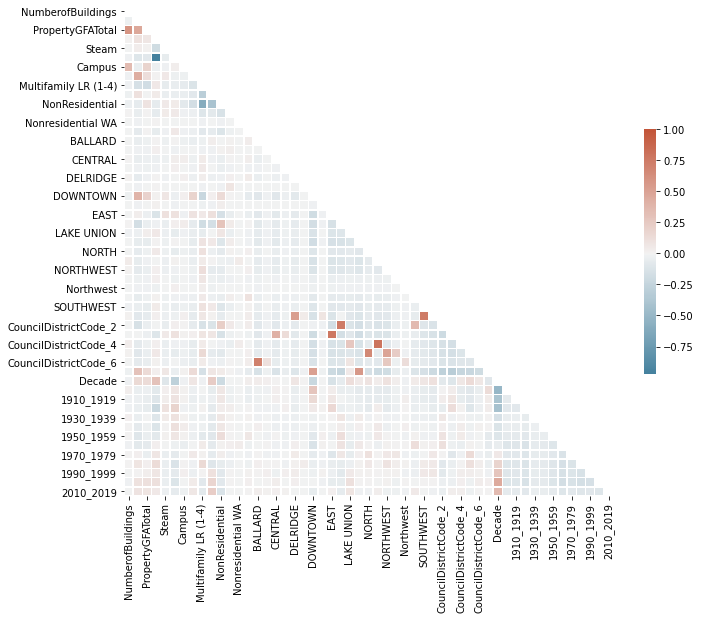

In [52]:
## correlation matrix:

dfcorr1=df_NRJ[xtrain_columns]


corr1 = dfcorr1.corr()

corr1


# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr1, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr1, mask=mask, cmap=cmap, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [53]:
xtrain_columns

['NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'Campus',
 'Multifamily HR (10+)',
 'Multifamily LR (1-4)',
 'Multifamily MR (5-9)',
 'NonResidential',
 'Nonresidential COS',
 'Nonresidential WA',
 'SPS-District K-12',
 'BALLARD',
 'Ballard',
 'CENTRAL',
 'Central',
 'DELRIDGE',
 'DELRIDGE NEIGHBORHOODS',
 'DOWNTOWN',
 'Delridge',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'North',
 'Northwest',
 'SOUTHEAST',
 'SOUTHWEST',
 'CouncilDistrictCode_1',
 'CouncilDistrictCode_2',
 'CouncilDistrictCode_3',
 'CouncilDistrictCode_4',
 'CouncilDistrictCode_5',
 'CouncilDistrictCode_6',
 'CouncilDistrictCode_7',
 'Decade',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019']

In [120]:
df_NRJ_NoNan=df_NRJ[~df_NRJ['Log_SiteEnergyUse(kBtu)'].isna()]

X_Ridge = df_NRJ_NoNan[xtrain_columns_V2]
y_Ridge = df_NRJ_NoNan['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_Ridge, X_test_Ridge, y_train_Ridge, y_test_Ridge = \
    model_selection.train_test_split(X_Ridge, y_Ridge, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_Ridge_std = std_scale.transform(X_train_Ridge)
X_test_Ridge_std = std_scale.transform(X_test_Ridge)

X_Ridge_std=std_scale.transform(X_Ridge)


from sklearn import kernel_ridge
predicteur_Ridge = kernel_ridge.KernelRidge(
    alpha=1.0, # default value
    kernel='rbf', # noyau Gaussien
    gamma=0.01)   # valeur de 1/(2 * sigma**2)

In [121]:

                                     
# train the model on the training set
predicteur_Ridge.fit(X_train_Ridge_std, y_train_Ridge)

# predict on the test set
y_test_Ridge_pred = predicteur_Ridge.predict(X_test_Ridge_std)

# compute the RMSE on the test set
from sklearn import metrics
rmse = np.sqrt(metrics.mean_squared_error(y_test_Ridge, y_test_Ridge_pred))
print("RMSE: {:.2f}".format(rmse))

RMSE: 0.85


In [122]:
print("R2 : "+str(r2_score(y_test_Ridge, y_test_Ridge_pred)))

R2 : 0.3558448174923642


In [58]:
# HyperOpt and Optuna

In [127]:
## HyperOpt model
start_time = timeit.default_timer()

seed=2

#predicteur_Ridge = kernel_ridge.KernelRidge(
#    alpha=1.0, # default value
#    kernel='rbf', # noyau Gaussien
#    gamma=0.01)   # valeur de 1/(2 * sigma**2)


def objective(params):
    alpha=float(params['alpha'])
    gamma=float(params['gamma'])
    kernel=(params['kernel'])
    
    model=kernel_ridge.KernelRidge(alpha=alpha,kernel=kernel,gamma=gamma)
    model.fit(X_train_Ridge_std, y_train_Ridge)
    pred=model.predict(X_test_Ridge_std)
    #score_RMSE=mean_squared_error(y_test_Ridge, pred)
    #score_R2=model.score(X_test_Ridge_std, y_test_Ridge)
    #return score_RMSE
    #return score_R2

def optimize(trial):
    params={'alpha':hp.uniform('alpha',0.001,10),
           'gamma':hp.uniform('gamma',0.001,20),
           'kernel':hp.choice('kernel', ['linear', 'sigmoid', 'poly', 'rbf'])}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=10,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)



elapsed = timeit.default_timer() - start_time

print(elapsed)


  0%|                                                                           | 0/10 [00:00<?, ?trial/s, best loss=?]

  0%|                                                                           | 0/10 [00:00<?, ?trial/s, best loss=?]


In [60]:
best

{'alpha': 2.27777168033349, 'gamma': 3.9921113902317873, 'kernel': 2}

In [182]:
# To be completed


Ridge_opt=kernel_ridge.KernelRidge(alpha= 2.27777168033349, gamma=3.9921113902317873, kernel='poly')
    #n_estimators=270,max_depth=13,eta=0.11,subsample=1,colsample_bytree=1)

start_time = timeit.default_timer()
  
Ridge_opt.fit(X_train_Ridge_std, y_train_Ridge)

elapsed = timeit.default_timer() - start_time

print(elapsed)  

pred_Ridge_opt=Ridge_opt.predict(X_test_Ridge_std)
score_RMSE_Ridge_opt=mean_squared_error(y_test_Ridge,pred_Ridge_opt)
score_R2_Ridge_opt=Ridge_opt.score(X_test_Ridge_std, y_test_Ridge)

0.23281479999968724


In [124]:
score_RMSE_Ridge_opt

69.42640420248183

In [125]:
score_R2_Ridge_opt

-60.56959450769086

## Random Forest --> Hyperopt in place, to be optimised, Optuna not done

In [130]:
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor(max_features=0.5,n_estimators=100,max_depth=10.0,min_samples_leaf=1,min_samples_split=2,n_jobs=1)

In [145]:
X_RF = df_NRJ[xtrain_columns_V2]
y_RF_log = df_NRJ['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_RF, X_test_RF, y_train_RF_log, y_test_RF_log = \
    model_selection.train_test_split(X_RF, y_RF_log, test_size=0.2)

std_scale = preprocessing.StandardScaler().fit(X_train_RF)
X_train_RF_std = std_scale.transform(X_train_RF)
X_test_RF_std = std_scale.transform(X_test_RF)

X_RF_std=std_scale.transform(X_RF)

model = rfr.fit(X_train_RF_std, y_train_RF_log)

pred = rfr.predict(X_test_RF_std)

metrics.mean_squared_error(y_test_RF_log, pred)

0.2998082711680058

In [146]:
rfr.score(X_test_RF_std, y_test_RF_log)

0.7254864288771916

In [138]:
# HyperOpt

In [139]:
start_time = timeit.default_timer()



seed=2

def objective(params):
    mf=float(params['max_features'])
    est=int(params['n_estimators'])
    md=float(params['max_depth'])
    msl=int(params['min_samples_leaf'])
    mss=int(params['min_samples_split'])
    nj=(params['n_jobs'])
    
    model=RandomForestRegressor(max_features=mf,n_estimators=est,max_depth=md,min_samples_leaf=msl,min_samples_split=mss,n_jobs=nj)
    model.fit(X_train_RF_std, y_train_RF_log)
    pred=model.predict(X_test_RF_std)
    score_RMSE=mean_squared_error(y_test_RF_log, pred)
    score_R2=model.score(X_test_RF_std, y_test_RF_log)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'max_features':hp.uniform('max_features',0.0,1.0),
           'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5.0,20.0),
           'min_samples_leaf':hp.uniform('min_samples_leaf',1,5),
           'min_samples_split':hp.uniform('min_samples_split',2.0,6.0),
           'n_jobs':hp.choice('n_jobs',[-1,1])}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=20,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|████████████████████████████████████████████████| 20/20 [00:14<00:00,  1.40trial/s, best loss: 0.2814171876955242]
14.251471400000355


In [109]:
best

{'max_depth': 17.345603882956127,
 'max_features': 0.47194067017666297,
 'min_samples_leaf': 1.583631945561164,
 'min_samples_split': 2.373167820699558,
 'n_estimators': 284.3372366080888,
 'n_jobs': 1}

In [181]:
rfr_opt=RandomForestRegressor(max_features=0.8,n_estimators=200,max_depth=19,
                              min_samples_leaf=2,min_samples_split=3)

start_time = timeit.default_timer()

rfr_opt.fit(X_train_RF_std, y_train_RF_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)

pred_rfr_opt=rfr_opt.predict(X_test_RF_std)
score_RMSE_rfr_opt=mean_squared_error(y_test_RF_log,pred_rfr_opt)
score_R2_rfr_opt=rfr_opt.score(X_test_RF_std, y_test_RF_log)


1.1941477999998824


In [148]:
score_RMSE_rfr_opt

0.2655593426599327

In [149]:
score_R2_rfr_opt

0.7568457894286967

In [113]:
# Optuna

In [114]:
# feature weights: SHAP

In [148]:
# SHAP too slow, try LIME
#explainer = shap.Explainer(rfr_opt)
#shap_values = explainer.shap_values(X_train_RF_std)
#shap.plots.waterfall(shap_values[0])

In [ ]:
# feature weights: LIME

In [150]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train_RF_std, mode='regression',training_labels=y_train_RF_log, 
                                                   feature_names=xtrain_columns_V2) #, categorical_features=['CHAS'])
explanation = explainer.explain_instance(X_test_RF_std[0], rfr_opt.predict)
explanation.show_in_notebook()

<IPython.core.display.HTML object>

In [ ]:
#explain_instance(data_row, predict_fn, labels=(1, ), 
#                 top_labels=None, num_features=10, num_samples=5000, distance_metric='euclidean', model_regressor=None, sampling_method='gaussian')

In [77]:
rfr_opt.predict(X_test_RF_std)

array([14.36755118, 13.63497201, 13.58896482, ..., 14.14072628,
       14.29441465, 14.49360561])

In [80]:
len(pred_rfr_opt)

1962

In [81]:
len(X_test_RF_std[0])

45

In [153]:
xtrain_columns_V2

['log_NumberofFloors',
 'log_PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019',
 'College/University',
 'Distribution Center',
 'Hospital',
 'Hotel',
 'K_12 School',
 'Laboratory',
 'Large Office',
 'Low-Rise Multifamily',
 'Medical Office',
 'Mixed Use Property',
 'Other',
 'Residence Hall/Dormitory',
 'Restaurant',
 'Retail Store',
 'Self_Storage Facility',
 'Senior Care Community',
 'Small- and Mid-Sized Office',
 'Supermarket_Grocery Store',
 'Warehouse',
 'Worship Facility']

In [150]:
# init :
shap.initjs()

<IPython.core.display.HTML object>

In [151]:
explainer = shap.TreeExplainer(rfr_opt)
shap_values = explainer.shap_values(X_test_RF_std)

In [ ]:
# unique value :
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_RF_std[0,:])

In [152]:
# global : 
shap.force_plot(explainer.expected_value, shap_values, X_test_RF_std)

## Gradient Boosting --> Hyperopt optimised, Optuna not done

In [183]:
X_GB = df_NRJ[xtrain_columns_V2]
y_GB = df_NRJ['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_GB, X_test_GB, y_train_GB_log, y_test_GB_log = \
    model_selection.train_test_split(X_GB, y_GB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_Ridge)
X_train_GB_std = std_scale.transform(X_train_GB)
X_test_GB_std = std_scale.transform(X_test_GB)

X_GB_std=std_scale.transform(X_GB)

est = GradientBoostingRegressor(n_estimators=100, learning_rate=0.01,
    max_depth=3, random_state=0, loss='ls').fit(X_train_GB_std, y_train_GB_log)

mean_squared_error(y_test_GB_log, est.predict(X_test_GB_std))

0.6161389437608302

In [184]:
metrics.r2_score(y_test_GB_log, est.predict(X_test_GB_std))

0.5535588315220688

In [ ]:
# HyperOpt and Optuna

In [185]:
start_time = timeit.default_timer()


seed=2


def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    lr=float(params['learning_rate'])
    rs=int(params['random_state'])
    loss=(params['loss'])
    
    model=GradientBoostingRegressor(n_estimators=est,max_depth=md,learning_rate=lr,random_state=rs,loss=loss)
    model.fit(X_train_GB_std, y_train_GB_log)
    pred=model.predict(X_test_GB_std)
    score_RMSE=mean_squared_error(y_test_GB_log, pred)
    score_R2=model.score(X_test_GB_std, y_test_GB_log)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'n_estimators':hp.uniform('n_estimators',50,500),
           'max_depth':hp.uniform('max_depth',1,20),
           'learning_rate':hp.uniform('learning_rate',0.01,1),
           'random_state':hp.uniform('random_state',0,10),
           'loss':hp.choice('loss', ['ls'])}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=10,rstate=np.random.RandomState(seed))
    return best


trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|████████████████████████████████████████████████| 10/10 [00:33<00:00,  3.36s/trial, best loss: 0.2373077718913183]
33.62681919999977


In [186]:
best

{'learning_rate': 0.10564985799355488,
 'loss': 0,
 'max_depth': 11.71459328341884,
 'n_estimators': 241.91305414105236,
 'random_state': 5.267042605674003}

In [187]:

gb_opt=GradientBoostingRegressor(n_estimators=242,max_depth=12,learning_rate=0.11,random_state=5,loss='ls')
gb_opt.fit(X_train_GB_std, y_train_GB_log)
pred_gb_opt=gb_opt.predict(X_test_GB_std)
score_RMSE_gb_opt=mean_squared_error(y_test_GB_log,pred_gb_opt)
score_R2_gb_opt=gb_opt.score(X_test_GB_std, y_test_GB_log)

In [188]:
score_RMSE_gb_opt

0.2423053218962587

In [189]:
score_R2_gb_opt

0.8244307195135228

## Kernel SVM  --> too slow, no Hyperopt  --> similar issue to KernelRidge? /// side note on this algorithm.

In [128]:
X_SVM = df_NRJ[xtrain_columns_V2]
y_SVM_log = df_NRJ['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_SVM, X_test_SVM, y_train_SVM_log, y_test_SVM_log = \
    model_selection.train_test_split(X_SVM, y_SVM_log, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_SVM)
X_train_SVM_std = std_scale.transform(X_train_SVM)
X_test_SVM_std = std_scale.transform(X_test_SVM)

X_SVM_std=std_scale.transform(X_SVM)


# Create an SVM with a Gaussian kernel, gamma=0.01
from sklearn import svm
SVM_regressor = svm.SVR(kernel='rbf', gamma=0.01)

# Train the SVM on the training set
SVM_regressor.fit(X_train_SVM_std, y_train_SVM_log)

# predict on the test set
y_test_SVM_pred_log = SVM_regressor.predict(X_test_SVM_std)

metrics.r2_score(y_test_SVM_log, y_test_SVM_pred_log)



0.5897512189430381

In [129]:
metrics.mean_squared_error(y_test_SVM_log,y_test_SVM_pred_log)

0.5086568688777535

In [67]:
# HyperOpt

In [ ]:
import sklearn

X = X_train_SVM_std
y = y_train_SVM_log
def hyperopt_train_test(params):
    clf = svm.SVR(**params)
    return sklearn.model_selection.cross_val_score(clf, X, y).mean()
space4svm = {
    'C': hp.uniform('C', 0, 20),
    'kernel': hp.choice('kernel', ['linear', 'sigmoid', 'poly', 'rbf']),
    'gamma': hp.uniform('gamma', 0, 20),
}
def f(params):
    acc = hyperopt_train_test(params)
    return {'loss': -acc, 'status': STATUS_OK}
trials = Trials()
best = fmin(f, space4svm, algo=tpe.suggest, max_evals=10, trials=trials)
print ('best:')
best

 30%|██████████████▍                                 | 3/10 [00:19<00:44,  6.40s/trial, best loss: -0.5438789102371229]

In [ ]:
## HyperOpt model


seed=2

def objective(params):
    C=int(params['C'])
    kernel=params['kernel']
    gamma=float(params['gamma'])

    
    #model=xgboost.XGBRegressor(n_estimators=est,max_depth=md,eta=eta,subsample=sbs,colsample_bytree=csb)
    model=svm.SVR(C=C,kernel=kernel,gamma=gamma)
    model.fit(X_train_SVM_std, y_train_SVM_log)
    pred=model.predict(X_test_SVM_std)
    score_RMSE=mean_squared_error(y_test_SVM_log, pred)
    score_R2=model.score(X_test_SVM_std, y_test_SVM_log)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'C':hp.uniform('C',1,20),
           'kernel':hp.choice('kernel', ['linear', 'sigmoid', 'poly', 'rbf']),
           'gamma': hp.uniform('gamma', 0, 20)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=10,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


 50%|████████████████████████▌                        | 5/10 [01:50<01:12, 14.43s/trial, best loss: 0.6066378605837776]

In [180]:
rfr_opt=svm.SVR(C=17.429091147084115, gamma=15.28083107419472, kernel='rbf')

start_time = timeit.default_timer()

rfr_opt.fit(X_train_SVM_std, y_train_SVM_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)
pred_rfr_opt=rfr_opt.predict(X_test_SVM_std)
score_RMSE_rfr_opt=mean_squared_error(y_test_SVM_log,pred_rfr_opt)
score_R2_rfr_opt=rfr_opt.score(X_test_SVM_std, y_test_SVM_log)

0.29224229999999807


In [ ]:
#metrics.r2_score(y_test_SVM_log, y_test_SVM_pred_log)

#metrics.mean_squared_error(y_test_SVM_log,y_test_SVM_pred_log)

In [ ]:
score_RMSE_rfr_opt

In [177]:
score_R2_rfr_opt

0.5567812599969109

In [ ]:
# Optuna

## KNN --> Hyperopt in place, to be optimised, Optuna not done

<function matplotlib.pyplot.show(close=None, block=None)>

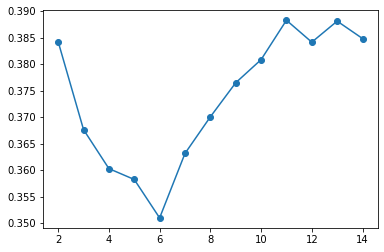

In [154]:
X_KNN = df_NRJ[xtrain_columns_V2]
y_KNN_log = df_NRJ['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_KNN, X_test_KNN, y_train_KNN_log, y_test_KNN_log = \
    model_selection.train_test_split(X_KNN, y_KNN_log, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_KNN)
X_train_KNN_std = std_scale.transform(X_train_KNN)
X_test_KNN_std = std_scale.transform(X_test_KNN)

X_KNN_std=std_scale.transform(X_KNN)


from sklearn import neighbors
knn=neighbors.KNeighborsRegressor(n_neighbors=2)
knn.fit(X_train_KNN_std,y_train_KNN_log)

score=knn.score(X_test_KNN_std,y_test_KNN_log)
score

scores=[]
for k in range(2,15):
    knn=neighbors.KNeighborsRegressor(k)
    scores.append(knn.fit(X_train_KNN_std,y_train_KNN_log).score(X_test_KNN_std,y_test_KNN_log))
plt.plot(range(2,15),scores,'o-')
plt.show


In [155]:
pred_y_knn_log = knn.predict(X_test_KNN_std)

metrics.r2_score(y_test_KNN_log, pred_y_knn_log)


0.38481427234490784

In [156]:
metrics.mean_squared_error(y_test_KNN_log,pred_y_knn_log)

0.7166815051346654

In [213]:
score

0.6076383098395859

In [58]:
# HyperOpt

In [161]:
import sklearn

In [162]:
start_time = timeit.default_timer()


from sklearn import datasets
from sklearn import model_selection

#iris = datasets.load_iris()

X = X_train_KNN_std
y = y_train_KNN_log
def hyperopt_train_test(params):
    knn = neighbors.KNeighborsRegressor(**params)
    return sklearn.model_selection.cross_val_score(knn, X, y).mean()
space4knn = {
    'n_neighbors': hp.choice('n_neighbors', range(2,100))
}
def f(params):
    acc = hyperopt_train_test(params)
    return {'loss': -acc, 'status': STATUS_OK}
trials = Trials()
best = fmin(f, space4knn, algo=tpe.suggest, max_evals=20, trials=trials)


elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|██████████████████████████████████████████████| 20/20 [00:05<00:00,  3.90trial/s, best loss: -0.40189583898031944]
5.152066599999671


In [163]:
print ('best:')
best

best:


{'n_neighbors': 3}

In [164]:
knn=neighbors.KNeighborsRegressor(n_neighbors=3)
knn.fit(X_train_KNN_std,y_train_KNN_log)

score=knn.score(X_test_KNN_std,y_test_KNN_log)
score

0.3676273252776734

In [165]:
pred_y_knn_log = knn.predict(X_test_KNN_std)

metrics.r2_score(y_test_KNN_log, pred_y_knn_log)

0.3676273252776734

In [166]:
metrics.mean_squared_error(y_test_KNN_log,pred_y_knn_log)

0.7367040227892385

In [65]:
# Optuna

In [208]:
start_time = timeit.default_timer()


seed=2

def objective(params):
    k=int(params['n_neighbors'])

    
    model=neighbors.KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_KNN_std,y_train_KNN_log)
    pred=model.predict(X_test_KNN_std)
    score_RMSE=mean_squared_error(y_test_KNN_log, pred)
    score_R2=model.score(X_test_KNN_std, y_test_KNN_log)
    return score_RMSE
    return score_R2


def optimize(trial):
    params={'n_neighbors':hp.uniform('n_neighbors',1,100)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=50,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)

elapsed = timeit.default_timer() - start_time

print(elapsed)

100%|████████████████████████████████████████████████| 50/50 [01:03<00:00,  1.28s/trial, best loss: 0.4179897326812208]
63.99608339999941


In [209]:
best

{'n_neighbors': 1.7879012463083015}

In [179]:

KNN_opt=neighbors.KNeighborsRegressor(n_neighbors=2)

start_time = timeit.default_timer()

KNN_opt.fit(X_train_KNN_std, y_train_KNN_log)

elapsed = timeit.default_timer() - start_time

print(elapsed)

pred_KNN_opt=KNN_opt.predict(X_test_KNN_std)
score_RMSE_KNN_opt=mean_squared_error(y_test_KNN_log,pred_KNN_opt)
score_R2_KNN_opt=KNN_opt.score(X_test_KNN_std, y_test_KNN_log)

0.01949770000010176


In [211]:
score_RMSE_KNN_opt

0.5191594944599576

In [212]:
score_R2_KNN_opt

0.6076383098395859

## XGBoost --> Hyperopt in place and optimised, Optuna not done

In [171]:
# create an xgboost regression model
model = xgboost.XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)

X_XGB = df_NRJ[xtrain_columns_V2]
y_XGB = df_NRJ['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

# fit model
model.fit(X_train_XGB_std, y_train_XGB)

# make a prediction
Xarray=asarray(X_test_XGB_std)

y_pred_XGB = model.predict(Xarray)

metrics.r2_score(y_test_XGB, y_pred_XGB)

0.823802860212792

In [172]:
metrics.mean_squared_error(y_test_XGB, y_pred_XGB)

0.18273440492843931

In [51]:
# Hyperopt

In [52]:
start_time = timeit.default_timer()


seed=2

#model = xgboost.XGBRegressor(n_estimators=1000, max_depth=7, eta=0.1, subsample=0.7, colsample_bytree=0.8)


def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    eta=float(params['eta'])
    sbs=int(params['subsample'])
    csb=int(params['colsample_bytree'])
    
    model=xgboost.XGBRegressor(n_estimators=est,max_depth=md,eta=eta,subsample=sbs,colsample_bytree=csb)
    model.fit(X_train_XGB_std, y_train_XGB)
    pred=model.predict(X_test_XGB_std)
    score_RMSE=mean_squared_error(y_test_XGB, pred)
    score_R2=model.score(X_test_XGB_std, y_test_XGB)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5,20),
           'eta':hp.uniform('eta',0.01,1),
           'subsample':hp.uniform('subsample',0.1,2),
           'colsample_bytree':hp.uniform('colsample_bytree',0.1,2)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=50,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


elapsed = timeit.default_timer() - start_time

print(elapsed)


100%|████████████████████████████████████████████████| 50/50 [01:00<00:00,  1.21s/trial, best loss: 0.1852930524393239]
60.56676049999999


In [53]:
best

{'colsample_bytree': 1.868010660054501,
 'eta': 0.2324430405803261,
 'max_depth': 15.051758211476308,
 'n_estimators': 362.8316725600004,
 'subsample': 1.6305404214553187}

In [178]:
xgb_opt=xgboost.XGBRegressor(n_estimators=180,max_depth=18,eta=0.10,subsample=1,colsample_bytree=1)

start_time = timeit.default_timer()

xgb_opt.fit(X_train_XGB_std, y_train_XGB)

elapsed = timeit.default_timer() - start_time

print(elapsed)

pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

1.2212948999999753


In [174]:
score_RMSE_xgb_opt

0.17773732012884583

In [175]:
score_R2_xgb_opt

0.8286211758950922

In [57]:
# Lime :

In [81]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train_XGB_std, mode='regression',training_labels=y_train_XGB, 
                                                   feature_names=xtrain_columns_V2) #, categorical_features=['CHAS'])

explanation = explainer.explain_instance(X_test_XGB_std[581], xgb_opt.predict)
explanation.show_in_notebook()

<IPython.core.display.HTML object>

In [176]:
explainer = shap.TreeExplainer(xgb_opt)
shap_values = explainer.shap_values(X_test_XGB_std)



In [85]:
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_XGB_std[0,:])


In [177]:
shap.force_plot(explainer.expected_value, shap_values, X_test_XGB_std)


In [75]:
xtrain_columns_V2

['NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'Electricity',
 'Steam',
 'NaturalGas',
 'Campus',
 'Multifamily HR (10+)',
 'Multifamily LR (1-4)',
 'Multifamily MR (5-9)',
 'NonResidential',
 'Nonresidential COS',
 'Nonresidential WA',
 'SPS-District K-12',
 'BALLARD',
 'CENTRAL',
 'DELRIDGE',
 'DELRIDGE NEIGHBORHOODS',
 'DOWNTOWN',
 'EAST',
 'GREATER DUWAMISH',
 'LAKE UNION',
 'MAGNOLIA / QUEEN ANNE',
 'NORTH',
 'NORTHEAST',
 'NORTHWEST',
 'SOUTHEAST',
 'SOUTHWEST',
 '1900_1909',
 '1910_1919',
 '1920_1929',
 '1930_1939',
 '1940_1949',
 '1950_1959',
 '1960_1969',
 '1970_1979',
 '1980_1989',
 '1990_1999',
 '2000_2009',
 '2010_2019']

# ENERGY STAR SCORE (ESS)

In [183]:
xtrain_col_ESS=xtrain_columns_V2+['ENERGYSTARScore']

In [184]:
df_NRJ.isna().sum()

OSEBuildingID                        0
DataYear                             0
BuildingType                         0
PrimaryPropertyType                  0
Address                              0
ZipCode                              0
TaxParcelIdentificationNumber        0
CouncilDistrictCode                  0
Neighborhood                         0
YearBuilt                            0
NumberofBuildings                    0
NumberofFloors                       0
PropertyGFATotal                     0
ENERGYSTARScore                    792
SiteEnergyUse(kBtu)                  0
ComplianceStatus                     0
GHGEmissions(MetricTonsCO2e)         0
ThirdLargestPropertyUseTypeGFA    1275
Electricity                          0
Steam                                0
NaturalGas                           0
log_NumberofFloors                   0
log_NumberofBuildings                0
log_PropertyGFATotal                 0
BALLARD                              0
CENTRAL                  

In [185]:
df_NRJ_STARSCORE=df_NRJ
df_NRJ_STARSCORE['ENERGYSTARScore']=df_NRJ_STARSCORE['ENERGYSTARScore'].replace({np.nan:0})
df_NRJ_STARSCORE=df_NRJ_STARSCORE[df_NRJ_STARSCORE['ENERGYSTARScore']!=0]
df_NRJ_STARSCORE.shape

(1711, 78)

In [186]:
# RMSE and R2 for GHGEmissions with XGBoost, without ENERGYSTARSCORE

In [187]:
df_NRJ_STARSCORE=df_NRJ_STARSCORE[df_NRJ_STARSCORE['GHGEmissions(MetricTonsCO2e)']>0]


df_NRJ_STARSCORE['log_GHGEmissions(MetricTonsCO2e)']=np.log(df_NRJ_STARSCORE['GHGEmissions(MetricTonsCO2e)'])


In [188]:
X_XGB = df_NRJ_STARSCORE[xtrain_columns_V2]
y_XGB = df_NRJ_STARSCORE['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

xgb_opt=xgboost.XGBRegressor(n_estimators=270,max_depth=13,eta=0.11,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

In [189]:
score_RMSE_xgb_opt

0.5105352296451484

In [190]:
score_R2_xgb_opt

0.6982242388490287

In [191]:
# RMSE and R2 for SiteEnergyUse with XGBoost, without ENERGYSTARSCORE

In [192]:
df_NRJ_STARSCORE=df_NRJ_STARSCORE[df_NRJ_STARSCORE['SiteEnergyUse(kBtu)']>0]

df_NRJ_STARSCORE['Log_SiteEnergyUse(kBtu)']=np.log(df_NRJ_STARSCORE['SiteEnergyUse(kBtu)'])


In [193]:
X_XGB = df_NRJ_STARSCORE[xtrain_columns_V2]
y_XGB = df_NRJ_STARSCORE['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

xgb_opt=xgboost.XGBRegressor(n_estimators=180,max_depth=18,eta=0.10,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)


In [194]:
score_RMSE_xgb_opt

0.19756763581973685

In [195]:
score_R2_xgb_opt

0.8007005362393413

In [ ]:
# RMSE and R2 for GHGEmissions with XGBoost, with ENERGYSTARSCORE

In [196]:
X_XGB = df_NRJ_STARSCORE[xtrain_col_ESS]
y_XGB = df_NRJ_STARSCORE['log_GHGEmissions(MetricTonsCO2e)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

xgb_opt=xgboost.XGBRegressor(n_estimators=270,max_depth=13,eta=0.11,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

In [197]:
score_RMSE_xgb_opt

0.31837696311274605

In [198]:
score_R2_xgb_opt

0.765203042288313

In [ ]:
# RMSE and R2 for SiteEnergyUse with XGBoost, with ENERGYSTARSCORE

In [199]:
X_XGB = df_NRJ_STARSCORE[xtrain_col_ESS]
y_XGB = df_NRJ_STARSCORE['Log_SiteEnergyUse(kBtu)']

from sklearn import model_selection
X_train_XGB, X_test_XGB, y_train_XGB, y_test_XGB = \
    model_selection.train_test_split(X_XGB, y_XGB, test_size=0.3)


std_scale = preprocessing.StandardScaler().fit(X_train_XGB)
X_train_XGB_std = std_scale.transform(X_train_XGB)
X_test_XGB_std = std_scale.transform(X_test_XGB)

X_XGB_std=std_scale.transform(X_XGB)

xgb_opt=xgboost.XGBRegressor(n_estimators=180,max_depth=18,eta=0.10,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

In [200]:
score_RMSE_xgb_opt

0.11726156507139575

In [201]:
score_R2_xgb_opt

0.8741969658503249

#Annexe

In [ ]:
## HyperOpt model


seed=2

def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    eta=float(params['eta'])
    sbs=int(params['subsample'])
    csb=int(params['colsample_bytree'])
    
    model=xgboost.XGBRegressor(n_estimators=est,max_depth=md,eta=eta,subsample=sbs,colsample_bytree=csb)
    model.fit(X_train_XGB_std, y_train_XGB)
    pred=model.predict(X_test_XGB_std)
    score_RMSE=mean_squared_error(y_test_XGB, pred)
    score_R2=model.score(X_test_XGB_std, y_test_XGB)
    return score_RMSE
    return score_R2

def optimize(trial):
    params={'n_estimators':hp.uniform('n_estimators',100,500),
           'max_depth':hp.uniform('max_depth',5,20),
           'eta':hp.uniform('eta',0.01,1),
           'subsample':hp.uniform('subsample',0.1,2),
           'colsample_bytree':hp.uniform('colsample_bytree',0.1,2)}
    best=fmin(fn=objective,space=params,algo=tpe.suggest,trials=trial,max_evals=10,rstate=np.random.RandomState(seed))
    return best

trial=Trials()
best=optimize(trial)


xgb_opt=xgboost.XGBRegressor(n_estimators=270,max_depth=13,eta=0.11,subsample=1,colsample_bytree=1)
xgb_opt.fit(X_train_XGB_std, y_train_XGB)
pred_xgb_opt=xgb_opt.predict(X_test_XGB_std)
score_RMSE_xgb_opt=mean_squared_error(y_test_XGB,pred_xgb_opt)
score_R2_xgb_opt=xgb_opt.score(X_test_XGB_std, y_test_XGB)

In [146]:
# Run-time model

start_time = timeit.default_timer()
elapsed = timeit.default_timer() - start_time

print(elapsed)

3.790000027947826e-05


In [ ]:
# LIME model:

In [ ]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train_RF_std, mode='regression',training_labels=y_train_RF_log, 
                                                   feature_names=xtrain_columns_V2) #, categorical_features=['CHAS'])
explanation = explainer.explain_instance(X_test_RF_std[0], rfr_opt.predict)
explanation.show_in_notebook()

In [46]:
# SHAP model:

In [ ]:
# init :
shap.initjs()

explainer = shap.TreeExplainer(xgb_opt)
shap_values = explainer.shap_values(X_test_XGB_std)

# unique value :
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test_XGB_std[0,:])

# global : 
shap.force_plot(explainer.expected_value, shap_values, X_test_XGB_std)


In [181]:
df_NRJ['SiteEnergyUse(kBtu)'].describe()


count    6.531000e+03
mean     5.125064e+06
std      1.487335e+07
min      1.144100e+04
25%      9.282880e+05
50%      1.792425e+06
75%      4.187033e+06
max      4.483853e+08
Name: SiteEnergyUse(kBtu), dtype: float64

In [182]:
df_NRJ['GHGEmissions(MetricTonsCO2e)'].describe()

count     6531.000000
mean       114.439920
std        465.001124
min          0.080000
25%          9.485000
50%         33.220000
75%         91.870000
max      16870.980000
Name: GHGEmissions(MetricTonsCO2e), dtype: float64

In [125]:
# model for permutation_importance

In [ ]:
# look for the most important features to improve the score

from sklearn.inspection import permutation_importance
r = permutation_importance(xgb_opt, X_test_XGB_std, y_test_XGB,
                         n_repeats=30,
                            random_state=0)

r.importances_mean.argsort()[::-1]

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print(f"{df_NRJ_train.columns[i]:<8}"
              f"{r.importances_mean[i]:.3f}"
              f" +/- {r.importances_std[i]:.3f}")

for i in r.importances_mean.argsort()[::-1]:
    if r.importances_mean[i] - 2 * r.importances_std[i] > 0:
        print("'"+f"{df_NRJ_train.columns[i]:<8}"+"',")